# HanuAi ML Assessment - Task 2: Advanced EDA and Text Mining

**Dataset:** `Hanuai_task2_assignment.csv` - 1,000 vehicle warranty claims (infotainment / radio / display concerns).

**What this notebook does**

| Step | Question it answers |
|---|---|
| 1-2 | What is in the data, and what is wrong with it? (profiling, missing values, duplicates, inconsistencies, cleaning) |
| 3 | Which columns matter to stakeholders, and how are they distributed? (statistics + charts) |
| 4 | How do we turn the three free-text narratives into structured tags (component, condition, trigger, context, fix)? |
| 5 | What *types* of issue are there? (taxonomy built from the mined entities) |
| 6 | What patterns, trends and significant changes exist? |
| 7 | Which failure modes cluster together, and what are the likely root causes? (TF-IDF + K-Means, NMF topics, sentence-embedding cross-check) |
| 8-9 | Recommendations with business impact, and the exported tagged dataset |

**How to run:** put `Hanuai_task2_assignment.csv` next to this notebook (or in `../data_raw/`) and run all cells. Everything is seeded (`SEED = 42`) so results reproduce. The sentence-embedding step uses the open-source `all-MiniLM-L6-v2` model; if it cannot be loaded the notebook skips that one cross-check and carries on.

> **Reading guide.** Code cells carry comments explaining *why* each step is done. Numbers quoted in markdown are generated by the code cells above them wherever possible, so they cannot drift from the analysis.

In [1]:
# ---------------------------------------------------------------------------
# 0. Imports, configuration and helpers
# ---------------------------------------------------------------------------
import re, ast, json, warnings, textwrap, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_colwidth", 90)

SEED = 42                      # every stochastic step (K-Means, t-SNE, NMF) uses this seed
np.random.seed(SEED)
FACTS = {}                     # key numbers are collected here and written to outputs/task2_facts.json (the report reads them)

# Plot style: one calm blue for counts, a qualitative palette only where categories need telling apart.
BLUE, GREY, ORANGE = "#2F6DB5", "#8A94A6", "#D9822B"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})

# Locate the data file so the notebook runs from this folder, its parent, or ../data_raw
CANDIDATES = [Path("Hanuai_task2_assignment.csv"), Path("../data_raw/Hanuai_task2_assignment.csv"),
              Path("data_raw/Hanuai_task2_assignment.csv")]
DATA_PATH = next(p for p in CANDIDATES if p.exists())
OUT = Path("outputs"); FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

def savefig(name):
    """Save the current figure for the report (PNG, 150 dpi) and show it inline."""
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def barh_counts(ax, series, title, top=None, color=BLUE, pct_of=None):
    """Horizontal bar chart of value counts with the count (and optional %) printed at the bar end."""
    vc = series.value_counts()
    if top:
        vc = vc.head(top)
    vc = vc.sort_values()
    ax.barh(vc.index.astype(str), vc.values, color=color)
    total = pct_of if pct_of else vc.sum()
    for y, v in enumerate(vc.values):
        ax.text(v, y, f"  {v:,} ({v/total:.0%})", va="center", fontsize=8.5)
    ax.set_title(title); ax.set_xlim(0, vc.max() * 1.3); ax.set_xlabel("claims")

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| data:", DATA_PATH)

Python 3.12.15 | pandas 3.1.0 | data: Hanuai_task2_assignment.csv


## 1. Load the data and profile every column

First pass: *volume, data types and character of each column*. The `role` column below is my reading of what each field actually is (identifier, date, coded category, free text, or one of the pre-defined entity tags), which drives how each is treated later.

In [2]:
raw = pd.read_csv(DATA_PATH)
print(f"Rows: {len(raw):,}   Columns: {raw.shape[1]}")
FACTS["shape"] = list(raw.shape)

# Role of each column, decided after reading the values (not just the names)
ROLE = {
    "Event id": "identifier", "Opened date": "date - claim opened",
    "BUILD_DATE": "date - vehicle built", "IN_USE_DATE": "date - vehicle put in service",
    "CAUSAL_VERBATIM": "FREE TEXT - technician diagnosis", "CORRECTION_VERBATIM": "FREE TEXT - repair performed",
    "CUSTOMER_VERBATIM": "FREE TEXT - customer concern",
    "BUILD_PLANT_DESC": "category - plant name", "PLANT": "category - plant code (duplicate of name)",
    "CAUSAL_CD_DESC": "category - coded cause", "COMPLAINT_CD_DESC": "category - coded complaint",
    "MAKE": "category - make", "MODEL": "category - model", "MODLYR": "numeric - model year (constant)",
    "Trigger": "entity tag (example column)", "Failure Component": "entity tag (example column)",
    "Failure Condition": "entity tag (example column)", "Additional Context": "entity tag (example column)",
    "Fix Component": "entity tag (example column)", "Fix Condition": "entity tag (example column)",
}

profile = pd.DataFrame({
    "role": pd.Series(ROLE),
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "null_%": (raw.isna().mean() * 100).round(1),
    "n_unique": raw.nunique(),
    "example": raw.apply(lambda s: str(s.dropna().iloc[0]).replace("\n", " ")[:55] if s.notna().any() else ""),
}).loc[raw.columns]
profile

Rows: 1,000   Columns: 20


,role,dtype,non_null,null_%,n_unique,example
Event id,identifier,str,1000,0.0,1000,D-14801
Opened date,date - claim opened,str,1000,0.0,397,9/17/2019
CAUSAL_VERBATIM,FREE TEXT - technician diagnosis,str,999,0.1,944,unable to duplicate the concern at this time radio and
CORRECTION_VERBATIM,FREE TEXT - repair performed,str,1000,0.0,952,"waiting for techline engineering response, attempted to"
CUSTOMER_VERBATIM,FREE TEXT - customer concern,str,1000,0.0,990,Customer reports that radio and screen is intermittantl
BUILD_DATE,date - vehicle built,str,1000,0.0,37,2019-08-14T00:00:00.000Z
BUILD_PLANT_DESC,category - plant name,str,1000,0.0,8,Flint
CAUSAL_CD_DESC,category - coded cause,str,997,0.3,38,Module/Component-No/Incorrect Communication
COMPLAINT_CD_DESC,category - coded complaint,str,1000,0.0,9,Audio/Entertainment/Navigation - Other issues
IN_USE_DATE,date - vehicle put in service,str,999,0.1,285,2019-09-10T00:00:00.000Z


In [3]:
# Value ranges of the date columns and what the coded categories look like.
# (Opened date is "M/D/YYYY" text; BUILD_DATE / IN_USE_DATE are ISO timestamps with a trailing Z - a format mismatch handled in section 2.)
for c in ["Opened date", "BUILD_DATE", "IN_USE_DATE"]:
    d = pd.to_datetime(raw[c], format="mixed", utc=True, errors="coerce")
    print(f"{c:12s} {d.min().date()} -> {d.max().date()}   (unparsable: {d.isna().sum()})")

print("\nCardinality of coded categories:")
for c in ["BUILD_PLANT_DESC", "MAKE", "MODEL", "COMPLAINT_CD_DESC", "CAUSAL_CD_DESC"]:
    print(f"  {c:18s} {raw[c].nunique():3d} distinct values")

Opened date  2019-08-27 -> 2021-06-01   (unparsable: 0)
BUILD_DATE   2019-08-01 -> 2019-09-07   (unparsable: 0)
IN_USE_DATE  2019-08-03 -> 2021-03-31   (unparsable: 1)

Cardinality of coded categories:
  BUILD_PLANT_DESC     8 distinct values
  MAKE                 4 distinct values
  MODEL               23 distinct values
  COMPLAINT_CD_DESC    9 distinct values
  CAUSAL_CD_DESC      38 distinct values


**What the profile tells us**

* All 1,000 claims share **one model year (2020)** and were **built in a ~5-week window (Aug-Sep 2019)**, so this is effectively a *single production cohort* observed ageing in the field. Time-in-service is therefore a natural axis for analysis.
* Three columns are free text (`CUSTOMER_VERBATIM`, `CAUSAL_VERBATIM`, `CORRECTION_VERBATIM`). The six entity columns (`Trigger` ... `Fix Condition`) are empty for 995 rows because **only five worked examples were supplied** - they define the tag schema that text mining must reproduce for all rows.
* `MAKE`/`MODEL` are anonymised names; `PLANT` is a code for `BUILD_PLANT_DESC`.

## 2. Data-quality audit and cleaning

Every issue found is written to `qa_log` (exported with the dataset) with the action taken, so the cleaning is auditable.

In [4]:
qa_log = []
def log(issue, columns, n, action):
    qa_log.append({"Issue": issue, "Column(s)": columns, "Rows affected": int(n), "Action taken": action})

# ---- 2.1 Missing values ----------------------------------------------------------------------------
miss = raw.isna().sum()
miss = miss[miss > 0].rename("missing").to_frame()
miss["missing_%"] = (miss.missing / len(raw) * 100).round(1)
display(miss)

n_causal_cd, n_causal_txt, n_inuse = (raw.CAUSAL_CD_DESC.isna().sum(), raw.CAUSAL_VERBATIM.isna().sum(), raw.IN_USE_DATE.isna().sum())
log("Missing coded cause", "CAUSAL_CD_DESC", n_causal_cd, "Kept as its own category 'Not Coded' (mode-imputing would invent a cause)")
log("Missing diagnosis narrative", "CAUSAL_VERBATIM", n_causal_txt, "Set to empty text and flagged (`causal_missing`); mining falls back to the other narratives")
log("Missing in-service date", "IN_USE_DATE", n_inuse, "Imputed as BUILD_DATE + median build->service lag; flagged (`in_use_imputed`) and excluded from time-in-service statistics")
log("Entity-tag columns ~99.5% empty", "Trigger ... Fix Condition", raw["Failure Component"].isna().sum(),
    "Not missing data: only 5 worked examples were supplied. Populated for all rows by text mining (section 4)")

,missing,missing_%
CAUSAL_VERBATIM,1,0.1
CAUSAL_CD_DESC,3,0.3
IN_USE_DATE,1,0.1
Trigger,995,99.5
Failure Component,995,99.5
Failure Condition,995,99.5
Additional Context,995,99.5
Fix Component,995,99.5
Fix Condition,995,99.5


In [5]:
# ---- 2.2 Duplicates ---------------------------------------------------------------------------------
TEXT_COLS = ["CUSTOMER_VERBATIM", "CAUSAL_VERBATIM", "CORRECTION_VERBATIM"]
dups = {
    "Duplicate Event id": int(raw["Event id"].duplicated().sum()),
    "Fully identical rows": int(raw.duplicated().sum()),
    "Identical except Event id": int(raw.drop(columns=["Event id"]).duplicated().sum()),
    "Identical across all 3 narratives": int(raw.duplicated(subset=TEXT_COLS).sum()),
    "Repeated CUSTOMER_VERBATIM (extra copies)": int(raw.CUSTOMER_VERBATIM.duplicated().sum()),
}
display(pd.Series(dups, name="count").to_frame())

# The repeated customer phrases - are they true duplicates or just common short complaints on different vehicles?
rep = raw[raw.CUSTOMER_VERBATIM.duplicated(keep=False)].sort_values("CUSTOMER_VERBATIM")
display(rep[["Event id", "CUSTOMER_VERBATIM", "MODEL", "Opened date", "BUILD_PLANT_DESC"]].head(8))
n_ph = int(raw.CUSTOMER_VERBATIM.fillna("").str.strip().str.match(r"(?i)^(?:audio entertainment navigation|features controls displays)\b").sum())
log("Placeholder instead of a complaint", "CUSTOMER_VERBATIM", n_ph,
    "Text is just the coded category ('Audio Entertainment Navigation Other issues'). Flagged `customer_placeholder`; symptom mining falls back to the diagnosis text")
log("Repeated customer concern text", "CUSTOMER_VERBATIM", dups["Repeated CUSTOMER_VERBATIM (extra copies)"],
    "Kept - same short phrase on different vehicles/dates/plants, with different diagnoses. No true duplicate records exist")

,count
Duplicate Event id,0
Fully identical rows,0
Identical except Event id,0
Identical across all 3 narratives,0
Repeated CUSTOMER_VERBATIM (extra copies),10


,Event id,CUSTOMER_VERBATIM,MODEL,Opened date,BUILD_PLANT_DESC
696,D-14709,Audio Entertainment Navigation Audio,HyperFury X,5/21/2020,Flint
535,D-14752,Audio Entertainment Navigation Audio,HyperFury X,3/9/2020,Fort Wayne
38,D-15027,Audio Entertainment Navigation Other issues,ElectroStreak,3/10/2020,Flint
900,D-14654,Audio Entertainment Navigation Other issues,ElectroStreak,11/7/2019,Silao
858,D-14502,Audio Entertainment Navigation Other issues,HyperFury X,2/9/2021,Flint
966,D-14599,Audio Entertainment Navigation Other issues,HyperFury X,2/13/2020,Flint
735,D-15356,Audio Entertainment Navigation Other issues,NebulaJet,12/28/2020,Silao
797,D-15172,CUSTOMER STATES THE RADIO IS INOP,CelestialVortex,5/28/2021,Flint


In [6]:
# ---- 2.3 Inconsistencies ---------------------------------------------------------------------------
# (a) stray leading/trailing spaces in category labels (would split one category into two)
# NOTE: str.strip() alone is not enough - some labels use NON-BREAKING spaces (\xa0), which look identical on screen
clean_label = lambda s: s.str.replace("\u00a0", " ", regex=False).str.replace(r"\s+", " ", regex=True).str.strip()
ws = {c: int((raw[c].dropna() != clean_label(raw[c].dropna())).sum()) for c in
      ["BUILD_PLANT_DESC", "CAUSAL_CD_DESC", "COMPLAINT_CD_DESC", "MAKE", "MODEL"]}
print("Labels with stray / non-breaking whitespace:", {k: v for k, v in ws.items() if v})
print("  e.g.", repr([x for x in raw.COMPLAINT_CD_DESC.unique() if "Abnormal" in x][0]))
log("Hidden whitespace (non-breaking spaces) in labels", "COMPLAINT_CD_DESC", ws["COMPLAINT_CD_DESC"],
    "Normalised. The 'Abnormal Noise' complaint label used non-breaking spaces, so it had been silently counted as a different category from its normal spelling")

# (b) mixed date formats
log("Mixed date formats", "Opened date vs BUILD_DATE / IN_USE_DATE", len(raw),
    "Opened date is M/D/YYYY text; build/in-use are ISO timestamps. All parsed to a single datetime type")

# (c) logically impossible / suspicious dates
opened = pd.to_datetime(raw["Opened date"], format="%m/%d/%Y")
built = pd.to_datetime(raw.BUILD_DATE, utc=True).dt.tz_localize(None)
inuse = pd.to_datetime(raw.IN_USE_DATE, utc=True).dt.tz_localize(None)
checks = {
    "Claim opened BEFORE vehicle in service": int((opened < inuse).sum()),
    "Claim opened before vehicle built": int((opened < built).sum()),
    "In service before built": int((inuse < built).sum()),
}
display(pd.Series(checks, name="rows").to_frame())
log("Claim opened before in-service date", "Opened date / IN_USE_DATE", checks["Claim opened BEFORE vehicle in service"],
    "Kept (possible pre-delivery repair or date-entry error) but flagged `tis_negative` and excluded from time-in-service statistics")

# (d) constant / redundant columns
print("\nMODLYR distinct values:", raw.MODLYR.unique(), "-> zero variance, dropped from analysis")
print("PLANT <-> BUILD_PLANT_DESC one-to-one:", raw.groupby("PLANT").BUILD_PLANT_DESC.nunique().max() == 1
      and raw.groupby("BUILD_PLANT_DESC").PLANT.nunique().max() == 1, "-> PLANT is redundant")
log("Constant column", "MODLYR", len(raw), "Excluded from analysis (all 2020)")
log("Redundant column", "PLANT", len(raw), "Excluded; BUILD_PLANT_DESC used (1-to-1 with the code)")

# (e) rare models (singletons) and make/model integrity
mm = raw.groupby("MODEL").MAKE.nunique()
print("Models mapped to >1 make:", int((mm > 1).sum()))
rare = raw.MODEL.value_counts()[lambda s: s < 10]
print(f"Models with <10 claims: {len(rare)} ({int(rare.sum())} claims) -> grouped as 'Other (<10 claims)' in charts")
log("Very rare models", "MODEL", int(rare.sum()), f"{len(rare)} models with <10 claims grouped as 'Other (<10 claims)' for charts/tests")

Labels with stray / non-breaking whitespace: {'CAUSAL_CD_DESC': 21, 'COMPLAINT_CD_DESC': 11}
  e.g. '\xa0Audio/Entertainment/Navigation\xa0-\xa0Abnormal\xa0Noise'


,rows
Claim opened BEFORE vehicle in service,76
Claim opened before vehicle built,0
In service before built,0



MODLYR distinct values: [2020] -> zero variance, dropped from analysis
PLANT <-> BUILD_PLANT_DESC one-to-one: True -> PLANT is redundant
Models mapped to >1 make: 0
Models with <10 claims: 7 (26 claims) -> grouped as 'Other (<10 claims)' in charts


In [7]:
# (f) text-quality issues: these decide how the text must be pre-processed in section 4
def share(mask): return round(float(mask.mean()) * 100, 1)
cust = raw.CUSTOMER_VERBATIM.fillna("")
corr = raw.CORRECTION_VERBATIM.fillna("")
letters = lambda s: re.sub(r"[^A-Za-z]", "", s)
text_quality = pd.Series({
    "customer text mostly UPPER-CASE (>70% of letters)": share(cust.map(lambda s: len(letters(s)) > 0 and sum(ch.isupper() for ch in letters(s)) / len(letters(s)) > 0.7)),
    "narratives containing a stripped number (double space)": share((raw[TEXT_COLS].fillna("").agg(" ".join, axis=1)).str.contains(r"\s{2,}")),
    "narratives with very long glued tokens (>=16 chars, e.g. 'atradiothat')": share(raw[TEXT_COLS].fillna("").agg(" ".join, axis=1).str.contains(r"[A-Za-z]{16,}")),
    "narratives with split words (e.g. 'RAD IO', 'RE PLACED')": share(raw[TEXT_COLS].fillna("").agg(" ".join, axis=1).str.contains(r"\b(?:ra dio|rad io|re placed|repl aced|prog ram)\b", case=False)),
    "customer text under 5 words": share(cust.str.split().str.len() < 5),
    "correction text under 5 words": share(corr.str.split().str.len() < 5),
}, name="% of rows").to_frame()
display(text_quality)
FACTS["text_quality"] = text_quality["% of rows"].to_dict()
log("Noisy free text", "CUSTOMER/CAUSAL/CORRECTION_VERBATIM", len(raw),
    "Export removed line-breaks and numbers: glued and split words, mixed case, boiler-plate. Handled by normalisation + corpus-driven fragment repair + substring-tolerant matching (section 4)")

,% of rows
customer text mostly UPPER-CASE (>70% of letters),79.8
narratives containing a stripped number (double space),77.0
"narratives with very long glued tokens (>=16 chars, e.g. 'atradiothat')",21.3
"narratives with split words (e.g. 'RAD IO', 'RE PLACED')",3.1
customer text under 5 words,6.4
correction text under 5 words,12.8


In [8]:
# ---- 2.4 Build the cleaned analysis frame ---------------------------------------------------------------
df = raw.copy()

# normalise hidden/non-breaking whitespace in labels
for c in ["BUILD_PLANT_DESC", "CAUSAL_CD_DESC", "COMPLAINT_CD_DESC", "MAKE", "MODEL"]:
    df[c] = clean_label(df[c])

# one datetime type for all dates
df["opened_date"] = pd.to_datetime(df["Opened date"], format="%m/%d/%Y")
df["build_date"] = pd.to_datetime(df.BUILD_DATE, utc=True).dt.tz_localize(None)
df["in_use_date"] = pd.to_datetime(df.IN_USE_DATE, utc=True).dt.tz_localize(None)

# impute the single missing in-service date from the median build -> service lag, and flag it
median_lag = int((df.in_use_date - df.build_date).dt.days.median())
df["in_use_imputed"] = df.in_use_date.isna()
df.loc[df.in_use_imputed, "in_use_date"] = df.loc[df.in_use_imputed, "build_date"] + pd.Timedelta(days=median_lag)

# customer "narratives" that are just the coded category pasted in (not a real complaint)
df["customer_placeholder"] = df.CUSTOMER_VERBATIM.fillna("").str.strip().str.match(r"(?i)^(?:audio entertainment navigation|features controls displays)\b")

# missing text / codes
df["causal_missing"] = df.CAUSAL_VERBATIM.isna()
df["CAUSAL_VERBATIM"] = df.CAUSAL_VERBATIM.fillna("")
df["CAUSAL_CD_DESC"] = df.CAUSAL_CD_DESC.fillna("Not Coded")

# derived analytics columns
df["build_to_service_days"] = (df.in_use_date - df.build_date).dt.days
df["tis_days"] = (df.opened_date - df.in_use_date).dt.days            # time in service at claim
df["tis_negative"] = df.tis_days < 0
df["tis_days_valid"] = df.tis_days.where(~df.tis_negative & ~df.in_use_imputed)   # only trustworthy values
df["opened_month"] = df.opened_date.dt.to_period("M").dt.to_timestamp()
df["opened_quarter"] = df.opened_date.dt.to_period("Q").astype(str)
df["build_week"] = df.build_date.dt.to_period("W").dt.start_time
df["model_grp"] = df.MODEL.where(df.MODEL.map(df.MODEL.value_counts()) >= 10, "Other (<10 claims)")
df["complaint_short"] = df.COMPLAINT_CD_DESC.str.replace("Audio/Entertainment/Navigation - ", "Audio/Ent/Nav: ", regex=False) \
                                             .str.replace("Features/Controls/Displays - ", "Features/Disp: ", regex=False)

print(f"Cleaned frame: {df.shape[0]:,} rows x {df.shape[1]} cols | imputed in-service dates: {int(df.in_use_imputed.sum())} | "
      f"negative time-in-service: {int(df.tis_negative.sum())} | valid TIS rows: {int(df.tis_days_valid.notna().sum())}")
pd.DataFrame(qa_log)

Cleaned frame: 1,000 rows x 35 cols | imputed in-service dates: 1 | negative time-in-service: 76 | valid TIS rows: 923


,Issue,Column(s),Rows affected,Action taken
0,Missing coded cause,CAUSAL_CD_DESC,3,Kept as its own category 'Not Coded' (mode-imputing would invent a cause)
1,Missing diagnosis narrative,CAUSAL_VERBATIM,1,Set to empty text and flagged (`causal_missing`); mining falls back to the other narra...
2,Missing in-service date,IN_USE_DATE,1,Imputed as BUILD_DATE + median build->service lag; flagged (`in_use_imputed`) and excl...
3,Entity-tag columns ~99.5% empty,Trigger ... Fix Condition,995,Not missing data: only 5 worked examples were supplied. Populated for all rows by text...
4,Placeholder instead of a complaint,CUSTOMER_VERBATIM,8,Text is just the coded category ('Audio Entertainment Navigation Other issues'). Flagg...
5,Repeated customer concern text,CUSTOMER_VERBATIM,10,"Kept - same short phrase on different vehicles/dates/plants, with different diagnoses...."
6,Hidden whitespace (non-breaking spaces) in labels,COMPLAINT_CD_DESC,11,"Normalised. The 'Abnormal Noise' complaint label used non-breaking spaces, so it had b..."
7,Mixed date formats,Opened date vs BUILD_DATE / IN_USE_DATE,1000,Opened date is M/D/YYYY text; build/in-use are ISO timestamps. All parsed to a single ...
8,Claim opened before in-service date,Opened date / IN_USE_DATE,76,Kept (possible pre-delivery repair or date-entry error) but flagged `tis_negative` and...
9,Constant column,MODLYR,1000,Excluded from analysis (all 2020)


## 3. Exploratory analysis of the critical columns

**Which columns matter to a stakeholder?** The decisions this data can inform are: *when* claims arise (`opened_date`, `tis_days`), *where* they come from (`BUILD_PLANT_DESC`, `MODEL`, `MAKE`), *what* is going wrong (`COMPLAINT_CD_DESC`, `CAUSAL_CD_DESC` and, above all, the three narratives), and *what it takes to fix it* (the repair narrative). Identifiers, the constant `MODLYR`, and the duplicate `PLANT` code carry no signal.

> **Important limitation:** there is no production-volume or fleet-size column, so every chart below shows **claim counts, not failure rates**. A plant or model with more claims may simply have built more vehicles.

In [9]:
# ---- 3.1 Summary statistics for the numeric columns -----------------------------------------------------
df["customer_words"] = df.CUSTOMER_VERBATIM.fillna("").str.split().str.len()
df["causal_words"] = df.CAUSAL_VERBATIM.str.split().str.len()
df["correction_words"] = df.CORRECTION_VERBATIM.fillna("").str.split().str.len()

num_cols = ["tis_days_valid", "build_to_service_days", "customer_words", "causal_words", "correction_words"]
summary = df[num_cols].describe(percentiles=[.25, .5, .75, .9]).T
summary["skew"] = df[num_cols].skew()
summary = summary.rename(index={"tis_days_valid": "time in service at claim (days)", "build_to_service_days": "build -> in-service lag (days)",
                                "customer_words": "customer concern (words)", "causal_words": "diagnosis (words)", "correction_words": "repair (words)"})
display(summary.round(1))

tis = df.tis_days_valid.dropna()
print(f"\nTime in service at claim: median {tis.median():.0f} days (~{tis.median()/30.4:.1f} months); "
      f"{(tis<=90).mean():.0%} within 90 days, {(tis<=180).mean():.0%} within 180 days, {(tis<=365).mean():.0%} within a year.")
FACTS["tis"] = {"median": float(tis.median()), "mean": float(tis.mean()), "n_valid": int(len(tis)), "le90": float((tis <= 90).mean()), "le180": float((tis <= 180).mean()),
                "le365": float((tis <= 365).mean()), "negative": int(df.tis_negative.sum()), "build_to_service_median": float(df.build_to_service_days.median())}
FACTS["date_ranges"] = {"opened": [str(df.opened_date.min().date()), str(df.opened_date.max().date())], "built": [str(df.build_date.min().date()), str(df.build_date.max().date())]}

,count,mean,std,min,25%,50%,75%,90%,max,skew
time in service at claim (days),923.0,241.4,160.9,0.0,106.0,227.0,364.5,470.8,615.0,0.3
build -> in-service lag (days),1000.0,121.1,99.5,1.0,46.0,91.0,164.2,283.0,596.0,1.3
customer concern (words),1000.0,17.3,13.8,2.0,8.0,14.0,22.0,34.0,123.0,2.7
diagnosis (words),1000.0,22.3,28.8,0.0,5.0,13.0,28.0,51.1,285.0,3.3
repair (words),1000.0,28.6,36.1,1.0,7.0,15.0,36.0,69.0,308.0,3.1



Time in service at claim: median 227 days (~7.5 months); 21% within 90 days, 43% within 180 days, 75% within a year.


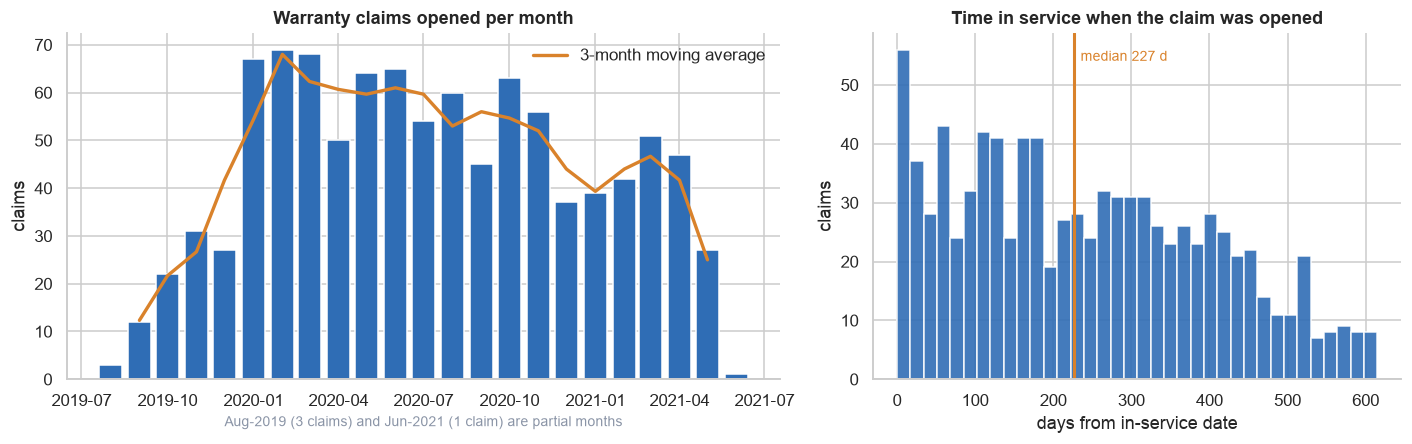

In [10]:
# ---- 3.2 Claims over time + time-in-service distribution -------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.35, 1]})

monthly = df.groupby("opened_month").size()
FACTS["monthly"] = {str(k.date())[:7]: int(v) for k, v in monthly.items()}
ax = axes[0]
ax.bar(monthly.index, monthly.values, width=24, color=BLUE)
ax.plot(monthly.index, monthly.rolling(3, center=True).mean(), color=ORANGE, lw=2.2, label="3-month moving average")
ax.set_title("Warranty claims opened per month"); ax.set_ylabel("claims"); ax.legend(frameon=False)
ax.set_xlabel("Aug-2019 (3 claims) and Jun-2021 (1 claim) are partial months", fontsize=9, color=GREY)

ax = axes[1]
ax.hist(tis, bins=36, color=BLUE, alpha=.9)
ax.axvline(tis.median(), color=ORANGE, lw=2); ax.text(tis.median() + 8, ax.get_ylim()[1] * .92, f"median {tis.median():.0f} d", color=ORANGE, fontsize=9)
ax.set_title("Time in service when the claim was opened"); ax.set_xlabel("days from in-service date"); ax.set_ylabel("claims")
savefig("fig01_claims_over_time_and_tis")

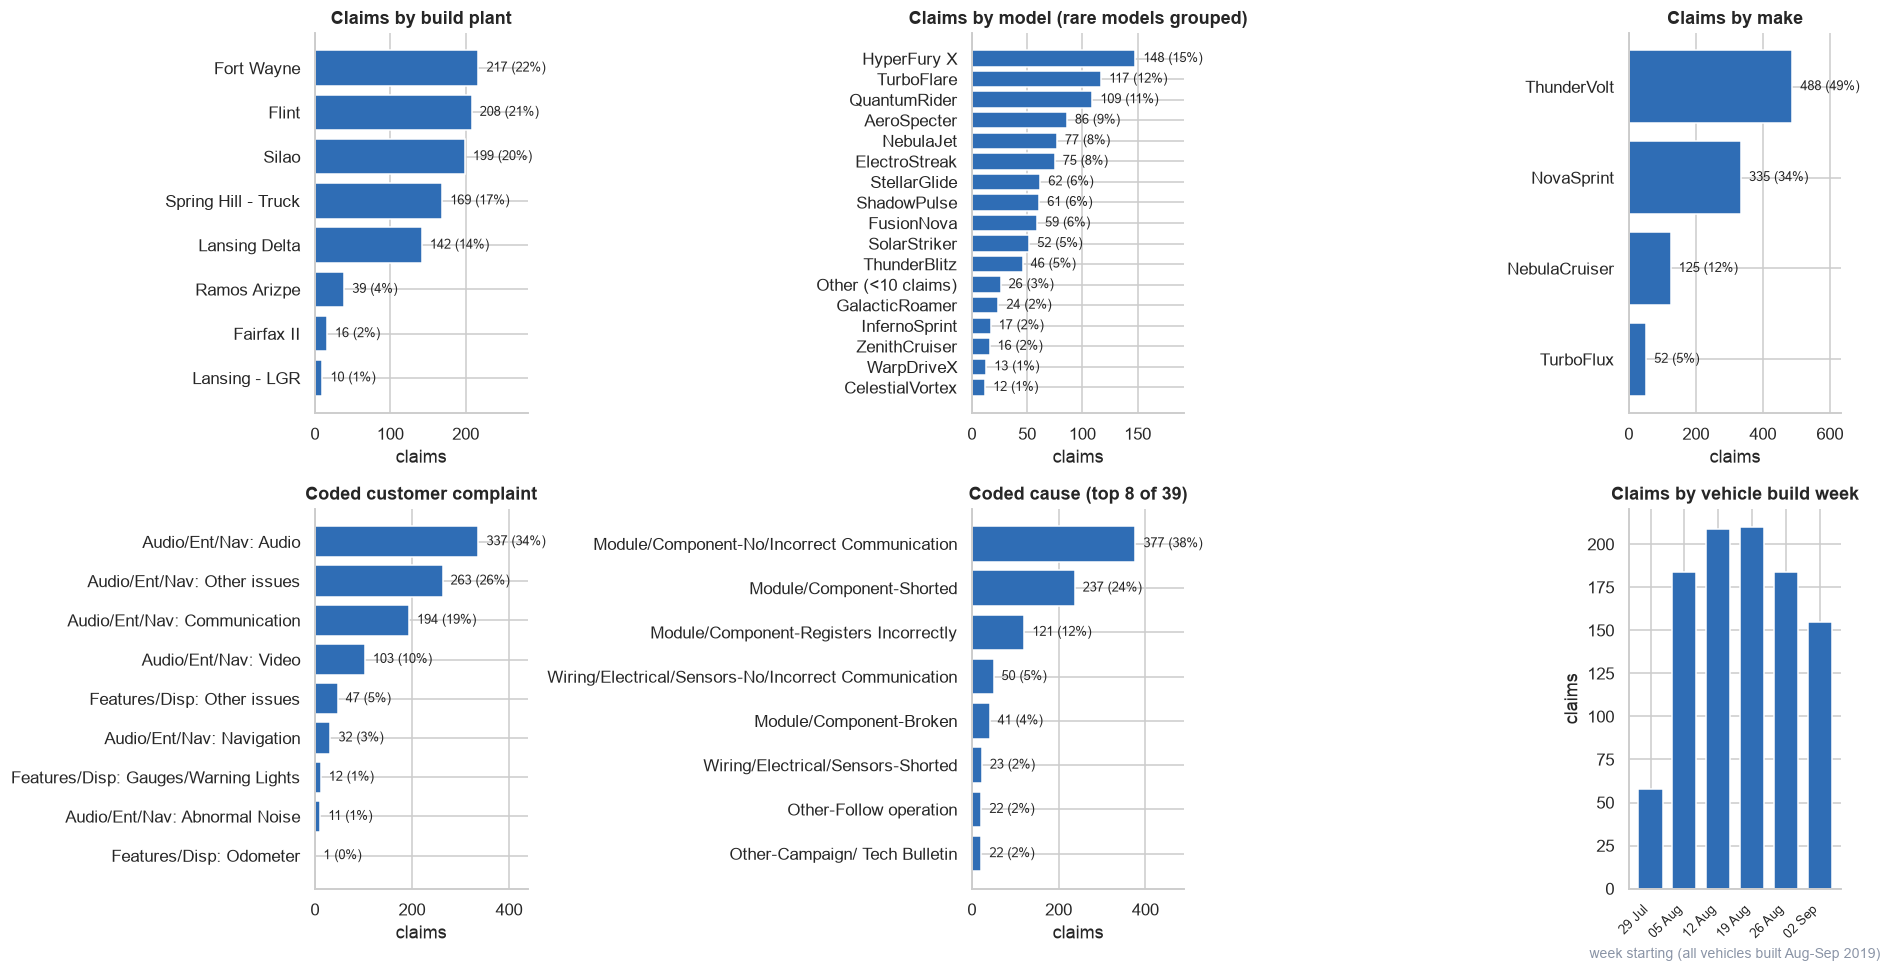

In [11]:
# ---- 3.3 Distribution of the categorical columns -------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
barh_counts(axes[0, 0], df.BUILD_PLANT_DESC, "Claims by build plant")
barh_counts(axes[0, 1], df.model_grp, "Claims by model (rare models grouped)")
barh_counts(axes[0, 2], df.MAKE, "Claims by make")
barh_counts(axes[1, 0], df.complaint_short, "Coded customer complaint")
barh_counts(axes[1, 1], df.CAUSAL_CD_DESC, "Coded cause (top 8 of %d)" % df.CAUSAL_CD_DESC.nunique(), top=8, pct_of=len(df))
ax = axes[1, 2]
bw = df.groupby("build_week").size()
ax.bar(bw.index, bw.values, width=5, color=BLUE)
ax.set_title("Claims by vehicle build week"); ax.set_ylabel("claims")
ax.set_xticks(bw.index); ax.set_xticklabels([d.strftime("%d %b") for d in bw.index], rotation=45, ha="right", fontsize=8.5)
ax.set_xlabel("week starting (all vehicles built Aug-Sep 2019)", fontsize=9, color=GREY)
savefig("fig02_categorical_distributions")

In [12]:
# ---- 3.4 Are the categories associated? (chi-square + Cramer's V on the coded columns) ----------------------------------
def cramers_v(a, b):
    """Association strength between two categorical variables (0 = none, 1 = perfect)."""
    ct = pd.crosstab(a, b)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum()
    v = np.sqrt((chi2 / n) / (min(ct.shape) - 1))
    return chi2, p, dof, v

rows = []
for a, b in [("BUILD_PLANT_DESC", "COMPLAINT_CD_DESC"), ("model_grp", "COMPLAINT_CD_DESC"), ("MAKE", "COMPLAINT_CD_DESC"),
             ("BUILD_PLANT_DESC", "CAUSAL_CD_DESC"), ("COMPLAINT_CD_DESC", "CAUSAL_CD_DESC")]:
    chi2, p, dof, v = cramers_v(df[a], df[b])
    rows.append({"variable A": a, "variable B": b, "chi2": round(chi2, 1), "dof": dof, "p-value": f"{p:.3g}", "Cramer's V": round(v, 3)})
display(pd.DataFrame(rows))
FACTS["association"] = rows
print("Caveat: many cells have expected counts <5 so p-values are approximate; read Cramer's V (effect size) first.")

,variable A,variable B,chi2,dof,p-value,Cramer's V
0,BUILD_PLANT_DESC,COMPLAINT_CD_DESC,50.9,56,0.668,0.085
1,model_grp,COMPLAINT_CD_DESC,167.9,128,0.0103,0.145
2,MAKE,COMPLAINT_CD_DESC,48.1,24,0.00243,0.127
3,BUILD_PLANT_DESC,CAUSAL_CD_DESC,291.8,266,0.133,0.204
4,COMPLAINT_CD_DESC,CAUSAL_CD_DESC,824.4,304,1.32e-49,0.321


Caveat: many cells have expected counts <5 so p-values are approximate; read Cramer's V (effect size) first.


**EDA take-aways (structured columns only)**

* Claims ramp up over the first ~5 months, plateau around 60-70 a month through 2020, then decline during 2021 - the classic shape of one cohort ageing through its warranty period. The median claim arrives roughly **7-8 months** after the vehicle enters service (exact value printed in 3.1).
* Volume is concentrated in a handful of plants (Fort Wayne, Flint, Silao, Spring Hill) and models; without build volumes this *cannot* be read as a plant or model quality ranking.
* **The two coded columns look weak as diagnostic evidence**: the complaint code is dominated by a generic "Audio" / "Other issues" bucket, and the coded *cause* is dominated by "No/Incorrect Communication" and "Shorted". Section 5 tests this against what the technicians actually wrote.

## 4. Text mining - turning free text into structured tags

### 4.1 Which columns are free text?
Rather than assume, test it: a free-text column has **many words per cell** and **almost every value is unique**. Dates, coded categories and the example tag columns fail one or both tests.

In [13]:
rows = []
for c in raw.select_dtypes(include="object").columns:
    s = raw[c].dropna().astype(str)
    rows.append({"column": c, "avg_words": s.str.split().str.len().mean(), "avg_chars": s.str.len().mean(),
                 "unique_ratio": s.nunique() / max(len(s), 1), "non_null": len(s)})
ft = pd.DataFrame(rows).set_index("column").sort_values("avg_words", ascending=False)
# free text = long cells AND (nearly) every value distinct AND populated for most rows
ft["is_free_text"] = (ft.avg_words >= 8) & (ft.unique_ratio > 0.85) & (ft.non_null > 0.9 * len(raw))
display(ft.round(2))
FREE_TEXT = ft.index[ft.is_free_text].tolist()
print("Free-text columns identified:", FREE_TEXT)

,avg_words,avg_chars,unique_ratio,non_null,is_free_text
column,,,,,
CORRECTION_VERBATIM,28.62,179.76,0.95,1000,True
CAUSAL_VERBATIM,22.35,140.24,0.94,999,True
CUSTOMER_VERBATIM,17.34,100.42,0.99,1000,True
COMPLAINT_CD_DESC,3.33,41.95,0.01,1000,False
Failure Condition,3.20,32.60,1.00,5,False
Trigger,2.80,28.40,0.40,5,False
Additional Context,2.80,23.40,0.40,5,False
Failure Component,2.40,22.20,1.00,5,False
BUILD_PLANT_DESC,1.94,10.02,0.01,1000,False


Free-text columns identified: ['CORRECTION_VERBATIM', 'CAUSAL_VERBATIM', 'CUSTOMER_VERBATIM']


Read as one story, the three narratives describe a single warranty event:

* **`CUSTOMER_VERBATIM`** - the *symptom* in the owner's/advisor's words ("radio screen goes blank").
* **`CAUSAL_VERBATIM`** - the technician's *diagnosis* (what was tested and found).
* **`CORRECTION_VERBATIM`** - the *repair* performed.

That mapping mirrors the six example tag columns: `Failure Component` + `Failure Condition` + `Trigger` + `Additional Context` come from the symptom/diagnosis; `Fix Component` + `Fix Condition` come from the repair.

### 4.2 The text is messy - what has to be handled

In [14]:
# Real examples of the noise (first 140 characters). The export removed line-breaks and numbers, so words are glued
# together ("atradiothat"), numbers vanish (leaving double spaces), and some words are split ("RE PLACED", "RAD IO").
demo = raw.loc[[5, 17, 110, 455], ["Event id", "CUSTOMER_VERBATIM", "CORRECTION_VERBATIM"]]
for _, r in demo.iterrows():
    print(r["Event id"], "| CUST:", str(r.CUSTOMER_VERBATIM)[:140].replace("\n", " "))
    print("        | CORR:", str(r.CORRECTION_VERBATIM)[:140].replace("\n", " "))
print()
langs_sample = raw.CUSTOMER_VERBATIM.fillna("")
print("Examples of non-English rows:", [t[:60] for t in langs_sample[langs_sample.str.contains(r"pantalla|[ée]cran|probl[èe]me|appel", case=False)].head(3)])

D-15149 | CUST: CUSTOMER REPORTS SD CARD IS MISSING AT TIME OF DELIVERY - PLEASE ORDER
        | CORR: CHECK FOR SD CARD MISSING FOUND MISSING,INSTALL NEW SD CARD - FOUND 'G ENERAL INACCURACY ERROR  . . . .  RESTART NAV'RETRIED   TIM ES AS PER
D-15334 | CUST: Customer states that the radio screen is freezing at times and goes blank Sometimes you can still hear the volume and other timesit shuts of
        | CORR: Installed new radio but now have no communication with radio.Found terminal tension in radio connector,programmedradio( ) and check operatio
D-14802 | CUST: ADN - COMMUNICATION CSP que il n'est inccapable de faire aucun appel sortant depuis la mise à jour
        | CORR: ce punch etait pour discuter probleme avec client pas aucun code j ai vf mise a jours et il y en a encore une en usb pour radioiot j ai char
D-14516 | CUST: CUSTOMER STATES RADIO WONT WORK. NO ONSTAR, NO SOUND, NO XM, ONLY THE DISPLAY WILL WORK
        | CORR: .REMOVED RADIO TECH   INSTALLED NEW RADIO DID USB 

### 4.3 Approach - why a transparent lexicon + clause pairing (and not just a generic NER model)

| Option | Verdict |
|---|---|
| Off-the-shelf NER | Fails: "radio", "TCICM", "SPS" are not person/organisation/location entities. |
| Fine-tune a model | Not possible: only **5** labelled rows. |
| Zero-shot open-source LLM | Viable, but slow on CPU for 1,000 long narratives, hard to audit, and non-deterministic. Listed under "further improvements". |
| **Domain lexicon + clause-level pairing (used here)** | Fast, fully auditable, deterministic, multilingual by adding cues, and its mistakes are fixable by editing a dictionary. The five provided rows are used for validation. |

Design choices that matter:

1. **Normalise, then repair fragments.** Lower-case, and merge split words (`ra dio` -> `radio`) using a vocabulary of frequent words *learned from the corpus itself*.
2. **Match long keywords as substrings** (no word boundaries) so glued text like `atradiothat` still hits `radio`; use boundaries only for short, risky tokens (`tac`, `bt`, `nav`).
3. **Pair, don't just list.** The example rows store *aligned* lists - `['Audio Unit','Display']` with `['Controls Irresponsive','Black Screen']`. We split text into clauses and attach each symptom to the nearest component(s), with a compatibility matrix so "XM signal lost" can never become a *Black Screen*.
4. **Guard against negation.** "unable to program", "attempted to", "advised to replace", "part ordered" are *not* completed repairs.
5. **Different sources for different tags.** Symptom/trigger/context come from the customer's words (technician prose is full of procedural phrases like "after programming" that would pollute triggers); fix tags come from the correction text.

### 4.4 Step 1 - normalisation and corpus-driven fragment repair

In [15]:
# ---------------------------------------------------------------------------
# 1. Text normalisation
# ---------------------------------------------------------------------------
import re
VOCAB = None   # set via set_vocab(); enables fragment repair inside normalise()

def set_vocab(v):
    global VOCAB
    VOCAB = v

def _base_norm(text):
    """Lower-case, strip digits/odd punctuation, collapse spaces.
    NOTE: the raw export removed line-breaks, so words are often glued together
    ('atradiothat'). Long keywords are therefore matched as substrings (no \\b)."""
    if not isinstance(text, str):
        return ""
    t = text.lower()
    t = re.sub(r"\bc/s\b|\bcs\b|\bcust\b|\bcstmr\b|\bcustomer\b", " customer ", t)
    t = re.sub(r"[_\|]+", " ", t)
    t = re.sub(r"\s+", " ", t)
    return t.strip()


def normalise(text):
    t = _base_norm(text)
    if VOCAB and t:
        t = defragment_tokens(t.split(" "), VOCAB)
    return t


from collections import Counter

def build_vocab(texts, min_count=8):
    """Frequent whole words in the corpus (used to repair 'RAD IO' / 'RE PLACED' style fragmentation)."""
    c = Counter(w for t in texts for w in re.findall(r"[a-z]{2,}", _base_norm(t)))
    return {w for w, n in c.items() if n >= min_count}

def defragment_tokens(toks, vocab):
    """Merge adjacent fragments when their concatenation is a known frequent word and at least one part
    is NOT itself a frequent word  ('ra dio' -> 'radio', 're placed' -> 'replaced', 'c ome' -> 'come')."""
    out, i = [], 0
    while i < len(toks):
        merged = False
        for span in (3, 2):
            if i + span <= len(toks):
                parts = toks[i:i + span]
                joined = "".join(parts)
                if len(joined) >= 4 and joined in vocab and any(p not in vocab for p in parts) and all(len(p) <= 6 for p in parts):
                    out.append(joined); i += span; merged = True; break
        if not merged:
            out.append(toks[i]); i += 1
    return " ".join(out)

### 4.5 Step 2 - the lexicons (English + Spanish + French cues)
Each canonical label maps to a regular expression. The label names deliberately reuse the vocabulary of the five example rows (`Black Screen`, `Controls Irresponsive`, `Inoperative`, `No Sound`, `Internal Fault`, `Malfunction`, `Replaced`, `Programmed`, ...) and extend it ("but not limited to") with entities seen in the data.

In [16]:
# ---------------------------------------------------------------------------
# 2. Lexicons  (canonical label -> regex).  English + Spanish + French cues.
# ---------------------------------------------------------------------------
COMPONENTS = {
    "Radio":              r"radio(?!\s*(?:station|channel))|head ?unit|stereo|infotainment|entertainment (?:system|unit|display)|audio unit|audio system|receiver|\bhmi\b|\bcue\b|mylink|intellilink",
    "Display":            r"display|screen|pantalla|[ée]cran|touch ?screen|monitor",
    "Satellite Radio":    r"\bxm\b|xm ?radio|sirius|satell?ite|sat radio",
    "OnStar/Telematics":  r"onstar|on star|telematics|\btcim\b|\btcicm\b|\btcu\b|\blte\b|\b4g\b",
    "Camera":             r"camera|c[áa]mara|cam[ée]ra|rear ?view|back ?up cam|surround view|video processing",
    "Navigation":         r"navigation|\bnav\b|\bgps\b|navegaci[óo]n|\bmaps?\b",
    "Bluetooth/Phone":    r"blue ?tooth|\bbt\b|hands ?-?free|\bphones?\b|pairing|paired|voice recognition|texting",
    "CarPlay/AndroidAuto":r"carplay|car play|android ?auto|apple",
    "WiFi/Hotspot":       r"wi-?fi|hotspot|hot spot",
    "USB/AUX/SD Port":    r"usb (?:port|recept|hub|cable|connector|jack)|\busb\b|\baux\b|auxiliary|sd card|sd-card",
    "Speaker/Amplifier":  r"speaker|amplifier|\bamp\b|subwoofer|bocina|altavoz|haut-parleur|woofer|tweeter",
    "Antenna/Coax":       r"antenna|antena|coax|aerial",
    "Wiring/Connector":   r"harness|wiring|wire\b|wires\b|connector|\bpins?\b|terminal|fuse|ground(?!ed)|splice|corrosion|chafe",
    "Controls/Buttons":   r"steering wheel (?:control|button|switch)|\bswc\b|knob|button|volume control|controls? (?:do|does|not|are)|touch controls?",
    "Instrument Cluster": r"instrument (?:cluster|panel)|\bipc\b|\bdic\b|\bcluster\b|gauge|speedometer",
    "Head-Up Display":    r"head.?up|\bhud\b",
    "Clock":              r"\bclock\b",
    "Control Module":     r"\bbcm\b|body control|gateway|video processing module|\bmodule\b",
}

CONDITIONS = {
    "Black Screen":        r"blank|black|pantalla (?:se pone )?negra|[ée]cran noir|(?:screen|display)[^.,]{0,15}(?:goes|is|went|turns?|turned|stays?)[^.,]{0,6}(?:out|off|dark|dim)|no display|dark (?:screen|display)|screen (?:off|dark)|goes dark",
    "Inoperative":         r"inop|not working|(?:does ?n[o']?t|won'?t|will not|doesnt|do not|can ?not|cant|not) (?:work|function|operate|turn on|come on|power|respond|start)|dead|no function|quit working|stopped working|out of order|no funciona|ne fonctionne|not operat|failed to|fails to",
    "No Sound":            r"no (?:sound|audio|volume)|without (?:sound|audio)|sin sonido|pas de son|mute|lost audio|audio (?:is )?(?:lost|gone)|no se escucha|can'?t hear",
    "Audio Cutting Out":   r"(?:radio|sound|audio|music)[^.,]{0,20}(?:go(?:es)?|went|will go) (?:out|off)|cuts? (?:in and |and )?out|cut(?:s|ting)? in and out|cutting out|drops?\b|dropping|loses? (?:audio|sound)|audio (?:cuts?|drops?)|cut out",
    "Freezing/Lag":        r"freez|frozen|lock(?:s|ed|ing)? up|hang|hung|slow|lag\b|stuck|unresponsive|not respond",
    "Rebooting/Resetting": r"reboot|restarts?\b|re-?starts? (?:by itself|on its own|itself|randomly)|resets? (?:by itself|on its own|itself|randomly|and|then)|resetting|reseting|(?:shuts?|turns?|powers?|switch(?:es)?) (?:itself |by itself |on its own |randomly )(?:off|down)|(?:shuts?|turns?|powers?) (?:off|down) (?:by itself|on its own|randomly|intermittently|at times)|keeps? (?:shutting|turning|resetting|rebooting|restarting)|turns? off and on|cycling",
    "Controls Irresponsive":r"(?:control|button|knob|touch|steering wheel)s?[^.]{0,40}(?:not|won'?t|doesn'?t|don'?t|no|quit|stopped|unresponsive|do not)[^.]{0,25}(?:work|respond|function|operate|react|do anything)|unresponsive|irresponsive|no response|not respond",
    "Poor Reception/Signal Loss": r"signal|reception|no xm|xm (?:no|not)|searching|acquir|lost (?:xm|sat)|weak|static",
    "Connection Failure":  r"(?:won'?t|will not|not|can'?t|cannot|fails? to|unable to|does ?n[o']?t|keeps? (?:dropping|disconnect)) (?:connect|pair|sync|link|communicat)|disconnect|no comm|lost comm|communication (?:error|loss|fault|issue)|comm(?:s|unication)? (?:error|loss|fault|lost)|no communication",
    "Distorted/Glitching": r"distort|crackl|buzz|noise|glitch|garbl|pop(?:s|ping)?\b|flicker|flash|garbled|scrambl|static|ruido",
    "Incorrect Behaviour": r"wrong|incorrect|by itself|on its own|on their own|randomly|random|changes? (?:station|source|stations)|switch(?:es|ing)? (?:by|on|between|stations)|not (?:the )?correct|does ?n[o']?t (?:display|show) (?:the )?correct|(?:will|would)? ?not (?:hold|keep|save|remember)|asking for|keeps? asking",
    "Stays On/Battery Drain":r"stays? on|remains? on|stay on|won'?t turn off|will not turn off|doesn'?t turn off|drain|draining|parasitic|stays? (?:powered|running)|staying on",
    "Error Message":       r"message|error|prompt|warning|fault displayed|pin code|triangle",
    "Internal Fault":      r"internal (?:fault|failure|short|damage|defect|problem|malfunction)|faulty|defective|failed|failure|bad radio|found (?:the )?radio (?:to be )?bad|radio bad|found bad|inoperative internal",
    "Missing/Not Detected": r"missing|not (?:detect|recogni[sz]|read|found|seen|showing up)|no (?:sd|usb|card|device|phone) (?:card |detected|recogni)|(?:sd card|usb|device) (?:removed|not)",
    "Update Failure":      r"update[d]? (?:fail|error|did ?n[o']?t|not)|failed (?:update|program)|failure to (?:update|program)|says? to update|needs? (?:an )?update|update (?:required|needed|available)|software (?:update )?(?:issue|fail|error)",
    "Malfunction":         r"malfunction|issues?\b|problem|concern|acting up|not (?:right|normal)|erratic|misbehav|abnormal",
}

TRIGGERS = {
    "When Reversing":      r"revers[ae]|reversing|en reversa|marche arri[èe]re|back(?:ing)? up|backing",
    "At Startup":          r"(?:turn(?:ing|ed|s)?|start(?:ing|ed|s)?|crank(?:ing|ed|s)?) (?:the |up the |on the )?(?:car|vehicle|truck|key|ignition|engine)|start ?up|start-up|first start|cold start|upon start|ignition on|key on|remote start|power(?:ing)? up|boot ?up|when (?:starting|started)|every time (?:it|the \w+) (?:is )?start|after start",
    "After Ignition Off":  r"(?:after|when|once)[^.]{0,25}(?:turn(?:ing|ed)?|shut(?:ting)?|switch(?:ing|ed)?)[^.]{0,10}off|vehicle (?:is )?(?:off|shut)|key off|ignition off|exiting|doors? (?:are )?open|retained accessory|\brap\b",
    "During Phone Call":   r"(?:during|while|on|making|receiving|taking|answering) (?:a |the )?(?:phone )?calls?|hands ?-?free call|incoming call|phone call|talking",
    "Using Navigation":    r"(?:using|in|while|when) (?:the )?nav(?:igation|igating)|navigat(?:ing|ion) (?:is |was )?(?:on|active)|route guidance",
    "After Software Update":r"after (?:a |the |an )?(?:software |radio )?(?:update|program|reprogram|flash|repair|replac)|since (?:the )?(?:update|reprogram|repair)|following (?:a |the )?(?:update|repair)|started after",
    "Source/Station Change":r"(?:change|switch|toggl|scroll|chang)\w* (?:the )?(?:station|channel|source|band)|am (?:to|and) fm|fm (?:to|and) am|(?:xm|sirius) (?:to|and) (?:fm|am)",
    "With Trailer Connected":r"trailer",
}

CONTEXT = {
    "While Driving":       r"while driving|when driving|driving (?:down|on)|while (?:in )?motion|on the (?:road|highway)|down the (?:road|highway)|highway|at speed|mientras (?:maneja|conduce)|en marcha|en route|city driving|bumps?|potholes?",
    "Intermittent":        r"intermitt|int\b|at times|sometimes|randomly|comes? and goes?|on and off|from time to time|occasional|periodic|every (?:few|now)|once in a while|off and on|at random|a veces|par moments",
    "Cold/Hot Weather":    r"\bcold|\bfreez(?:ing)? (?:weather|temp)|winter|\bhot\b|\bheat|summer|temperature|warm(?:s)? up|frost",
    "Rain/Moisture":       r"\brain|\bwet\b|moisture|\bwater|humid|car ?wash|puddle|\bsnow",
    "Repeat Visit":        r"(?:happen(?:ed|s|ing)?|occur(?:red|s)?|return(?:ed|s)?|came|comes|is|was|issue|problem|concern|fault|inop|failed) (?:back )?again|again (?:today|this|last)|prior (?:repair|visit|ro)|previous(?:ly)?|last (?:ro|repair|visit|time)|returns?\b|return(?:ed)? for|second time|third time|\d+(?:st|nd|rd|th) time|repeat|already (?:been )?(?:replaced|reprogrammed|updated|repaired)|came back|recurr|reoccur|same (?:problem|issue|concern)|has been (?:in|here)|still (?:has|have|having|doing|occurs|happening)|continues?",
    "Remote Start":        r"remote start",
    "Trailer Connected":   r"trailer",
}

FIX_VERBS = {
    "Replaced":    r"replac|repr?laced|replacd|repalc|replcaed|replaed|install(?:ed|ing)? (?:a |the |new |an )?(?:new |exchange |remanufactured |reman |replacement )|\br ?& ?r\b|\br r\b|\br/r\b|exchange (?:unit|radio)|swap|remplac|re?emplaz|remplaz|cambi(?:o|[óo]|ar)|new (?:radio|unit|module|antenna|camera|display)|installed new|replacement",
    "Programmed":  r"program|programm|re-?flash|flash(?:ed|ing)?\b|re-?program|update[ds]?\b|updating|software (?:install|load|download|update)|usb (?:file|software|transfer|update|programming)|\bsps\b|calibrat|re-?learn|set ?up|configur|re-?configur|file transfer|programar|programm?[ée]",
    "Repaired":    r"repair|fixed|fix\b|rewir|re-?wire|splic|solder|re-?pin|re-?terminat|tighten|secur(?:ed|ing)|clean(?:ed|ing)?\b|re-?seat|reseat|re-?connect|reconnect|re-?route|reroute|adjust|lubric|realign",
    "Reset":       r"(?:perform|did|do|complet|ran|run|attempt)\w* (?:a |an |the )?(?:hard |master |global |system |battery |radio )*reset|hard reset|master reset|global (?:system )?reset|reset (?:the )?(?:radio|module|system|battery|unit)|battery disconnect|disconnect(?:ed|ing)? (?:the )?(?:vehicle )?battery|power cycle|cycle[d]? (?:the )?(?:key|ignition|power)",
    "Tested OK/No Fault": r"no fault|no trouble|could ?n[o']?t duplicate|unable to duplicate|cannot duplicate|can'?t duplicate|not able to duplicate|cnd\b|no problem found|no concern found|unable to verify",
}

FIX_COMPONENTS = {
    "Radio":            COMPONENTS["Radio"],
    "SPS":              r"\bsps\b|service programming|tech ?2|techline connect",
    "USB":              r"usb (?:file|software|transfer|update|programming|drive|flash|stick)|file transfer|via usb|using usb",
    "USB/AUX/SD Port":  r"usb (?:port|recept|hub|cable|connector|jack|module|media)|aux(?:iliary)? (?:jack|port|input|cable)|sd card|sd-card",
    "Display":          COMPONENTS["Display"],
    "Camera":           COMPONENTS["Camera"],
    "Antenna/Coax":     COMPONENTS["Antenna/Coax"],
    "Wiring/Connector": COMPONENTS["Wiring/Connector"],
    "Speaker/Amplifier":COMPONENTS["Speaker/Amplifier"],
    "OnStar/Telematics":COMPONENTS["OnStar/Telematics"],
    "Control Module":   r"\bbcm\b|body control|gateway|video processing module|control module|\bvpm\b|\bmodule\b",
    "Software":         r"software|firmware|\bsw\b|calibration|update",
    "Instrument Cluster": COMPONENTS["Instrument Cluster"],
}

DIAG_RX = re.compile(
    r"(?:internal(?:ly)?|inernal(?:ly)?|intenral(?:ly)?|intrnal(?:ly)?|intenal(?:ly)?|interal(?:ly)?)\s*(?:fault|failure|failing|short(?:ed|ing)?|damage|defect|problem|malfunction|electrical|inop|dead)|(?:short(?:ed)?|failed|failing)\s+(?:out\s+)?(?:internal\w*|inernal\w*)|"
    r"(?:radio|module|unit|display|screen|antenna|camera|receiver)\s+(?:is |was |has |had |found |to be |internally |failed |failing )*(?:bad|faulty|defective|failed|failing|shorted|damaged|dead)|"
    r"(?:found|diagnosed|determined|verified)\s+(?:the )?(?:radio|module|unit|display|receiver)\s*(?:to be\s*)?(?:bad|faulty|failed|defective)|"
    r"faulty (?:radio|module|unit|display|receiver)|defective (?:radio|module|unit|display)|radio failure|failure (?:in|of) (?:the )?(?:radio|unit|module)|shorted out internal|internal(?:l)?y shor",
    re.I)

NEGATORS = r"(?:unable to|not able to|could ?n[o']?t|can ?n[o']?t|did ?n[o']?t|do ?es ?n[o']?t|won'?t|will not|failed to|fail to|no need to|not (?:to )?|never|without|need(?:s|ed)? to|requires?|recommend(?:s|ed)?|advis\w+ (?:to|customer to)|attempt(?:ed|ing)? to|tr(?:y|ied|ying) to|waiting (?:for|on)|order(?:ed)?|pending|if needed|if necessary|may need|might need|would|should)\s*(?:[a-z]+\s+){0,2}$"


def _compile(d):
    return {k: re.compile(v, re.I) for k, v in d.items()}

C_COMP, C_COND, C_TRIG, C_CTX = map(_compile, (COMPONENTS, CONDITIONS, TRIGGERS, CONTEXT))
C_FIXV, C_FIXC = _compile(FIX_VERBS), _compile(FIX_COMPONENTS)
C_NEG = re.compile(NEGATORS, re.I)


def _spans(text, compiled):
    out = []
    for label, rx in compiled.items():
        for m in rx.finditer(text):
            out.append((m.start(), m.end(), label))
    return sorted(out)


def _dedupe(seq):
    seen, out = set(), []
    for s in seq:
        if s not in seen:
            seen.add(s)
            out.append(s)
    return out


def _clauses(text):
    """Split into clause-like chunks so symptoms are paired with the right part."""
    parts = re.split(r"[.;:!?]|\band also\b|\balso\b|\bplus\b|\bbut\b|\bthen\b|,\s|\band\b(?=\s+(?:the|no|not|radio|screen|display|camera))| - ", text)
    return [p.strip() for p in parts if p and len(p.strip()) > 2]


COND_ALLOWED = {
    "Black Screen":        {"Display", "Radio", "Camera", "Navigation", "Instrument Cluster", "Head-Up Display"},
    "No Sound":            {"Radio", "Satellite Radio", "Bluetooth/Phone", "Speaker/Amplifier", "Navigation", "CarPlay/AndroidAuto", "OnStar/Telematics"},
    "Audio Cutting Out":   {"Radio", "Satellite Radio", "Bluetooth/Phone", "Speaker/Amplifier", "CarPlay/AndroidAuto"},
    "Poor Reception/Signal Loss": {"Satellite Radio", "Antenna/Coax", "Radio", "OnStar/Telematics", "Bluetooth/Phone", "WiFi/Hotspot", "Navigation"},
    "Connection Failure":  {"Bluetooth/Phone", "CarPlay/AndroidAuto", "WiFi/Hotspot", "OnStar/Telematics", "USB/AUX/SD Port", "Radio", "Navigation"},
    "Missing/Not Detected":{"USB/AUX/SD Port", "Camera", "Bluetooth/Phone", "Navigation", "CarPlay/AndroidAuto", "Radio"},
    "Controls Irresponsive":{"Controls/Buttons", "Display", "Radio"},
    "Stays On/Battery Drain":{"Radio", "Display", "Camera", "Control Module", "OnStar/Telematics", "Instrument Cluster"},
}

def _compatible(targets, cond):
    """Keep only components that can plausibly show this condition ('XM signal lost' is not a 'Black Screen')."""
    allowed = COND_ALLOWED.get(cond)
    if not allowed:
        return targets
    keep = [t for t in targets if t in allowed]
    return keep or targets[:1]

### 4.6 Step 3 - failure side: component-condition pairs, trigger and context

In [17]:
# ---------------------------------------------------------------------------
# 3. Failure side  (customer + causal text)
# ---------------------------------------------------------------------------
DEFAULT_COMPONENT = "Radio"   # >98% of claims name the radio/head-unit; used when only a symptom is stated

WEAK_CONDITIONS = {"Malfunction", "Error Message", "Incorrect Behaviour"}
# The diagnosis text is full of procedural talk ("history DTCs in the TCICM and amplifier", "tested coax ... not working"), so only
# user-visible symptoms on user-facing parts are borrowed from it.
DIAG_COMPONENTS = {"Radio", "Display", "Camera", "Navigation", "Satellite Radio", "Bluetooth/Phone", "Controls/Buttons"}
DIAG_CONDITIONS = {"Black Screen", "No Sound", "Audio Cutting Out", "Freezing/Lag", "Rebooting/Resetting", "Controls Irresponsive",
                   "Poor Reception/Signal Loss", "Stays On/Battery Drain", "Distorted/Glitching"}


def _pair_clauses(source):
    """Pair components with conditions clause by clause.  Returns (pairs, components_left_without_a_symptom)."""
    pairs, last_comp, pending = [], None, []
    for cl in _clauses(source):
        spans = _spans(cl, C_COMP)
        comps = _dedupe([m[2] for m in spans])
        # 'radio screen' / 'xm radio' / 'radio nav' are ONE compound noun -> keep the specific part only,
        # but 'radio and screen' names two parts -> keep both.
        if "Radio" in comps and len(comps) > 1:
            drop = False
            for a in spans:
                if a[2] != "Radio":
                    continue
                for b in spans:
                    if b[2] == "Radio":
                        continue
                    gap = cl[a[1]:b[0]] if a[1] <= b[0] else cl[b[1]:a[0]]
                    if gap.strip() in ("", "-"):
                        drop = True
            if drop:
                comps = [c for c in comps if c != "Radio"] or comps
        if "Control Module" in comps and len(comps) > 1:
            comps = [c for c in comps if c != "Control Module"]
        conds = _dedupe([m[2] for m in _spans(cl, C_COND)])
        if len(conds) > 1:                     # 'Malfunction' is a weak cue: drop it if anything stronger exists
            conds = [c for c in conds if c != "Malfunction"] or conds
        if conds:
            targets = _dedupe(pending + comps) if pending else comps
            targets = targets or ([last_comp] if last_comp else [DEFAULT_COMPONENT])
            for c in conds:
                for t in _compatible(targets, c):
                    pairs.append((t, c))
            pending = []
        elif comps:
            pending = comps                    # e.g. 'radio and screen is inop' -> radio waits for the next clause
        if comps:
            last_comp = comps[-1]
    return pairs, pending


def extract_failure(customer, causal, correction=""):
    """Aligned (component, condition) pairs: the customer's symptom + the verified symptom at the start of the diagnosis
    + any explicit technician diagnosis ('radio internal fault')."""
    pairs, pending = _pair_clauses(normalise(customer))
    diag_pairs, diag_pending = _pair_clauses(normalise(causal)[:250])    # opening of the diagnosis re-states the verified symptom
    if pairs:
        pairs += [p for p in diag_pairs if p[0] in DIAG_COMPONENTS and p[1] in DIAG_CONDITIONS and p not in pairs]
    elif diag_pairs:
        pairs = diag_pairs
    else:
        pairs = [(c, "Malfunction") for c in (pending or diag_pending)[:2]]      # component named, symptom unstated
    # explicit technician diagnosis ('radio internal fault', 'found radio faulty') -> Internal Fault on the named part
    diag_text = normalise(causal) + " . " + normalise(correction)
    for m in DIAG_RX.finditer(diag_text):
        win = diag_text[max(0, m.start() - 40): m.end() + 40]
        named = [c for c in _dedupe([x[2] for x in _spans(win, C_COMP)]) if c in ("Display", "Camera", "Antenna/Coax", "OnStar/Telematics", "Speaker/Amplifier", "Instrument Cluster")]
        named = named or ["Radio"]
        pairs.append((named[0], "Internal Fault"))
        break
    return _dedupe(pairs)


def extract_trigger_context(customer, causal):
    # Technician prose is full of diagnostic steps ('after programming', 'on a call'), so only the
    # customer's own words plus the first sentence(s) of the diagnosis are used for trigger/context.
    text = normalise(customer) + " . " + normalise(causal)[:250]
    trig = _dedupe([m[2] for m in _spans(text, C_TRIG)])
    ctx = _dedupe([m[2] for m in _spans(text, C_CTX)])
    # 'back up camera' is a component name, not a reversing trigger
    if "When Reversing" in trig and not re.search(r"revers[ae]|reversing|en reversa|marche arri[èe]re|in reverse|into reverse", text):
        trig.remove("When Reversing")
    return trig, ctx

### 4.7 Step 4 - repair side: fix component-condition pairs
A repair verb is paired with the nearest component after it ("replaced **radio**") - programming verbs prefer the *tool* named (`SPS`, `USB file transfer`), matching the examples.

In [18]:
# ---------------------------------------------------------------------------
# 4. Fix side (correction text, falling back to causal text)
# ---------------------------------------------------------------------------
ALLOWED_FIX = {
    "Replaced":   {"Radio", "Display", "Camera", "Antenna/Coax", "Wiring/Connector", "Speaker/Amplifier", "USB/AUX/SD Port", "Control Module", "OnStar/Telematics", "Instrument Cluster"},
    "Programmed": {"Radio", "Display", "Camera", "Control Module", "OnStar/Telematics", "Instrument Cluster", "Software"},
    "Repaired":   {"Radio", "Antenna/Coax", "Wiring/Connector", "USB/AUX/SD Port", "Camera", "Speaker/Amplifier", "Display"},
    "Reset":      {"Radio", "Control Module", "Display", "OnStar/Telematics"},
}


def extract_fix(correction, causal, customer=""):
    pairs = []
    for source in (normalise(correction), normalise(causal)):
        verbs = []
        for label, rx in C_FIXV.items():
            for m in rx.finditer(source):
                if label != "Tested OK/No Fault":
                    prefix = source[max(0, m.start() - 45):m.start()]
                    if C_NEG.search(prefix):
                        continue   # 'unable to program', 'ordered', 'attempted to', 'needs to be replaced' ...
                verbs.append((m.start(), m.end(), label))
        verbs.sort()
        comps = []
        for label, rx in C_FIXC.items():
            for m in rx.finditer(source):
                comps.append((m.start(), m.end(), label))
        comps.sort()
        for vs, ve, vlabel in verbs:
            if vlabel == "Tested OK/No Fault":
                pairs.append(("N/A", vlabel))
                continue
            # nearest component within a window after the verb, else just before it
            after = [c for c in comps if 0 <= c[0] - ve <= 45]
            before = [c for c in comps if 0 <= vs - c[1] <= 25]
            chosen = None
            allowed = ALLOWED_FIX[vlabel]
            after = [c for c in after if c[2] in allowed or c[2] in ("SPS", "USB")]
            before = [c for c in before if c[2] in allowed or c[2] in ("SPS", "USB")]
            if vlabel == "Programmed":
                tool = [c for c in after + before if c[2] in ("SPS", "USB")]
                tool = tool or [c for c in comps if c[2] in ("SPS", "USB") and abs(c[0] - vs) <= 60]
                if tool:
                    chosen = tool[0][2]
            if not chosen:
                cand = [c for c in after if c[2] not in ("SPS", "USB")] or [c for c in before if c[2] not in ("SPS", "USB")]
                if cand:
                    chosen = cand[0][2]
            if not chosen and vlabel in ("Replaced", "Programmed") and (
                    any(c[2] == "Radio" for c in comps)
                    or re.search(r"radio|head ?unit|stereo|infotainment", normalise(causal) + " " + normalise(customer))):
                chosen = "Radio"
            if chosen:
                pairs.append((chosen, vlabel))
        if pairs:
            break
    # tidy: 'Software' only makes sense with Programmed
    pairs = [(c, v) for (c, v) in pairs if not (c == "Software" and v != "Programmed")]
    if any(c != "Software" for c, v in pairs):
        pairs = [(c, v) for (c, v) in pairs if c != "Software"]
    return _dedupe(pairs)

### 4.8 Step 5 - extra entity flags beyond the schema
Binary flags that stakeholders can filter on: escalation to technical assistance, DTCs mentioned, bulletin cited, software attempted, internal failure found, communication fault, electrical evidence, etc.

In [19]:
# ---------------------------------------------------------------------------
# 5. Extra (non-schema) entity flags
# ---------------------------------------------------------------------------
FLAGS = {
    "flag_tac_escalation":  r"\btac\b|techline|tech line|technical assistance|field engineer|engineering (?:response|advised|support)|case (?:#|number|no)|called gm|contact(?:ed)? (?:gm|tac)|hotline",
    "flag_dtc_mentioned":   r"\bdtcs?\b|diagnostic trouble|trouble codes?|\bcodes?\b|\bu0\d|\bb\d{4}|history (?:dtc|code)",
    "flag_bulletin_cited":  r"bulletin|\btsb\b|campaign|\bpit\d|\bsi\b|service information|\bpi\d{3}|tech tip|recall",
    "flag_software_attempt":r"program|re-?flash|update|software|\bsps\b|usb (?:file|software|transfer)|file transfer|calibrat|firmware",
    "flag_no_fault_found":  r"no fault|no trouble|could ?n[o']?t duplicate|unable to duplicate|cannot duplicate|can'?t duplicate|not able to duplicate|\bcnd\b|no problem found|unable to verify|could not verify|not duplicated|concern not (?:present|duplicated)",
    "flag_no_dtc_found":    r"no (?:dtcs?|codes?|trouble codes?)(?: (?:were |was )?(?:found|present|stored|set))?|no (?:current|history) (?:dtcs?|codes?)|(?:dtcs?|codes?) (?:found|present|stored): ?none|found none|none found|nocodes|nodtc",
    "flag_parts_wait":      r"order(?:ed|ing)? (?:a |the )?(?:new |part|radio)|part(?:s)? (?:arrived|came in|on order|back ?order|delay)|waiting (?:for|on) part|back ?order|no parts|parts? in\b|radio came in",
    "flag_loaner_or_rental":r"\bloan(?:er)?\b|rental|\bctp\b|shuttle|courtesy",
    "flag_comm_fault":      r"lost comm|no comm|communication (?:error|loss|fault|issue|problem)|ethernet|data (?:bus|link|circuit|line)|serial data|network|\bcan\b bus|u0\d{3}|lost communication|bus (?:error|off)|gateway",
    "flag_power_electrical":r"\bpower\b|voltage|\bground\b|short(?:ed)? to|open circuit|high resistance|resistance|fuse|battery|harness|wiring|connector|corros|chafe|damaged wire|continuity|ohm",
    "flag_software_fix_failed": r"(?:reprogram\w*|updat\w*|program\w*|flash\w*|software)[^.]{0,70}(?:still (?:not|inop|present|persist|occur|happen|has|have|doing|fail)|no change|persist|did ?n[o']?t (?:fix|resolve|correct|help|work)|not (?:fix|resolve|correct|help)|unsuccessful|concern (?:still|remain)|issue (?:still|remain))",
    "flag_internal_failure": DIAG_RX.pattern + r"|found (?:the )?radio (?:to be )?(?:bad|faulty|defective|at fault)|radio (?:is |was |to be )?at fault|radio (?:has |had )?(?:failed|failure)|failing internally|radio internally|internally (?:inop|failed|failing)|bad radio|radio is bad",
}
C_FLAGS = _compile(FLAGS)


def extract_flags(customer, causal, correction):
    text = " . ".join(normalise(x) for x in (customer, causal, correction))
    return {k: bool(rx.search(text)) for k, rx in C_FLAGS.items()}


ES_MARKERS = r"\b(?:pantalla|funciona|enciende|estereo|est[ée]reo|navegador|ubicaci[óo]n|correctamente|bocinas?|sonido|cliente|falla|veh[ií]culo|reversa|diagn[óo]stico|mensaje|se pone|negra|apagado|despu[ée]s|inspecci[óo]n|realizar|siguiente|componente|reemplace|reemplaz\w*|el cual|nos dice)\b"
FR_MARKERS = r"[éèêàç]|\b(?:fonctionn?e|fonction|joue|appel|probl[èe]me|avec|pour|dans|pas|plus|client|[ée]cran|v[ée]rifi\w*|remplac[ée]\w*|mise [àa] jour|il y a|ce punch|n'est|j ai|probleme|que il)\b"
EN_MARKERS = r"\b(?:the|and|was|found|checked|replaced|with|for|that|customer|states|screen|is|to|of|radio|not|no)\b"


def detect_language(text):
    """Marker-count language guess (English / Spanish / French) - enough to hold the ~2% non-English rows out of English-only modelling."""
    t = normalise(text)
    es, fr, en = (len(re.findall(p, t)) for p in (ES_MARKERS, FR_MARKERS, EN_MARKERS))
    if es >= 2 and es * 1.5 >= en:
        return "Spanish"
    if fr >= 2 and fr * 1.5 >= en and not re.search(r"\b(?:the|and|was)\b", t):
        return "French"
    return "English"

### 4.9 Step 6 - issue-type classification (section 5 explains the logic)

In [20]:
# ---------------------------------------------------------------------------
# 6. Issue-type classification (built from the mined entities + technician evidence)
# ---------------------------------------------------------------------------
ELEC_RX = re.compile(
    r"(?:found|discover\w*|noted|identified|located|determined|had|showed|measured)[^.]{0,45}(?<!no )(?<!not )(?:open|short(?:ed)? to|corrod\w*|chaf\w*|damag\w*|broken|bent|spread|loose|pushed out|backed out|fray\w*|melt\w*|high resistance|pinched)[^.]{0,35}(?:wire|wiring|harness|connector|pin|terminal|circuit|cable|ground|coax|lvds)"
    r"|(?:repair|re-?pin|re-?terminat|splic|solder|re-?route)\w*[^.]{0,25}(?:wire|wiring|harness|connector|pin|terminal|ground|coax|lvds|cable)"
    r"|(?<!no )(?<!not )corrosion|chafed|rodent|water intrusion|(?:battery|parasitic) (?:draw|drain)|parasitic|(?:blown|bad) fuse|fuse (?:was )?blown|poor (?:ground|connection|contact)|dielectric grease", re.I)
COMM_RX = re.compile(
    r"(?:lost|no|loss of|loses|lose|intermittent|poor|invalid|missing|fail\w* to establish)\s*(?:serial data |data |ethernet |network |bus )?comm(?:unication)?s?\b"
    r"|u0\d{3}|(?:radio|module|unit)\s+(?:is |was )?(?:not|n't|no longer)\s+(?:communicat|respond|seen|visible)"
    r"|communication (?:error|loss|fault|issue|problem|failure)|ethernet (?:bus|link|network|error|fault)|data (?:bus|link) (?:error|fault)|not (?:on|seen on|visible on) (?:the )?(?:bus|network)|can'?t communicate|lost comm|no comm", re.I)
SW_RX = re.compile(
    r"software (?:issue|fault|fail\w*|problem|corrupt\w*|glitch|bug|error|concern)|faulty software|corrupt\w*|failed (?:update|program\w*|software)|update(?:d)? (?:fail\w*|error)|incorrect (?:software|calibration|version)|outdated|old software"
    r"|(?:bulletin|tsb|campaign|pit\d*)[^.]{0,60}(?:software|update|program)|(?:software|update|program\w*)[^.]{0,40}(?:bulletin|tsb|campaign)|software update (?:available|released|fixed|corrected|resolved)|update[d]? (?:radio )?software (?:available|fix)"
    r"|(?:reprogram\w*|program\w*|flash\w*|updat\w*)[^.]{0,30}(?:corrected|resolved|fixed|cured|repaired|concern (?:gone|resolved))", re.I)

HARDWARE_NON_RADIO = {"Camera", "Antenna/Coax", "USB/AUX/SD Port", "Speaker/Amplifier", "Display", "OnStar/Telematics", "Control Module", "Instrument Cluster"}
WIRING = {"Wiring/Connector"}

ISSUE_CATEGORIES = [
    "Radio Hardware Failure",
    "Communication / Network Fault",
    "Software / Programming Issue",
    "Electrical / Wiring / Power Fault",
    "Peripheral / Accessory Failure",
    "No Fault Found / Not Duplicated",
    "Radio Replaced - Cause Not Documented",
    "Other / Unclassified",
]


def classify_issue(fix_pairs, causal, correction, flags):
    """Return (primary_category, evidence_list). Evidence rules are ordered from most to least specific cause."""
    text = normalise(causal) + " . " + normalise(correction)
    fixes = set(fix_pairs)
    radio_replaced = ("Radio", "Replaced") in fixes
    programmed = any(v == "Programmed" for _, v in fixes)
    nff = flags["flag_no_fault_found"]
    ev = []
    elec, comm, sw = bool(ELEC_RX.search(text)), bool(COMM_RX.search(text)), bool(SW_RX.search(text))
    internal = flags["flag_internal_failure"]
    peripheral_fix = any(c in HARDWARE_NON_RADIO and v in ("Replaced", "Repaired") for c, v in fixes)
    wiring_fix = any(c in WIRING and v in ("Replaced", "Repaired") for c, v in fixes)
    if elec or wiring_fix: ev.append("electrical")
    if internal: ev.append("internal_failure")
    if comm: ev.append("communication")
    if sw: ev.append("software")
    if peripheral_fix: ev.append("peripheral_fix")
    if nff: ev.append("no_fault_found")

    if radio_replaced:
        if wiring_fix or (elec and not internal): cat = "Electrical / Wiring / Power Fault"
        elif internal: cat = "Radio Hardware Failure"
        elif comm: cat = "Communication / Network Fault"
        elif sw: cat = "Software / Programming Issue"
        else: cat = "Radio Replaced - Cause Not Documented"
    else:
        if wiring_fix or elec: cat = "Electrical / Wiring / Power Fault"
        elif peripheral_fix: cat = "Peripheral / Accessory Failure"
        elif programmed or sw: cat = "Software / Programming Issue"
        elif nff: cat = "No Fault Found / Not Duplicated"
        elif internal: cat = "Radio Hardware Failure"
        elif comm: cat = "Communication / Network Fault"
        else: cat = "Other / Unclassified"
    return cat, ev


AFFECTED_FUNCTION_ORDER = [
    ("Camera / Video",         {"Camera"}),
    ("Navigation",             {"Navigation"}),
    ("OnStar / Telematics",    {"OnStar/Telematics"}),
    ("Phone / Connectivity",   {"Bluetooth/Phone", "CarPlay/AndroidAuto", "WiFi/Hotspot"}),
    ("Satellite Radio / Reception", {"Satellite Radio", "Antenna/Coax"}),
    ("Controls / HMI Input",   {"Controls/Buttons"}),
    ("Display / Screen",       {"Display", "Instrument Cluster", "Head-Up Display"}),
    ("Audio / Sound",          {"Speaker/Amplifier"}),
    ("Radio (General)",        {"Radio"}),
]

def affected_function(fail_pairs):
    comps = {c for c, _ in fail_pairs}
    conds = {v for _, v in fail_pairs}
    for name, members in AFFECTED_FUNCTION_ORDER:
        if comps & members:
            return name
    if "No Sound" in conds or "Audio Cutting Out" in conds or "Distorted/Glitching" in conds:
        return "Audio / Sound"
    return "Radio (General)" if comps else "Unspecified"

### 4.10 Apply the extractor to all 1,000 claims

In [21]:
# Keep the 5 provided example rows aside - they are the validation set, not training data
GOLD_COLS = ["Trigger", "Failure Component", "Failure Condition", "Additional Context", "Fix Component", "Fix Condition"]
gold = raw.loc[raw["Failure Component"].notna(), ["Event id"] + GOLD_COLS].copy()
for c in GOLD_COLS:
    gold[c] = gold[c].map(ast.literal_eval)          # stored as strings like "['Radio', 'Display']"

# Learn the fragment-repair vocabulary from the corpus, then switch it on for every normalise() call
set_vocab(build_vocab(pd.concat([df[c] for c in TEXT_COLS]).dropna(), min_count=8))
print("Fragment-repair vocabulary:", len(VOCAB), "frequent words")

def mine_row(r):
    """All text-mining outputs for one claim."""
    cust, caus, corr = ("" if r.customer_placeholder else r.CUSTOMER_VERBATIM), r.CAUSAL_VERBATIM, r.CORRECTION_VERBATIM
    fail = extract_failure(cust, caus, corr)
    trig, ctx = extract_trigger_context(cust, caus)
    fix = extract_fix(corr, caus, cust)
    flags = extract_flags(cust, caus, corr)
    issue, evidence = classify_issue(fix, caus, corr, flags)
    return {"fail_pairs": fail, "trig": trig, "ctx": ctx, "fix_pairs": fix, "issue": issue, "evidence": evidence,
            "function": affected_function(fail), "language": detect_language(" ".join(str(x) for x in (cust, caus, corr))), **flags}

M = pd.DataFrame([mine_row(r) for r in df.itertuples()], index=df.index)

# Present the tags in the same list-of-strings format as the five examples (aligned component/condition lists)
def as_lists(pairs, default):
    comps = [c for c, _ in pairs] or [default]
    conds = [v for _, v in pairs] or [default]
    return str(comps), str(conds)

df["Failure Component"], df["Failure Condition"] = zip(*[as_lists(p, "Unspecified") for p in M.fail_pairs])
df["Fix Component"], df["Fix Condition"] = zip(*[as_lists(p, "Unspecified") for p in M.fix_pairs])
df["Trigger"] = [str(t or ["No Additional Functionality"]) for t in M.trig]       # defaults copied from the example rows
df["Additional Context"] = [str(c or ["No Additional Context"]) for c in M.ctx]
df["Failure Pairs"] = [" | ".join(f"{c}: {v}" for c, v in p) for p in M.fail_pairs]
df["Fix Pairs"] = [" | ".join(f"{c}: {v}" for c, v in p) for p in M.fix_pairs]
df["Issue Category"] = M.issue
df["Issue Evidence"] = [", ".join(e) for e in M.evidence]
df["Affected Function"] = M.function
df["Language"] = M.language
flag_cols = [c for c in M.columns if c.startswith("flag_")]
for c in flag_cols:
    df[c] = M[c]
df["has_provided_example"] = df["Event id"].isin(gold["Event id"])

cov = {"Failure component/condition pairs": (M.fail_pairs.str.len() > 0).mean(), "Trigger (explicit)": (M.trig.str.len() > 0).mean(),
       "Additional context (explicit)": (M.ctx.str.len() > 0).mean(), "Fix component/condition pairs": (M.fix_pairs.str.len() > 0).mean()}
display(pd.Series(cov, name="rows with at least one tag").map("{:.1%}".format).to_frame())
FACTS["coverage"] = {k: float(v) for k, v in cov.items()}
print("Languages detected:", M.language.value_counts().to_dict())
FACTS["languages"] = M.language.value_counts().to_dict()
log("Non-English narratives (Spanish / French)", "free text", int((M.language != "English").sum()),
    "Kept; Spanish/French cues are included in the lexicons (e.g. 'pantalla negra', 'ecran noir')")
df[["Event id", "CUSTOMER_VERBATIM", "Failure Component", "Failure Condition", "Trigger", "Additional Context", "Fix Component", "Fix Condition"]].head(6)

Fragment-repair vocabulary: 812 frequent words


,rows with at least one tag
Failure component/condition pairs,99.6%
Trigger (explicit),22.1%
Additional context (explicit),34.8%
Fix component/condition pairs,97.9%


Languages detected: {'English': 983, 'French': 13, 'Spanish': 4}


,Event id,CUSTOMER_VERBATIM,Failure Component,Failure Condition,Trigger,Additional Context,Fix Component,Fix Condition
0,D-14801,Customer reports that radio and screen is intermittantly inop Inspect and advise,"['Radio', 'Display']","['Inoperative', 'Inoperative']",['No Additional Functionality'],['Intermittent'],"['SPS', 'USB', 'Radio']","['Programmed', 'Programmed', 'Replaced']"
1,D-14869,RADIO IS INOPERABLE CHECK AND ADVISE,"['Radio', 'Display', 'Display']","['Inoperative', 'Black Screen', 'No Sound']",['No Additional Functionality'],['No Additional Context'],"['Radio', 'Radio']","['Replaced', 'Programmed']"
2,D-14555,CUSTOMER STATES RADIO SCREEN AND ONSTAR KEEPS ATTEMPTING TO CONNECT TO WIFI NETWORK WI...,"['Display', 'OnStar/Telematics', 'WiFi/Hotspot', 'Radio']","['Error Message', 'Error Message', 'Error Message', 'Internal Fault']",['No Additional Functionality'],['No Additional Context'],"['Radio', 'OnStar/Telematics', 'Radio']","['Programmed', 'Replaced', 'Replaced']"
3,D-14704,PANTALLA SE PONE NEGRA,['Display'],['Black Screen'],['When Reversing'],['No Additional Context'],['Radio'],['Replaced']
4,D-15142,CUSTOMER STATES A MESSAGE OF LOST SATELITE SIGNAL TRYING TO RECONNECT CHECK AND ADVISE,"['Satellite Radio', 'Satellite Radio']","['Error Message', 'Poor Reception/Signal Loss']",['No Additional Functionality'],['No Additional Context'],"['USB', 'Radio', 'Radio']","['Programmed', 'Programmed', 'Replaced']"
5,D-15149,CUSTOMER REPORTS SD CARD IS MISSING AT TIME OF DELIVERY - PLEASE ORDER,['USB/AUX/SD Port'],['Missing/Not Detected'],['No Additional Functionality'],['No Additional Context'],"['USB/AUX/SD Port', 'Radio', 'USB']","['Replaced', 'Replaced', 'Programmed']"


> **Coverage vs. precision.** `Trigger` and `Additional Context` are *legitimately* sparse: most customers simply state a symptom. Rows with no explicit trigger/context receive the same default labels used in the example rows (`No Additional Functionality`, `No Additional Context`) rather than a guess.

### 4.11 Validation

Only five rows are labelled, so any score on them is **anecdotal** - it checks the extractor's behaviour but cannot certify accuracy. Three complementary checks are used:

1. **Against the five provided examples** (label-level precision/recall, with documented synonym handling).
2. **Against an independent structured field** - the coded `COMPLAINT_CD_DESC` (e.g. complaint = *Navigation* should usually yield a `Navigation` component tag).
3. **Human spot-check** of random rows (table below) - the check that matters most; reviewers should read it.

In [22]:
# ---- 4.11a Validation against the 5 provided examples -------------------------------------------------------------
# Synonyms: the examples use 'Audio Unit' / 'Radio Module' / 'OnStar'; this extractor uses one canonical label each.
SYN = {"Audio Unit": "Radio", "Radio Module": "Radio", "OnStar": "OnStar/Telematics"}
# Hierarchy: 'Satellite Radio' is a child of 'Radio' (the examples tag satellite-radio concerns as 'Radio')
PARENT = {"Satellite Radio": "Radio", "Antenna/Coax": "Antenna/Coax"}

def label_match(g, m):
    g = SYN.get(g, g)
    return g == m or PARENT.get(m) == g

def prf(gold_sets, mine_sets):
    tp_r = sum(sum(any(label_match(g, m) for m in ms) for g in set(gs)) for gs, ms in zip(gold_sets, mine_sets))
    n_g = sum(len(set(gs)) for gs in gold_sets)
    tp_p = sum(sum(any(label_match(g, m) for g in gs) for m in set(ms)) for gs, ms in zip(gold_sets, mine_sets))
    n_m = sum(len(set(ms)) for ms in mine_sets)
    r, p = tp_r / max(n_g, 1), tp_p / max(n_m, 1)
    return p, r, (2 * p * r / (p + r) if p + r else 0)

mine = M.loc[df.has_provided_example.values]
mine_ids = df.loc[df.has_provided_example, "Event id"].values
gold = gold.set_index("Event id").loc[mine_ids]
cols = {
    "Failure Component": [list(dict.fromkeys(c for c, _ in p)) for p in mine.fail_pairs],
    "Failure Condition": [list(dict.fromkeys(v for _, v in p)) for p in mine.fail_pairs],
    "Trigger": [t or ["No Additional Functionality"] for t in mine.trig],
    "Additional Context": [c or ["No Additional Context"] for c in mine.ctx],
    "Fix Component": [list(dict.fromkeys(c for c, _ in p)) for p in mine.fix_pairs],
    "Fix Condition": [list(dict.fromkeys(v for _, v in p)) for p in mine.fix_pairs],
}
val_scores = pd.DataFrame({k: prf(list(gold[k]), v) for k, v in cols.items()}, index=["precision", "recall", "F1"]).T
display(val_scores.round(2))
FACTS["validation"] = val_scores.round(3).to_dict("index")
print("n = 5 rows -> indicative only.  Where it differs:")
for k in GOLD_COLS:
    for eid, g, m in zip(mine_ids, gold[k], cols[k]):
        if not all(any(label_match(x, y) for y in m) for x in g):
            print(f"  {eid} {k:18s} provided={g}  extracted={m}")

,precision,recall,F1
Failure Component,0.90,1.00,0.95
Failure Condition,0.56,0.56,0.56
Trigger,1.00,1.00,1.00
Additional Context,0.60,0.60,0.60
Fix Component,0.67,0.75,0.71
Fix Condition,0.78,0.88,0.82


n = 5 rows -> indicative only.  Where it differs:
  D-14801 Failure Condition  provided=['Controls Irresponsive', 'Black Screen']  extracted=['Inoperative']
  D-14555 Failure Condition  provided=['Inoperative', 'Inoperative', 'Internal Fault']  extracted=['Error Message', 'Internal Fault']
  D-15142 Failure Condition  provided=['Malfunction']  extracted=['Error Message', 'Poor Reception/Signal Loss']
  D-14801 Additional Context provided=['No Additional Context']  extracted=['Intermittent']
  D-14704 Additional Context provided=['While Driving']  extracted=['No Additional Context']
  D-14869 Fix Component      provided=['Radio', 'USB']  extracted=['Radio']
  D-14704 Fix Component      provided=['Radio', 'USB']  extracted=['Radio']
  D-14704 Fix Condition      provided=['Replaced', 'Programmed']  extracted=['Replaced']


In [23]:
# ---- 4.11b Agreement with an independent structured field (the coded complaint) -----------------------------------
# Where the coded complaint has a SPECIFIC meaning (Navigation, Video), a sensible extractor should usually tag a matching component.
EXPECT = {
    "Audio/Entertainment/Navigation - Navigation": ({"Navigation"}, "a Navigation component"),
    "Audio/Entertainment/Navigation - Video": ({"Display", "Camera", "Head-Up Display"}, "a Display/Camera component"),
}
rows = []
for code, (members, what) in EXPECT.items():
    idx = df.index[df.COMPLAINT_CD_DESC == code]
    ok = np.mean([bool({c for c, _ in M.fail_pairs[i]} & members) for i in idx])
    rows.append({"coded complaint": code.split(" - ")[1], "claims": len(idx), "extractor found": what, "agreement": f"{ok:.0%}"})
display(pd.DataFrame(rows))
FACTS["complaint_agreement"] = rows

# 'Communication', 'Audio' and 'Other issues' are broad buckets, so there is no fixed expectation to test.  Instead, look at what
# customers in each coded complaint actually describe - this shows how much the code tells you about the real symptom.
fn_by_code = pd.crosstab(df.complaint_short, df["Affected Function"] if "Affected Function" in df else M.function, normalize="index")
display((fn_by_code * 100).round(0).astype(int).astype(str).add("%"))

,coded complaint,claims,extractor found,agreement
0,Navigation,32,a Navigation component,56%
1,Video,103,a Display/Camera component,81%


Affected Function,Audio / Sound,Camera / Video,Controls / HMI Input,Display / Screen,Navigation,OnStar / Telematics,Phone / Connectivity,Radio (General),Satellite Radio / Reception,Unspecified
complaint_short,,,,,,,,,,
Audio/Ent/Nav: Abnormal Noise,0%,9%,9%,27%,0%,0%,27%,18%,9%,0%
Audio/Ent/Nav: Audio,1%,7%,2%,26%,2%,2%,6%,41%,13%,0%
Audio/Ent/Nav: Communication,0%,7%,2%,27%,5%,5%,15%,26%,13%,1%
Audio/Ent/Nav: Navigation,0%,3%,0%,3%,56%,0%,3%,28%,6%,0%
Audio/Ent/Nav: Other issues,1%,11%,1%,27%,2%,2%,6%,39%,11%,1%
Audio/Ent/Nav: Video,0%,25%,3%,49%,3%,1%,0%,16%,4%,0%
Features/Disp: Gauges/Warning Lights,0%,17%,8%,17%,0%,0%,8%,42%,8%,0%
Features/Disp: Odometer,0%,0%,0%,0%,100%,0%,0%,0%,0%,0%
Features/Disp: Other issues,0%,32%,0%,19%,6%,4%,6%,28%,4%,0%


In [24]:
# ---- 4.11c Human spot-check sample: read these and judge for yourself --------------------------------------------------
spot = df.sample(12, random_state=SEED)[["Event id", "CUSTOMER_VERBATIM", "Failure Pairs", "Trigger", "Additional Context", "Fix Pairs", "Issue Category"]].copy()
spot["CUSTOMER_VERBATIM"] = spot.CUSTOMER_VERBATIM.str[:110]
spot

,Event id,CUSTOMER_VERBATIM,Failure Pairs,Trigger,Additional Context,Fix Pairs,Issue Category
521,D-15451,"CUSTOMER STATES VEHICLES RADIO SCREEN AND ALL APPLICABLE BUTTONS FREEZE UP , INCL. HOM...",Display: Freezing/Lag | Controls/Buttons: Freezing/Lag | Controls/Buttons: Inoperative,['No Additional Functionality'],['No Additional Context'],Radio: Replaced | Radio: Programmed,Radio Replaced - Cause Not Documented
737,D-14513,"NAVI/RADIO SCREEN JUST BLACK ""NO SOUND FROM RADIO"" REVERSE CAMERA WORKS ?",Display: Black Screen | Camera: Black Screen | Display: No Sound,['When Reversing'],['No Additional Context'],Radio: Replaced | Display: Programmed,Radio Replaced - Cause Not Documented
740,D-15035,"GUEST STATES RADIO TOUCH SCREEN SOMETIMES BLACKS OUT, OR BECOMES FROZE N/NON RESPONSIV...",Display: Black Screen,['No Additional Functionality'],['Intermittent'],Radio: Replaced | Radio: Programmed,Radio Replaced - Cause Not Documented
660,D-15307,CUSTOMER STATES THE SIRUS XM IS INOP - CUSTOMER ALREADY TRIED TO TROUBLESHOOT WITH SIR...,Satellite Radio: Inoperative,['No Additional Functionality'],['No Additional Context'],Radio: Replaced | Radio: Programmed,Radio Replaced - Cause Not Documented
411,D-14650,CUSTOMER STATES RADIO WILL GO OUT WHILE DRIVING. SOP HERE,Radio: Audio Cutting Out | Radio: Internal Fault,['No Additional Functionality'],['While Driving'],Radio: Replaced | SPS: Programmed | USB: Programmed,Radio Hardware Failure
678,D-15025,C/S USUALLY TAKES XM ABOUT - MINUTES BEFORE ANY SOUNDS STARTS TO COME OUT ../ SOP HERE,Satellite Radio: Internal Fault | Satellite Radio: Freezing/Lag | Radio: Internal Fault,"['At Startup', 'Source/Station Change']",['No Additional Context'],Radio: Replaced | Radio: Programmed,Radio Hardware Failure
626,D-14504,CUSTOMER STATES XM RADIO DOES NOT TURN ON AT VEHICLE START UP AND WHEN IT DOES THE CLU...,Satellite Radio: Inoperative | Instrument Cluster: Inoperative | Radio: Internal Fault,['At Startup'],['No Additional Context'],Radio: Replaced | Radio: Programmed,Radio Hardware Failure
513,D-14781,CUSTOMER STATES THE RADIO IS BLANK,Radio: Black Screen,['No Additional Functionality'],['No Additional Context'],Radio: Programmed | Radio: Replaced | Control Module: Replaced,Radio Replaced - Cause Not Documented
859,D-15050,AFTER FOLLOWING BULLETIN -NA- CONTINUED WITH RADIO REPLACEMENT,Radio: Malfunction,['No Additional Functionality'],['Repeat Visit'],Radio: Replaced,Software / Programming Issue
136,D-14515,Generic Diagnostic // GUEST STATES INFOTAINMENT SYSTEM AND DRIVER INFO RMATION CENTER ...,Radio: Malfunction,['No Additional Functionality'],['No Additional Context'],SPS: Programmed | Radio: Replaced,Radio Replaced - Cause Not Documented


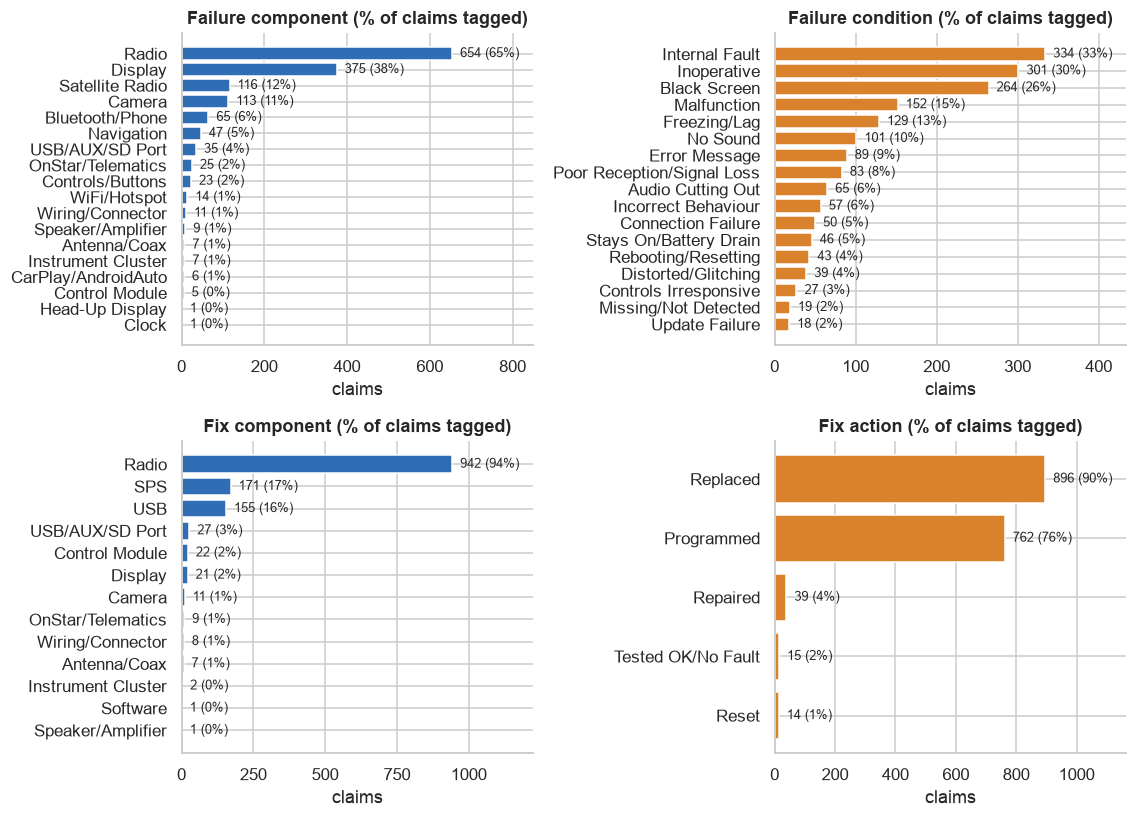

In [25]:
# ---- 4.12 What did we extract? Tag vocabularies ---------------------------------------------------------------------
def explode_pairs(col):
    return pd.DataFrame([(i, a, b) for i, ps in col.items() for a, b in set(ps)], columns=["row", "component", "condition"])

fail_long, fix_long = explode_pairs(M.fail_pairs), explode_pairs(M.fix_pairs)
uniq = lambda d, col: d[["row", col]].drop_duplicates()[col]      # count each CLAIM once per tag (not once per pair)
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.6))
barh_counts(axes[0, 0], uniq(fail_long, "component"), "Failure component (% of claims tagged)", pct_of=len(df))
barh_counts(axes[0, 1], uniq(fail_long, "condition"), "Failure condition (% of claims tagged)", pct_of=len(df), color=ORANGE)
barh_counts(axes[1, 0], uniq(fix_long[fix_long.component != "N/A"], "component"), "Fix component (% of claims tagged)", pct_of=len(df))
barh_counts(axes[1, 1], uniq(fix_long, "condition"), "Fix action (% of claims tagged)", pct_of=len(df), color=ORANGE)
savefig("fig03_tag_vocabularies")

## 5. Categorising the *type of issue*

The brief suggests categories such as *component failure* or *electrical issue*, "based upon observation/grouping of mined entities". Before choosing categories, look at what the entities say:

In [26]:
# How uniform is the repair? (this decides what a useful taxonomy can look like)
radio_replaced = M.fix_pairs.map(lambda p: ("Radio", "Replaced") in p)
radio_programmed = M.fix_pairs.map(lambda p: any(c in ("Radio", "SPS", "USB") and v == "Programmed" for c, v in p))
df["radio_replaced"], df["radio_programmed"] = radio_replaced, radio_programmed
FACTS["radio"] = {"replaced": float(radio_replaced.mean()), "programmed": float(radio_programmed.mean()), "both": float((radio_replaced & radio_programmed).mean()),
                  "programmed_only": float((~radio_replaced & radio_programmed).mean())}
print(f"Radio replaced in {radio_replaced.mean():.1%} of claims;  reprogrammed in {radio_programmed.mean():.1%};  both: {(radio_replaced & radio_programmed).mean():.1%}")
print(f"Programming only (radio NOT replaced): {(~radio_replaced & radio_programmed).mean():.1%}\n")

# ... and does it depend on the coded complaint or coded cause?
rr = (df.groupby("complaint_short").radio_replaced.agg(["mean", "size"]).rename(columns={"mean": "radio replaced", "size": "claims"}))
rr["radio replaced"] = rr["radio replaced"].map("{:.0%}".format)
display(rr.sort_values("claims", ascending=False))

Radio replaced in 88.3% of claims;  reprogrammed in 73.9%;  both: 66.5%
Programming only (radio NOT replaced): 7.4%



,radio replaced,claims
complaint_short,,
Audio/Ent/Nav: Audio,88%,337
Audio/Ent/Nav: Other issues,89%,263
Audio/Ent/Nav: Communication,90%,194
Audio/Ent/Nav: Video,91%,103
Features/Disp: Other issues,83%,47
Audio/Ent/Nav: Navigation,88%,32
Features/Disp: Gauges/Warning Lights,92%,12
Audio/Ent/Nav: Abnormal Noise,55%,11
Features/Disp: Odometer,100%,1


**Finding:** whatever the coded complaint - audio, video, navigation, communication - roughly **9 in 10 claims end with the radio replaced**. The structured codes therefore do not separate failure causes in any way that changes the repair. A useful taxonomy must come from *technician evidence* (what was found and done), not from those codes.

**Taxonomy (ordered from most to least specific evidence)**

| Issue category | Evidence required |
|---|---|
| Electrical / Wiring / Power Fault | Wiring/connector/coax repaired or replaced, or documented corrosion, chafing, open/short found, battery drain |
| Radio Hardware Failure | Explicit statement of internal fault / short / defective / failed radio |
| Communication / Network Fault | Documented loss of communication / data-bus fault (and no stronger cause) |
| Software / Programming Issue | Software/update/bulletin cause cited, or **reprogramming alone resolved it** |
| Peripheral / Accessory Failure | A non-radio part (camera, antenna, USB port, display, speaker...) replaced/repaired and the radio kept |
| No Fault Found / Not Duplicated | Could-not-duplicate and no repair action |
| Radio Replaced - Cause Not Documented | Radio replaced but the narrative gives no physical cause (typically "per TAC") |

Rules are applied in that order and the matched evidence is stored in `Issue Evidence`, so any assignment can be audited.

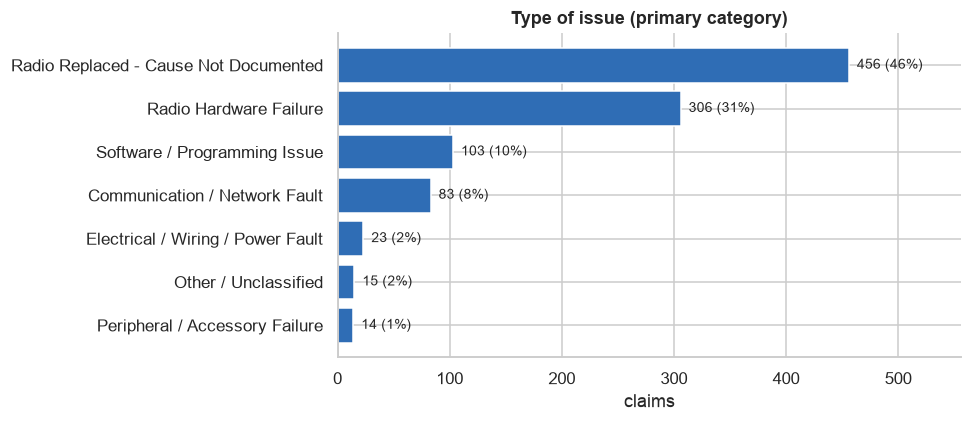

,claims,radio_replaced,tac_escalated,median_tis_days
Issue Category,,,,
Radio Replaced - Cause Not Documented,456,1.00,0.42,184.5
Radio Hardware Failure,306,0.98,0.23,250.5
Software / Programming Issue,103,0.28,0.34,246.0
Communication / Network Fault,83,0.98,0.28,286.5
Electrical / Wiring / Power Fault,23,0.78,0.35,265.0
Other / Unclassified,15,0.00,0.13,176.0
Peripheral / Accessory Failure,14,0.00,0.29,312.0


In [27]:
# Primary issue category distribution
cat_counts = df["Issue Category"].value_counts()
FACTS["issue_counts"] = {k: int(v) for k, v in cat_counts.items()}
fig, ax = plt.subplots(figsize=(9, 4))
vc = cat_counts.sort_values()
ax.barh(vc.index, vc.values, color=BLUE)
for y, v in enumerate(vc.values):
    ax.text(v, y, f"  {v:,} ({v/len(df):.0%})", va="center", fontsize=9)
ax.set_xlim(0, vc.max() * 1.22); ax.set_title("Type of issue (primary category)"); ax.set_xlabel("claims")
savefig("fig04_issue_categories")
display(df.groupby("Issue Category").agg(claims=("Event id", "size"), radio_replaced=("radio_replaced", "mean"),
                                         tac_escalated=("flag_tac_escalation", "mean"), median_tis_days=("tis_days_valid", "median")).round(2).sort_values("claims", ascending=False))

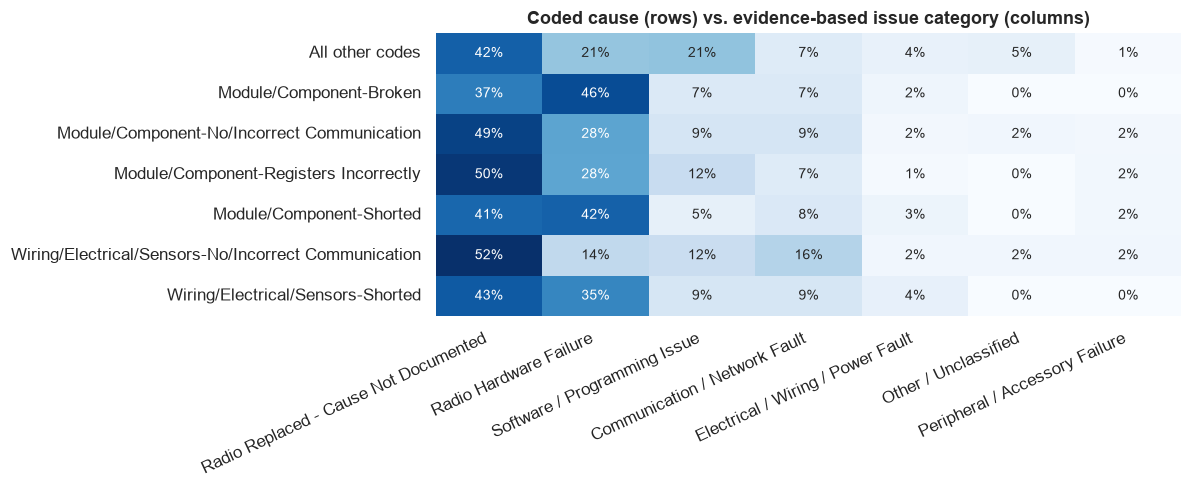

Of claims coded 'Module/Component-Shorted' (237), only 3% show electrical evidence; 42% are documented radio hardware failures and 41% have no documented cause.


In [28]:
# Does the coded CAUSE agree with what the technician evidence says?  (row-normalised: each row sums to 100%)
top_codes = df.CAUSAL_CD_DESC.value_counts().head(6).index
ct = pd.crosstab(df.CAUSAL_CD_DESC.where(df.CAUSAL_CD_DESC.isin(top_codes), "All other codes"), df["Issue Category"], normalize="index")
order = ct.mean().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(11, 4.6))
sns.heatmap(ct[order], annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 9})
ax.set_title("Coded cause (rows) vs. evidence-based issue category (columns)"); ax.set_xlabel(""); ax.set_ylabel("")
plt.xticks(rotation=25, ha="right")
savefig("fig05_coded_cause_vs_evidence")

shorted = df[df.CAUSAL_CD_DESC == "Module/Component-Shorted"]["Issue Category"].value_counts(normalize=True)
FACTS["shorted"] = {"n": int((df.CAUSAL_CD_DESC == "Module/Component-Shorted").sum()), **{k: float(v) for k, v in shorted.items()}}
print(f"Of claims coded 'Module/Component-Shorted' ({(df.CAUSAL_CD_DESC=='Module/Component-Shorted').sum()}), only "
      f"{shorted.get('Electrical / Wiring / Power Fault', 0):.0%} show electrical evidence; "
      f"{shorted.get('Radio Hardware Failure', 0):.0%} are documented radio hardware failures and {shorted.get('Radio Replaced - Cause Not Documented', 0):.0%} have no documented cause.")

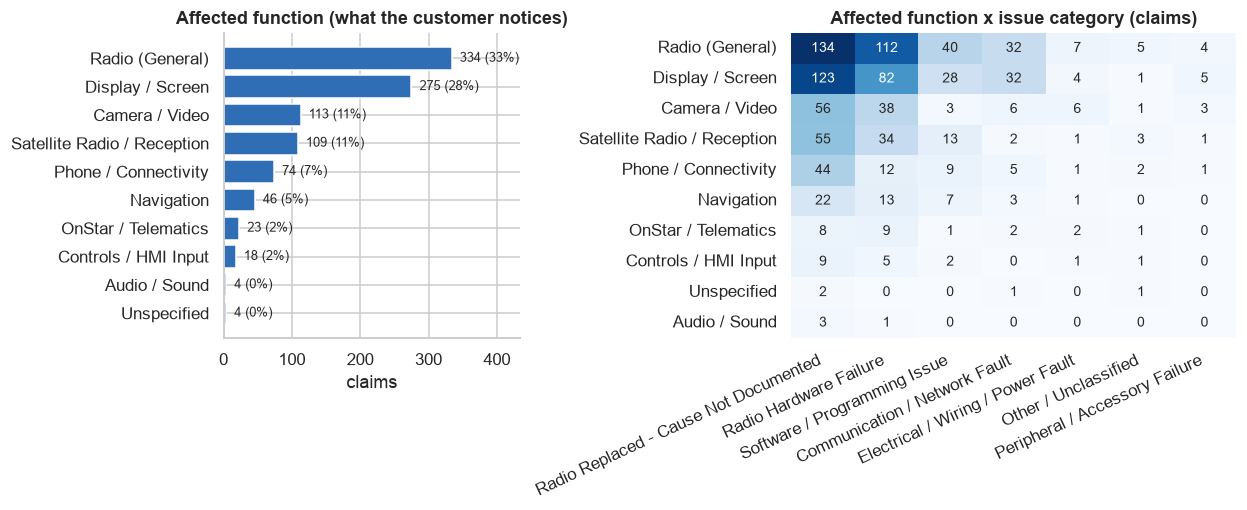

In [29]:
# Affected function (what the customer experiences) vs issue category
fn_order = df["Affected Function"].value_counts().index
ct2 = pd.crosstab(df["Affected Function"], df["Issue Category"]).loc[fn_order, cat_counts.index]   # columns ordered by size
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), gridspec_kw={"width_ratios": [1, 1.5]})
barh_counts(axes[0], df["Affected Function"], "Affected function (what the customer notices)")
sns.heatmap(ct2, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1], annot_kws={"size": 9})
axes[1].set_title("Affected function x issue category (claims)"); axes[1].set_ylabel(""); axes[1].set_xlabel("")
plt.setp(axes[1].get_xticklabels(), rotation=25, ha="right")
savefig("fig06_function_vs_issue")

## 6. Patterns, trends and significant changes

> **Reading caution.** All vehicles were built within five weeks, so *calendar time and vehicle age move together*: a change in the mix of claims over time is a change as the cohort ages. And with no production volumes, differences between plants/models are differences in **claim counts**, not defect rates.

### 6.1 What fails most often?
A Pareto of failure modes. A *failure mode* here is a (component, symptom) pair; the technician's own `Internal Fault` diagnosis is shown separately because it is a conclusion, not something a customer notices.

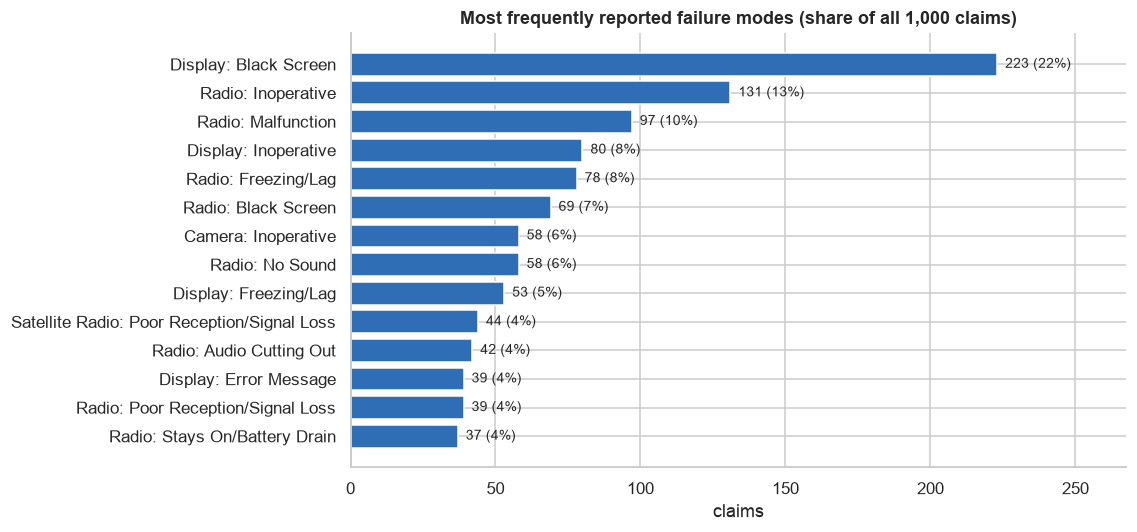

Technician diagnosed an internal fault in 33% of claims; the top-3 symptom modes cover 45% of claims (a claim can appear in several modes).


In [30]:
# Count each claim once per failure mode (a claim can show several)
modes = fail_long[["row", "component", "condition"]].drop_duplicates()
symptoms = modes[modes.condition != "Internal Fault"].copy()
symptoms["mode"] = symptoms.component + ": " + symptoms.condition
pareto = symptoms["mode"].value_counts().head(14)
share = pareto / len(df)

fig, ax = plt.subplots(figsize=(10.5, 5))
y = np.arange(len(pareto))[::-1]
ax.barh(y, pareto.values, color=BLUE)
for yi, v, s in zip(y, pareto.values, share.values):
    ax.text(v, yi, f"  {v} ({s:.0%})", va="center", fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(pareto.index); ax.set_xlim(0, pareto.max() * 1.2)
ax.set_title("Most frequently reported failure modes (share of all 1,000 claims)"); ax.set_xlabel("claims")
savefig("fig07_pareto_failure_modes")

internal = (M.fail_pairs.map(lambda p: any(v == "Internal Fault" for _, v in p))).mean()
FACTS["pareto"] = {k: int(v) for k, v in pareto.items()}; FACTS["internal_fault_share"] = float(internal)
print(f"Technician diagnosed an internal fault in {internal:.0%} of claims; the top-3 symptom modes cover "
      f"{symptoms.groupby('mode').row.nunique().nlargest(3).sum() / len(df):.0%} of claims (a claim can appear in several modes).")

### 6.2 Is the failure mix changing over time?
First the volume: a control chart with Poisson limits (baseline = calendar 2020, the steady-state year) shows which months are *statistically* unusual rather than just visibly different.

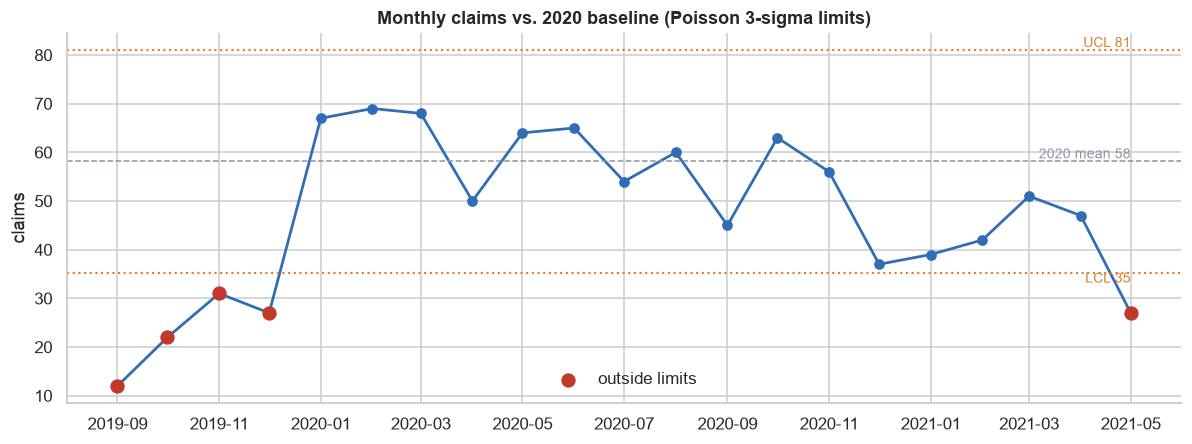

Months outside the limits: {'Sep 2019': 12, 'Oct 2019': 22, 'Nov 2019': 31, 'Dec 2019': 27, 'May 2021': 27}


In [31]:
# Poisson control chart: monthly claims with +/-3 sigma limits around the 2020 baseline
monthly = df.groupby("opened_month").size()
base = monthly["2020-01-01":"2020-12-01"]
mu = base.mean()
ucl, lcl = mu + 3 * np.sqrt(mu), max(mu - 3 * np.sqrt(mu), 0)
full = monthly.iloc[1:-1]                      # drop the two partial months (Aug-2019, Jun-2021)
flag = full[(full > ucl) | (full < lcl)]

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(full.index, full.values, marker="o", color=BLUE, lw=1.8)
ax.axhline(mu, color=GREY, ls="--", lw=1); ax.axhline(ucl, color=ORANGE, ls=":", lw=1.4); ax.axhline(lcl, color=ORANGE, ls=":", lw=1.4)
ax.text(full.index[-1], ucl, f" UCL {ucl:.0f}", color=ORANGE, va="bottom", ha="right", fontsize=9)
ax.text(full.index[-1], lcl, f" LCL {lcl:.0f}", color=ORANGE, va="top", ha="right", fontsize=9)
ax.text(full.index[-1], mu, f" 2020 mean {mu:.0f}", color=GREY, va="bottom", ha="right", fontsize=9)
ax.scatter(flag.index, flag.values, color="#C0392B", zorder=5, s=70, label="outside limits")
ax.set_title("Monthly claims vs. 2020 baseline (Poisson 3-sigma limits)"); ax.set_ylabel("claims"); ax.legend(frameon=False, loc="lower center")
savefig("fig08_control_chart")
print("Months outside the limits:", {k.strftime("%b %Y"): int(v) for k, v in flag.items()})
FACTS["control"] = {"mean2020": float(mu), "ucl": float(ucl), "lcl": float(lcl), "flagged": {k.strftime("%b %Y"): int(v) for k, v in flag.items()}}

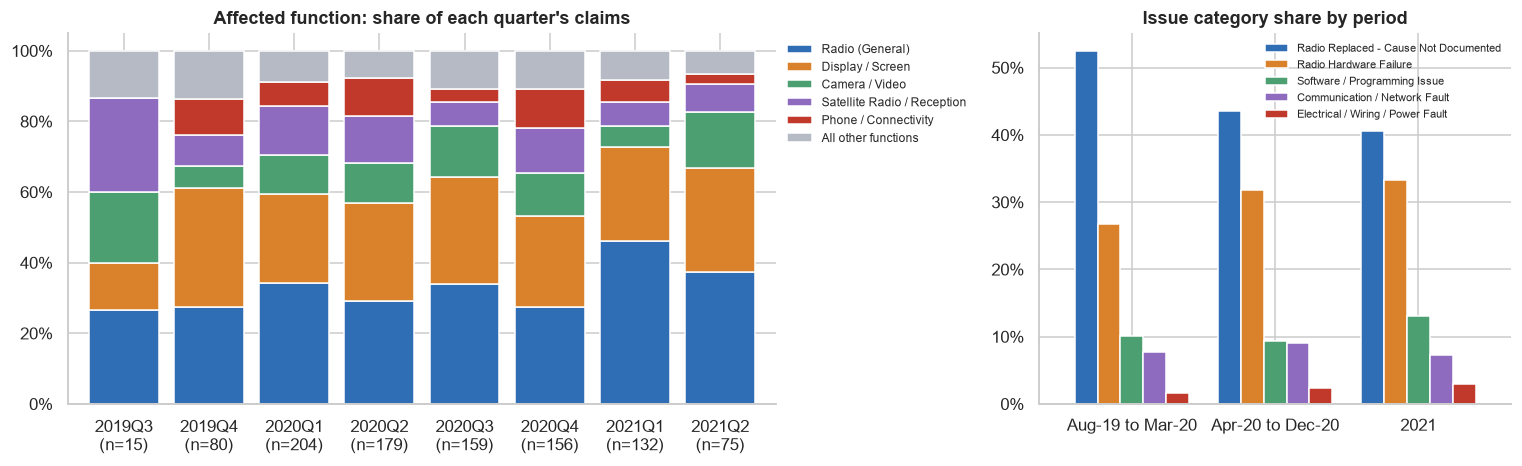

In [32]:
# Mix of claims over time: by quarter, as a share of that quarter's claims
q = df.groupby(["opened_quarter", "Affected Function"]).size().unstack(fill_value=0)
q_tot = q.sum(axis=1)
main = df["Affected Function"].value_counts().index[:5].tolist()
q_share = q[main].div(q_tot, axis=0)
q_share["All other functions"] = 1 - q_share.sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.5, 1]})
palette = ["#2F6DB5", "#D9822B", "#4C9F70", "#8E6BBF", "#C0392B", "#B5BAC4"]
q_share.plot(kind="bar", stacked=True, ax=axes[0], color=palette, width=.82)
axes[0].set_title("Affected function: share of each quarter's claims"); axes[0].set_xlabel(""); axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[0].legend(frameon=False, fontsize=8, bbox_to_anchor=(1.0, 1), loc="upper left"); axes[0].tick_params(axis="x", rotation=0)
axes[0].set_xticklabels([f"{lab}\n(n={n})" for lab, n in zip(q_share.index, q_tot.values)])      # claims per quarter under each bar

# Issue categories by period
period = pd.cut(df.opened_date, [pd.Timestamp("2019-01-01"), pd.Timestamp("2020-03-31"), pd.Timestamp("2020-12-31"), pd.Timestamp("2022-01-01")],
                labels=["Aug-19 to Mar-20", "Apr-20 to Dec-20", "2021"])
df["period"] = period
cat_by_period = pd.crosstab(df.period, df["Issue Category"], normalize="index")[cat_counts.index[:5]]
cat_by_period.plot(kind="bar", ax=axes[1], color=palette[:5], width=.8)
axes[1].set_title("Issue category share by period"); axes[1].set_xlabel(""); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[1].legend(frameon=False, fontsize=7.5); axes[1].tick_params(axis="x", rotation=0)
savefig("fig09_mix_over_time")

In [33]:
# Are those shifts statistically real?  Chi-square across the three periods for each category, then Benjamini-Hochberg
# correction (we test many categories, so some "significant" results would appear by chance).
def bh(pvals):
    """Benjamini-Hochberg adjusted p-values (controls the false-discovery rate)."""
    p = np.asarray(pvals); n = len(p); order = np.argsort(p)
    adj = np.empty(n); prev = 1.0
    for rank, i in zip(range(n, 0, -1), order[::-1]):
        prev = min(prev, p[i] * n / rank); adj[i] = prev
    return adj

df["mentions_update"] = df.CUSTOMER_VERBATIM.fillna("").str.contains(r"updat", case=False)   # rule-based, independent of any clustering

# Claim-level 0/1 indicators for every thing we might test: affected function, issue category, each failure condition, update mentions.
indicators = []
for label, col in [("Affected function", "Affected Function"), ("Issue category", "Issue Category")]:
    for v in df[col].value_counts().index:
        indicators.append((label, v, df[col] == v))
cond_has = lambda c: M.fail_pairs.map(lambda p: any(v == c for _, v in p))
for c in sorted({v for ps in M.fail_pairs for _, v in ps}):
    indicators.append(("Failure condition", c, cond_has(c)))
indicators.append(("Complaint wording", "mentions a software update", df.mentions_update))

rows = []
for dim, name, ind in indicators:
    ind = pd.Series(np.asarray(ind), index=df.index)
    if ind.sum() < 15:                           # too few claims for a meaningful test
        continue
    chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(df.period, ind), correction=False)
    sh = ind.groupby(df.period, observed=True).mean().values
    rows.append({"dimension": dim, "category": name, "claims": int(ind.sum()), "share early": sh[0], "share mid": sh[1], "share 2021": sh[2], "p": p})
trend = pd.DataFrame(rows)
trend["p_adj (BH)"] = bh(trend.p.values)
trend["significant"] = np.where(trend["p_adj (BH)"] < 0.05, "YES", "")
print(f"{len(trend)} categories tested together; BH correction controls the false-discovery rate across all of them.")
for c in ["share early", "share mid", "share 2021"]:
    trend[c] = trend[c].map("{:.1%}".format)
trend["p"] = trend.p.map("{:.3f}".format); trend["p_adj (BH)"] = trend["p_adj (BH)"].map("{:.3f}".format)
display(trend.sort_values("p_adj (BH)"))
FACTS["trend"] = trend.sort_values("p_adj (BH)").to_dict("records")

32 categories tested together; BH correction controls the false-discovery rate across all of them.


,dimension,category,claims,share early,share mid,share 2021,p,p_adj (BH),significant
29,Failure condition,Stays On/Battery Drain,46,4.0%,2.2%,11.1%,0.000,0.000,YES
0,Affected function,Radio (General),334,32.1%,30.2%,43.0%,0.004,0.062,
31,Complaint wording,mentions a software update,48,5.7%,2.8%,8.2%,0.007,0.073,
8,Issue category,Radio Replaced - Cause Not Documented,456,52.5%,43.5%,40.6%,0.013,0.102,
27,Failure condition,Poor Reception/Signal Loss,83,7.4%,10.5%,4.3%,0.020,0.129,
15,Failure condition,Black Screen,264,21.4%,30.0%,25.1%,0.027,0.143,
22,Failure condition,Inoperative,301,33.8%,30.6%,23.7%,0.049,0.195,
20,Failure condition,Freezing/Lag,129,12.7%,10.9%,17.9%,0.043,0.195,
30,Failure condition,Update Failure,18,2.7%,0.8%,2.9%,0.066,0.233,
17,Failure condition,Controls Irresponsive,27,2.7%,1.8%,4.8%,0.081,0.259,


**One change survives the correction: "stays on / won't shut off / drains the battery".** Everything else in the table is either noise or, at best, borderline. This failure condition (the customer reports the radio or screen staying powered after the vehicle is switched off, sometimes with a flat battery) rises sharply in 2021. A closer look, with 95% Wilson confidence intervals:

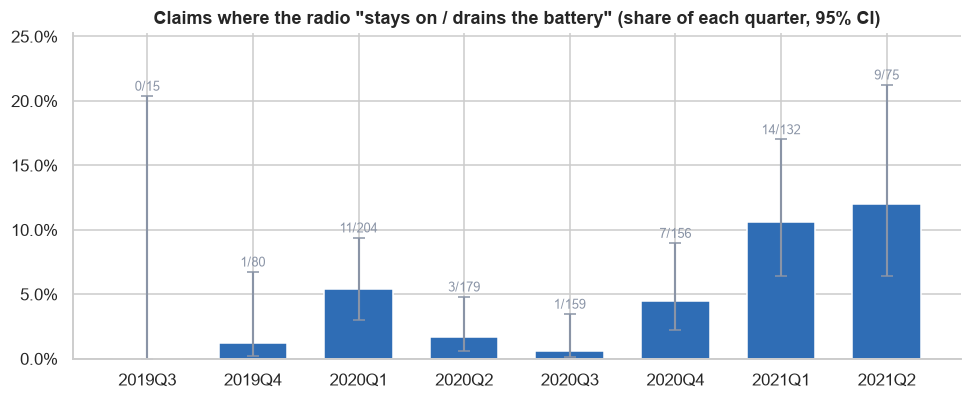

,stays-on claims,all other claims
claims,46,954
radio replaced,83%,89%
reprogrammed WITHOUT replacing,11%,7%
escalated to TAC,13%,34%
service bulletin cited,17%,12%
median time in service (days),309,226
repeat visit,7%,9%


Trigger wording in these claims: 0.72 have no extra context; 57% are tagged trigger = After Ignition Off.
  e.g. CHECK AND ADVISE ON RADIO WILL CHANGE FROM FM TO XM ON ITS OWN INTERMI TTENTLY WHEN VEHICLE IS FIRST STARTED, HAPPENS AS SOON ASRA
  e.g. CUST STATES RADIO WILL NOT TURN OFF PLEASE CHECK AND ADVISE
  e.g. CUSTOMER STATES THAT THE NAVIGATIONS RADIO SCREEN WILL NOT TURN OFF WHEN THE VEHICLE IS SHUT OFF INSPECT AND ADVISE
  e.g. C/S: CUSTOMER STATES THE RADIO WILL STAY ON FOR   SECS AND TURN OFF F OR   SECS. RADIO SCREEN WILL GO BLACK AND HAVE CHEVY LOGOCOM


In [34]:
df["stays_on"] = cond_has("Stays On/Battery Drain").values
qs = df.groupby("opened_quarter").stays_on.agg(k="sum", n="size")
def wilson(k, n, z=1.96):
    """95% Wilson score interval for a proportion (well behaved for small counts)."""
    p = k / n; d = 1 + z**2 / n; c = p + z**2 / (2 * n); w = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
    return (c - w) / d, (c + w) / d
qs["share"] = qs.k / qs.n
qs["lo"], qs["hi"] = zip(*[wilson(k, n) for k, n in zip(qs.k, qs.n)])

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(qs.index, qs.share, color=BLUE, width=.65)
ax.errorbar(qs.index, qs.share, yerr=[qs.share - qs.lo, qs.hi - qs.share], fmt="none", ecolor=GREY, capsize=4, lw=1.4)
for i, (k, n) in enumerate(zip(qs.k, qs.n)):
    ax.text(i, qs.hi.iloc[i] + .004, f"{k}/{n}", ha="center", fontsize=8.5, color=GREY)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_ylim(0, qs.hi.max() + .04)
ax.set_title('Claims where the radio "stays on / drains the battery" (share of each quarter, 95% CI)'); ax.set_xlabel("")
savefig("fig09b_stays_on_trend")

so, rest = df[df.stays_on], df[~df.stays_on]
cmp = pd.DataFrame({
    "stays-on claims": [len(so), so.radio_replaced.mean(), (~so.radio_replaced & so.radio_programmed).mean(), so.flag_tac_escalation.mean(), so.flag_bulletin_cited.mean(), so.tis_days_valid.median(),
                        so["Additional Context"].str.contains("Repeat").mean()],
    "all other claims": [len(rest), rest.radio_replaced.mean(), (~rest.radio_replaced & rest.radio_programmed).mean(), rest.flag_tac_escalation.mean(), rest.flag_bulletin_cited.mean(), rest.tis_days_valid.median(),
                         rest["Additional Context"].str.contains("Repeat").mean()],
}, index=["claims", "radio replaced", "reprogrammed WITHOUT replacing", "escalated to TAC", "service bulletin cited", "median time in service (days)", "repeat visit"])
fmt = lambda col: [f"{v:,.0f}" if i in (0, 5) else f"{v:.0%}" for i, v in enumerate(col)]
display(pd.DataFrame({c: fmt(cmp[c]) for c in cmp}, index=cmp.index))
print("Trigger wording in these claims:", so["Additional Context"].eq("['No Additional Context']").mean().round(2), "have no extra context;",
      f"{so.Trigger.str.contains('After Ignition Off').mean():.0%} are tagged trigger = After Ignition Off.")
for t in so[so.opened_date >= "2021-01-01"].CUSTOMER_VERBATIM.head(4):
    print("  e.g.", t[:130])
FACTS["stays_on"] = {"claims": int(len(so)), "by_quarter": {k: {"k": int(r.k), "n": int(r.n), "share": float(r.share), "lo": float(r.lo), "hi": float(r.hi)} for k, r in qs.iterrows()},
                     "radio_replaced": float(so.radio_replaced.mean()), "radio_replaced_rest": float(rest.radio_replaced.mean()),
                     "prog_only": float((~so.radio_replaced & so.radio_programmed).mean()), "prog_only_rest": float((~rest.radio_replaced & rest.radio_programmed).mean()),
                     "tac": float(so.flag_tac_escalation.mean()), "tac_rest": float(rest.flag_tac_escalation.mean()),
                     "median_tis": float(so.tis_days_valid.median()), "median_tis_rest": float(rest.tis_days_valid.median()),
                     "after_ignition_off": float(so.Trigger.str.contains("After Ignition Off").mean())}

**An exploratory check on software updates.** Software/OTA update problems are a classic growing issue as a fleet ages. A simple, rule-based measure - the customer's own words mention an *update* - avoids depending on any clustering:

In [35]:
upd = df.groupby("period", observed=True).mentions_update.agg(claims="sum", share="mean")
display(upd.assign(share=upd.share.map("{:.1%}".format)))
chi2, p_upd, _, _ = stats.chi2_contingency(pd.crosstab(df.period, df.mentions_update), correction=False)
p_fisher = stats.fisher_exact(pd.crosstab(df.period == "2021", df.mentions_update))[1]
print(f"Update-related complaints: {int(df.mentions_update.sum())} claims ({df.mentions_update.mean():.1%}).  Across the 3 periods p = {p_upd:.3f}; 2021 vs. earlier (Fisher) p = {p_fisher:.3f}.")
FACTS["update"] = {"claims": int(df.mentions_update.sum()), "share": float(df.mentions_update.mean()), "p_chi": float(p_upd), "p_fisher": float(p_fisher),
                   "by_period": {str(k): {"claims": int(r.claims), "share": float(r.share)} for k, r in upd.iterrows()}}
print("EXPLORATORY: this was one of several looks at the data and is not corrected for multiple testing; the share dips in mid-2020 and rises in 2021 (not a steady trend).")

,claims,share
period,,
Aug-19 to Mar-20,17,5.7%
Apr-20 to Dec-20,14,2.8%
2021,17,8.2%


Update-related complaints: 48 claims (4.8%).  Across the 3 periods p = 0.007; 2021 vs. earlier (Fisher) p = 0.016.
EXPLORATORY: this was one of several looks at the data and is not corrected for multiple testing; the share dips in mid-2020 and rises in 2021 (not a steady trend).


### 6.3 How soon after purchase do claims arrive?
Time in service is the closest thing in this dataset to a reliability curve.

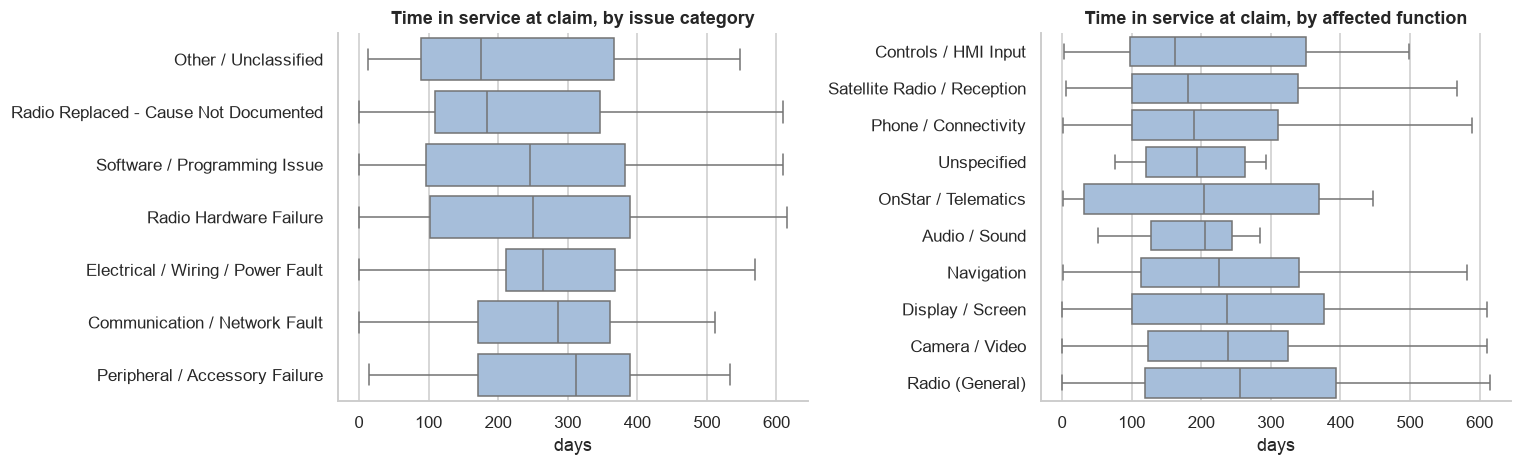

Kruskal-Wallis of time-in-service across Issue Category: H=8.7, p=0.123
Kruskal-Wallis of time-in-service across Affected Function: H=7.3, p=0.403

21% of claims occur within 90 days of the vehicle entering service - these are infant-mortality failures a better end-of-line test could catch.


In [36]:
valid = df[df.tis_days_valid.notna()]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
order = valid.groupby("Issue Category").tis_days_valid.median().sort_values().index
sns.boxplot(data=valid, y="Issue Category", x="tis_days_valid", order=order, color="#9DBDE3", ax=axes[0], fliersize=2)
axes[0].set_title("Time in service at claim, by issue category"); axes[0].set_xlabel("days"); axes[0].set_ylabel("")
order2 = valid.groupby("Affected Function").tis_days_valid.median().sort_values().index
sns.boxplot(data=valid, y="Affected Function", x="tis_days_valid", order=order2, color="#9DBDE3", ax=axes[1], fliersize=2)
axes[1].set_title("Time in service at claim, by affected function"); axes[1].set_xlabel("days"); axes[1].set_ylabel("")
savefig("fig10_tis_by_category")

for col in ["Issue Category", "Affected Function"]:
    groups = [g.tis_days_valid.values for _, g in valid.groupby(col) if len(g) >= 15]
    h, p = stats.kruskal(*groups)
    print(f"Kruskal-Wallis of time-in-service across {col}: H={h:.1f}, p={p:.3g}")
    FACTS.setdefault("kruskal", {})[col] = {"H": float(h), "p": float(p)}
early = (valid.tis_days_valid <= 90).mean()
print(f"\n{early:.0%} of claims occur within 90 days of the vehicle entering service - these are infant-mortality failures a better end-of-line test could catch.")

### 6.4 Do failures concentrate in particular plants or models?
Standardised (adjusted) residuals from a chi-square table show *which cells* are over- or under-represented. |z| >= 3 with at least 10 claims is a conservative flag. Remember: counts, not rates.

In [37]:
def concentration(a, b, min_n=10, z_cut=3.0, data=None):
    """Return the cells of crosstab(a,b) whose adjusted standardised residual exceeds z_cut (over-represented)."""
    data = df if data is None else data
    ct = pd.crosstab(data[a], data[b])
    chi2, p, dof, exp = stats.chi2_contingency(ct, correction=False)
    n = ct.values.sum(); rp = ct.sum(axis=1).values[:, None] / n; cp = ct.sum(axis=0).values[None, :] / n
    z = (ct.values - exp) / np.sqrt(exp * (1 - rp) * (1 - cp))
    out = []
    for i, r in enumerate(ct.index):
        for j, c in enumerate(ct.columns):
            if abs(z[i, j]) >= z_cut and ct.values[i, j] >= min_n:
                out.append({a: r, b: c, "claims": int(ct.values[i, j]), "expected": round(exp[i, j], 1), "z": round(z[i, j], 1)})
    cv = np.sqrt((chi2 / n) / (min(ct.shape) - 1))
    out = pd.DataFrame(out)
    # Bonferroni: with many cells some |z|>=3 are expected by chance, so also report the stricter family-wise threshold
    z_bonf = stats.norm.ppf(1 - 0.05 / (2 * ct.size))
    if len(out):
        out["survives Bonferroni"] = np.where(out.z.abs() >= z_bonf, "YES", "no")
    return out, p, cv, z_bonf

for a, b in [("BUILD_PLANT_DESC", "Affected Function"), ("BUILD_PLANT_DESC", "Issue Category"), ("model_grp", "Affected Function"),
             ("model_grp", "Issue Category"), ("MAKE", "Affected Function"), ("MAKE", "Issue Category")]:
    res, p, cv, zb = concentration(a, b)
    print(f"{a} x {b}: chi-square p={p:.3g}, Cramer's V={cv:.2f}, Bonferroni |z| threshold={zb:.1f}  ->  {len(res)} cell(s) with |z|>=3")
    FACTS.setdefault("concentration", {})[f"{a} x {b}"] = {"p": float(p), "V": float(cv), "z_bonf": float(zb), "cells": res.to_dict("records") if len(res) else []}
    if len(res):
        display(res.sort_values("z", ascending=False))

BUILD_PLANT_DESC x Affected Function: chi-square p=0.572, Cramer's V=0.09, Bonferroni |z| threshold=3.4  ->  0 cell(s) with |z|>=3
BUILD_PLANT_DESC x Issue Category: chi-square p=0.666, Cramer's V=0.08, Bonferroni |z| threshold=3.3  ->  1 cell(s) with |z|>=3


,BUILD_PLANT_DESC,Issue Category,claims,expected,z,survives Bonferroni
0,Spring Hill - Truck,Software / Programming Issue,29,17.4,3.2,no


model_grp x Affected Function: chi-square p=1.23e-05, Cramer's V=0.16, Bonferroni |z| threshold=3.6  ->  4 cell(s) with |z|>=3


,model_grp,Affected Function,claims,expected,z,survives Bonferroni
0,FusionNova,Camera / Video,18,6.7,4.8,YES
1,HyperFury X,Camera / Video,30,16.7,3.7,YES
3,StellarGlide,Camera / Video,16,7.0,3.7,YES
2,ShadowPulse,Satellite Radio / Reception,14,6.6,3.1,no


model_grp x Issue Category: chi-square p=0.325, Cramer's V=0.13, Bonferroni |z| threshold=3.5  ->  0 cell(s) with |z|>=3
MAKE x Affected Function: chi-square p=0.0401, Cramer's V=0.12, Bonferroni |z| threshold=3.2  ->  1 cell(s) with |z|>=3


,MAKE,Affected Function,claims,expected,z,survives Bonferroni
0,NebulaCruiser,Camera / Video,26,14.1,3.6,YES


MAKE x Issue Category: chi-square p=0.259, Cramer's V=0.08, Bonferroni |z| threshold=3.1  ->  0 cell(s) with |z|>=3


In [38]:
# The repair itself should not depend on the plant if the cause is common-mode.  Check the radio-replacement rate by plant / model.
for col in ["BUILD_PLANT_DESC", "model_grp"]:
    t = df.groupby(col).agg(claims=("Event id", "size"), radio_replaced=("radio_replaced", "mean"), tac=("flag_tac_escalation", "mean"))
    t = t[t.claims >= 30].sort_values("radio_replaced")
    t["radio_replaced"] = t.radio_replaced.map("{:.0%}".format); t["tac"] = t.tac.map("{:.0%}".format)
    display(t.rename(columns={"tac": "escalated to TAC"}))
chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(df.BUILD_PLANT_DESC[df.BUILD_PLANT_DESC.map(df.BUILD_PLANT_DESC.value_counts()) >= 30], df.radio_replaced), correction=False)
print(f"Radio-replacement rate vs. plant (plants with >=30 claims): chi-square p = {p:.3f}")
FACTS["radio_by_plant_p"] = float(p)
FACTS["radio_by_plant"] = df.groupby("BUILD_PLANT_DESC").radio_replaced.agg(["mean", "size"]).query("size >= 30")["mean"].round(3).to_dict()

,claims,radio_replaced,escalated to TAC
BUILD_PLANT_DESC,,,
Fort Wayne,217,83%,32%
Spring Hill - Truck,169,86%,34%
Flint,208,88%,37%
Ramos Arizpe,39,90%,33%
Silao,199,90%,32%
Lansing Delta,142,94%,32%


,claims,radio_replaced,escalated to TAC
model_grp,,,
StellarGlide,62,82%,24%
AeroSpecter,86,84%,27%
NebulaJet,77,86%,35%
ElectroStreak,75,87%,29%
ThunderBlitz,46,87%,33%
FusionNova,59,88%,34%
ShadowPulse,61,89%,34%
QuantumRider,109,89%,39%
SolarStriker,52,90%,29%


Radio-replacement rate vs. plant (plants with >=30 claims): chi-square p = 0.066


### 6.5 The repair path: how much effort goes into each claim?

In [39]:
tac = df.flag_tac_escalation
path = pd.Series({
    "Radio replaced": df.radio_replaced.mean(),
    "Radio replaced AND reprogrammed": (df.radio_replaced & df.radio_programmed).mean(),
    "Escalated to technical assistance (TAC / Techline / engineering)": tac.mean(),
    "  ...of which ended in radio replacement": (tac & df.radio_replaced).sum() / tac.sum(),
    "Radio reprogrammed WITHOUT being replaced": (~df.radio_replaced & df.radio_programmed).mean(),
    "Software fix tried and reported as not working": df.flag_software_fix_failed.mean(),
    "Radio replaced with 'no DTC / no codes' recorded": (df.radio_replaced & df.flag_no_dtc_found).mean(),
    "Parts on order / waiting for parts": df.flag_parts_wait.mean(),
    "Loaner / rental / shuttle mentioned": df.flag_loaner_or_rental.mean(),
    "Customer says it is a repeat visit": df["Additional Context"].str.contains("Repeat Visit").mean(),
    "Could-not-duplicate / no fault found": df.flag_no_fault_found.mean(),
}, name="share of claims").map("{:.1%}".format).to_frame()
display(path)
FACTS["repair_path"] = path["share of claims"].to_dict()

esc = df.groupby("Issue Category").agg(claims=("Event id", "size"), escalated=("flag_tac_escalation", "mean"), repeat=("Additional Context", lambda s: s.str.contains("Repeat").mean()),
                                       sw_failed=("flag_software_fix_failed", "mean")).sort_values("claims", ascending=False)
display(esc.round(2))

,share of claims
Radio replaced,88.3%
Radio replaced AND reprogrammed,66.5%
Escalated to technical assistance (TAC / Techline / engineering),33.3%
...of which ended in radio replacement,91.9%
Radio reprogrammed WITHOUT being replaced,7.4%
Software fix tried and reported as not working,2.8%
Radio replaced with 'no DTC / no codes' recorded,15.8%
Parts on order / waiting for parts,7.6%
Loaner / rental / shuttle mentioned,1.2%
Customer says it is a repeat visit,9.2%


,claims,escalated,repeat,sw_failed
Issue Category,,,,
Radio Replaced - Cause Not Documented,456,0.42,0.11,0.02
Radio Hardware Failure,306,0.23,0.08,0.03
Software / Programming Issue,103,0.34,0.13,0.05
Communication / Network Fault,83,0.28,0.01,0.02
Electrical / Wiring / Power Fault,23,0.35,0.09,0.09
Other / Unclassified,15,0.13,0.07,0.00
Peripheral / Accessory Failure,14,0.29,0.07,0.14


## 7. Grouping failure modes with clustering and topic modelling

Rule-based tags tell us *what we already knew to look for*. Unsupervised methods ask the data what natural groups exist, and act as a check on the taxonomy. Three complementary views:

| View | Text used | Method | Question |
|---|---|---|---|
| A. Symptom clusters | customer concern | TF-IDF -> LSA -> K-Means | What kinds of complaints do customers report? |
| B. Repair/root-cause topics | diagnosis + repair narrative | TF-IDF -> NMF topic model | What do technicians find and do? |
| C. Semantic cross-check | customer concern | sentence embeddings (`all-MiniLM-L6-v2`) -> K-Means | Do the groups survive a different representation? |

### 7.1 Prepare the text for modelling

In [40]:
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD, NMF
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.preprocessing import Normalizer
from sklearn.manifold import TSNE

# Words that are boiler-plate in warranty narratives and would otherwise dominate every topic
DOMAIN_STOP = {"customer", "states", "state", "stated", "reports", "reported", "check", "advise", "advice", "please", "vehicle", "truck", "car",
               "cust", "per", "tac", "case", "found", "verified", "verify", "concern", "performed", "tech", "technician", "inspect", "inspected",
               "diagnosis", "diag", "complete", "completed", "operation", "operates", "designed", "tested", "testing", "warranty", "wcc", "code", "codes",
               "sop", "here", "guest", "owner", "dealer", "doc", "document", "id", "ro", "time", "times", "sometimes", "intermittent", "intermittently",
               "radio", "unit", "assembly", "module", "new", "reported", "also", "using", "used", "need", "needs", "needed", "advised", "contacted", "called"}
# keep negations ("not working", "no sound") - sklearn's default list would delete them and turn "not working" into "working"
NEGATIONS = {"not", "no", "never", "nor", "cannot", "without"}
STOP = list((ENGLISH_STOP_WORDS - NEGATIONS) | DOMAIN_STOP)

# Symptom text = the customer's concern (normalised, fragments repaired). Where the "concern" is only a pasted category label,
# fall back to the opening of the diagnosis so those 8 rows still carry information.
sym = [normalise(r.CAUSAL_VERBATIM)[:250] if r.customer_placeholder else normalise(r.CUSTOMER_VERBATIM) for r in df.itertuples()]
# Repair text = diagnosis + repair narrative
rep_txt = [normalise(r.CAUSAL_VERBATIM) + " " + normalise(r.CORRECTION_VERBATIM) for r in df.itertuples()]
df["symptom_text"], df["repair_text"] = sym, rep_txt

# The 16 Spanish/French rows cannot be clustered with an English vocabulary (they would all land in one meaningless group),
# so the vocabulary is learned from English rows and the non-English rows are reported separately as "Non-English".
is_en = (df.Language == "English").values
tf_sym = TfidfVectorizer(stop_words=STOP, token_pattern=r"[a-z]{2,}", ngram_range=(1, 2), min_df=5, max_df=0.5, sublinear_tf=True)
tf_sym.fit(df.symptom_text[is_en])
X_sym = tf_sym.transform(df.symptom_text)
print(f"Symptom TF-IDF matrix: {X_sym.shape}   (English rows clustered: {is_en.sum()}; non-English held out: {(~is_en).sum()})")

Symptom TF-IDF matrix: (1000, 360)   (English rows clustered: 983; non-English held out: 17)


### 7.2 View A - symptom clusters (K-Means on LSA vectors)

Short texts give very sparse TF-IDF vectors, so they are first compressed with truncated SVD (latent semantic analysis, 60 dimensions) and L2-normalised, which makes Euclidean K-Means behave like cosine K-Means. The number of clusters is chosen with the silhouette score, restricted to 5-10 so that clusters stay interpretable.

LSA explains 53% of the variance in 60 components


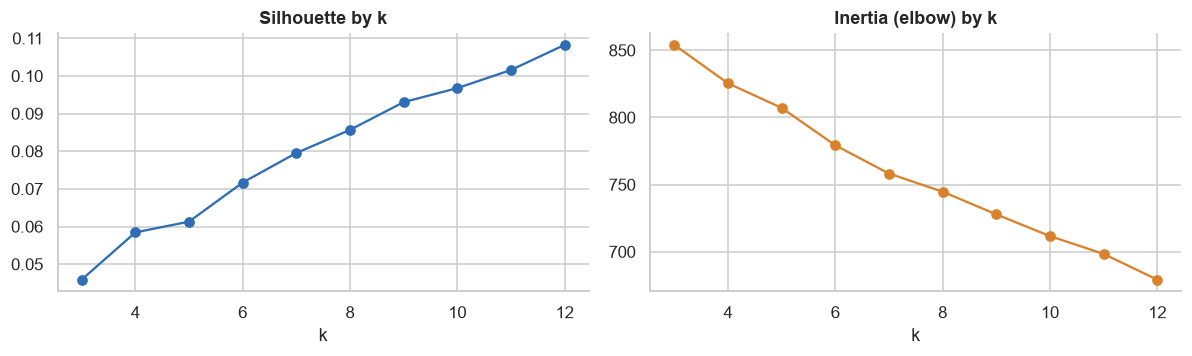

Chosen k = 10 (best silhouette within 5-10: 0.097).  Silhouette this low is normal for short free text: groups overlap, so treat clusters as a lens, not as hard classes.


In [41]:
svd = TruncatedSVD(n_components=60, random_state=SEED)
svd.fit(X_sym[is_en])
Z_sym = Normalizer(copy=False).fit_transform(svd.transform(X_sym))
print(f"LSA explains {svd.explained_variance_ratio_.sum():.0%} of the variance in 60 components")

# Model selection: silhouette and inertia for k = 3..12
rows = []
for k in range(3, 13):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z_sym[is_en])
    rows.append({"k": k, "silhouette": silhouette_score(Z_sym[is_en], km.labels_), "inertia": km.inertia_})
sel = pd.DataFrame(rows).set_index("k")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(sel.index, sel.silhouette, marker="o", color=BLUE); ax[0].set_title("Silhouette by k"); ax[0].set_xlabel("k")
ax[1].plot(sel.index, sel.inertia, marker="o", color=ORANGE); ax[1].set_title("Inertia (elbow) by k"); ax[1].set_xlabel("k")
savefig("fig11_kmeans_selection")

K = int(sel.loc[5:10, "silhouette"].idxmax())
FACTS["kmeans"] = {"K": int(K), "silhouette": float(sel.loc[K, "silhouette"]), "selection": sel.round(3).to_dict("index")}
print(f"Chosen k = {K} (best silhouette within 5-10: {sel.loc[K, 'silhouette']:.3f}).  Silhouette this low is normal for short free text: "
      f"groups overlap, so treat clusters as a lens, not as hard classes.")
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Z_sym[is_en])
df["symptom_cluster"] = -1                              # -1 = non-English rows (not clustered)
df.loc[is_en, "symptom_cluster"] = km.labels_

In [42]:
# How stable is the solution?  Re-run K-Means with different seeds and compare each run with the chosen one (ARI: 1 = identical).
aris = [adjusted_rand_score(km.labels_, KMeans(n_clusters=K, n_init=10, random_state=s).fit(Z_sym[is_en]).labels_) for s in range(1, 9)]
FACTS["kmeans_stability"] = {"mean_ari": float(np.mean(aris)), "min_ari": float(np.min(aris))}
print(f"Stability across 8 random restarts: mean ARI = {np.mean(aris):.2f} (min {np.min(aris):.2f}).  "
      f"Clusters of short text are fuzzy, so the report relies on broad groups and on findings that two independent views agree on.")

Stability across 8 random restarts: mean ARI = 0.49 (min 0.35).  Clusters of short text are fuzzy, so the report relies on broad groups and on findings that two independent views agree on.


In [43]:
# Describe each cluster: distinctive words (highest mean TF-IDF inside the cluster relative to everywhere else), size, and profile
terms = np.array(tf_sym.get_feature_names_out())
overall = np.asarray(X_sym.mean(axis=0)).ravel()
profile_rows = []
for c in range(K):
    idx = np.where(df.symptom_cluster == c)[0]
    inside = np.asarray(X_sym[idx].mean(axis=0)).ravel()
    top = terms[np.argsort(inside - overall)[::-1][:8]]
    sub = df.iloc[idx]
    profile_rows.append({
        "cluster": c, "claims": len(idx), "share": f"{len(idx)/len(df):.0%}", "distinctive terms": ", ".join(top),
        "main function": sub["Affected Function"].value_counts().index[0], "function share": f"{sub['Affected Function'].value_counts(normalize=True).iloc[0]:.0%}",
        "radio replaced": f"{sub.radio_replaced.mean():.0%}", "median TIS (d)": int(sub.tis_days_valid.median()),
        "top issue category": sub["Issue Category"].value_counts().index[0],
    })
cluster_profile = pd.DataFrame(profile_rows).set_index("cluster").sort_values("claims", ascending=False)
display(cluster_profile)
FACTS["clusters"] = cluster_profile.reset_index().to_dict("records")

# A short, auto-generated label for each cluster from its top terms (kept deterministic so the notebook can be re-run)
LABEL = {c: " / ".join(cluster_profile.loc[c, "distinctive terms"].split(", ")[:3]) for c in cluster_profile.index}
df["symptom_cluster_label"] = df.symptom_cluster.map(lambda c: "Non-English" if c < 0 else f"C{c}: {LABEL[c]}")

,claims,share,distinctive terms,main function,function share,radio replaced,median TIS (d),top issue category
cluster,,,,,,,,
1,366,37%,"shut, stays, update, turning, message, failed, ordered, door",Radio (General),50%,87%,220,Radio Replaced - Cause Not Documented
4,89,9%,"blank, screen, goes blank, screen blank, goes, screen goes, blank screen, cue screen",Display / Screen,73%,91%,250,Radio Replaced - Cause Not Documented
9,86,9%,"no, sound, no sound, no volume, display, coming, no audio, volume",Radio (General),48%,88%,228,Radio Replaced - Cause Not Documented
0,83,8%,"black, screen black, screen, goes black, goes, screen goes, black screen, display",Display / Screen,64%,89%,240,Radio Replaced - Cause Not Documented
8,80,8%,"xm, signal, stations, play, change, xm not, loading, sirius",Satellite Radio / Reception,79%,91%,180,Radio Replaced - Cause Not Documented
7,76,8%,"does, does not, work, not work, not, turn, not turn, camera does",Radio (General),30%,89%,262,Radio Replaced - Cause Not Documented
3,74,7%,"inop, camera inop, screen inop, camera, xm inop, display inop, vehicles, electrical",Camera / Video,30%,93%,230,Radio Replaced - Cause Not Documented
5,62,6%,"working, not working, not, camera not, cameras, camera, navigation, working properly",Camera / Video,32%,84%,229,Radio Hardware Failure
2,37,4%,"phone, bluetooth, pair, connect, contacts, not connect, phone not, calls",Phone / Connectivity,84%,92%,206,Radio Replaced - Cause Not Documented


In [44]:
# Example customer verbatims from each cluster (the closest to the centre are the most representative)
dist = km.transform(Z_sym)
for c in cluster_profile.index:
    idx = np.where(df.symptom_cluster == c)[0]
    best = idx[np.argsort(dist[idx, c])[:3]]
    print(f"--- C{c} ({len(idx)} claims) {LABEL[c]}")
    for i in best:
        print("     *", df.CUSTOMER_VERBATIM.iloc[i][:120].replace("\n", " "))

--- C1 (366 claims) shut / stays / update
     * RADIO HERE
     * Customer reports the radio inopperative
     * AFTER REPALCING RADIO FOUND CONN FOLDED OVER
--- C4 (89 claims) blank / screen / goes blank
     * CHECK RADIO, BLANK SCREEN.
     * guest states radio screen is unresponsive and goes blank at times.
     * RADIO SCREEN INTERMITTENTLY WILL BE BLANK, SOMETIMES UP TO A MINUTE, U PDATE WAS PERFORMED LAST VISIT FOR XM RADIO CUTTI
--- C9 (86 claims) no / sound / no sound
     * no sound from radio
     * CUST STATES RADIO HAS NO SOUND
     * C S RADIO HAD NO SOUND ORE LIGHTS
--- C0 (83 claims) black / screen black / screen
     * CUSTOMER STATES RADIO SCRREN WILL GO BLACK AT TIMES, CHECK AND ADVISE
     * CUSTOMER STAETS INFOTANMENT SCREEN IS BLACK CHECK AND ADVIS E
     * cust states radio screen is black
--- C8 (80 claims) xm / signal / stations
     * CUSTOMER STATES XM SATELITTE SIGNAL DROPPING OUT, RO#   /    MILES SOP RADIO UNIT
     * vehicle has lose of xm signal some ti

In [45]:
# The key business question for every cluster: does the REPAIR differ?  If the radio is replaced regardless of symptom,
# the radio/head-unit is acting as the common failure point (a "hub").
hub = df[is_en].groupby("symptom_cluster_label").agg(claims=("Event id", "size"), radio_replaced=("radio_replaced", "mean"),
                                                      escalated=("flag_tac_escalation", "mean")).sort_values("claims", ascending=False)
print(f"Radio replaced rate across symptom clusters: min {hub.radio_replaced.min():.0%}, max {hub.radio_replaced.max():.0%} "
      f"(overall {df.radio_replaced.mean():.0%})")
display(hub.assign(radio_replaced=hub.radio_replaced.map("{:.0%}".format), escalated=hub.escalated.map("{:.0%}".format)))
FACTS["hub_tfidf"] = {"min": float(hub.radio_replaced.min()), "max": float(hub.radio_replaced.max())}

# Does the cluster mix shift as the cohort ages?  (share of each period's English claims)
cp = pd.crosstab(df[is_en].period, df[is_en].symptom_cluster_label, normalize="index")
display((cp * 100).round(0).astype(int).astype(str).add("%").T)
chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(df[is_en].period, df[is_en].symptom_cluster_label), correction=False)
print(f"Cluster mix vs. period: chi-square p = {p:.3g}")

Radio replaced rate across symptom clusters: min 84%, max 93% (overall 88%)


,claims,radio_replaced,escalated
symptom_cluster_label,,,
C1: shut / stays / update,366,87%,34%
C4: blank / screen / goes blank,89,91%,19%
C9: no / sound / no sound,86,88%,34%
C0: black / screen black / screen,83,89%,39%
C8: xm / signal / stations,80,91%,38%
C7: does / does not / work,76,89%,38%
C3: inop / camera inop / screen inop,74,93%,38%
C5: working / not working / not,62,84%,23%
C2: phone / bluetooth / pair,37,92%,41%


period,Aug-19 to Mar-20,Apr-20 to Dec-20,2021
symptom_cluster_label,,,
C0: black / screen black / screen,8%,9%,8%
C1: shut / stays / update,37%,33%,47%
C2: phone / bluetooth / pair,2%,5%,3%
C3: inop / camera inop / screen inop,8%,8%,6%
C4: blank / screen / goes blank,6%,12%,7%
C5: working / not working / not,7%,7%,3%
C6: card / sd / sd card,4%,2%,3%
C7: does / does not / work,8%,8%,8%
C8: xm / signal / stations,10%,8%,5%


Cluster mix vs. period: chi-square p = 0.0332


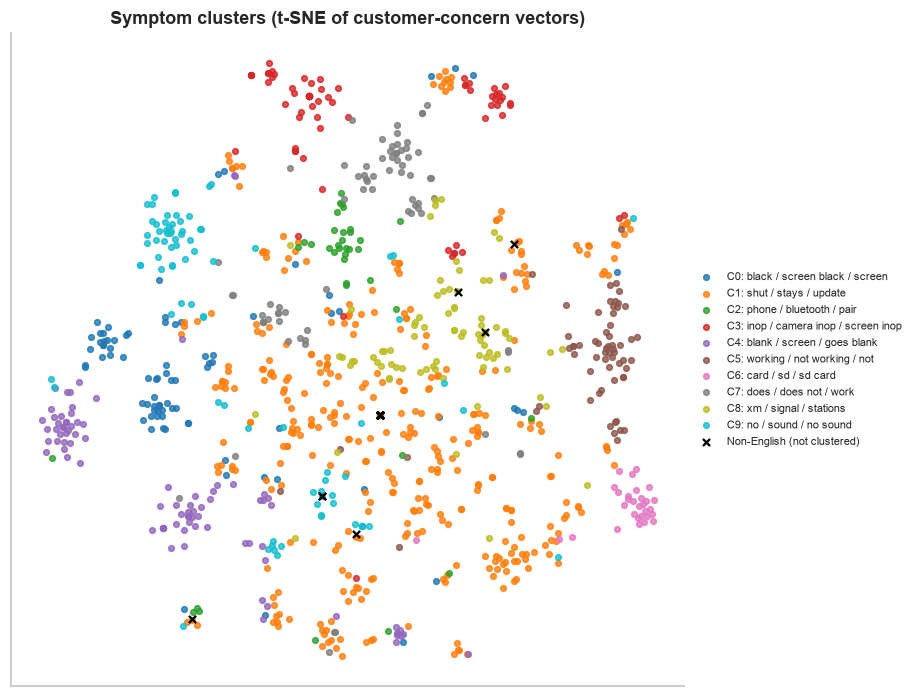

In [46]:
# 2-D map of the symptom space (t-SNE of the LSA vectors) coloured by cluster
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(Z_sym)
fig, ax = plt.subplots(figsize=(8.5, 6.5))
cmap = plt.get_cmap("tab10")
for c in range(K):
    m = (df.symptom_cluster == c).values
    ax.scatter(tsne[m, 0], tsne[m, 1], s=14, color=cmap(c), alpha=.8, label=f"C{c}: {LABEL[c]}")
ax.scatter(tsne[~is_en, 0], tsne[~is_en, 1], s=22, color="black", marker="x", label="Non-English (not clustered)")
ax.set_title("Symptom clusters (t-SNE of customer-concern vectors)"); ax.set_xticks([]); ax.set_yticks([])
ax.legend(frameon=False, fontsize=7.5, loc="center left", bbox_to_anchor=(1.0, .5))
savefig("fig12_symptom_clusters_tsne")

### 7.3 View B - repair narratives: topic model (NMF)

Non-negative matrix factorisation on TF-IDF discovers *topics* - weighted word groups - and lets one claim blend several. It is run on the **diagnosis + repair** text, because that is where root-cause language lives ("lost communication", "internal fault", "per bulletin", "coax cable", "battery voltage").

In [47]:
tf_rep = TfidfVectorizer(stop_words=STOP, token_pattern=r"[a-z]{3,}", ngram_range=(1, 2), min_df=8, max_df=0.6, sublinear_tf=True)   # (negations are not needed for repair topics)
X_rep = tf_rep.fit_transform(df.repair_text)
N_TOPICS = 7
nmf = NMF(n_components=N_TOPICS, init="nndsvda", random_state=SEED, max_iter=600)
W = nmf.fit_transform(X_rep)
rep_terms = np.array(tf_rep.get_feature_names_out())
df["repair_topic"] = W.argmax(axis=1)

rows = []
for t in range(N_TOPICS):
    top = rep_terms[np.argsort(nmf.components_[t])[::-1][:10]]
    sub = df[df.repair_topic == t]
    rows.append({"topic": t, "claims": len(sub), "share": f"{len(sub)/len(df):.0%}", "top terms": ", ".join(top),
                 "radio replaced": f"{sub.radio_replaced.mean():.0%}", "TAC escalated": f"{sub.flag_tac_escalation.mean():.0%}",
                 "top issue category": sub["Issue Category"].value_counts().index[0]})
topics = pd.DataFrame(rows).set_index("topic")
display(topics)
FACTS["topics"] = topics.reset_index().to_dict("records")

,claims,share,top terms,radio replaced,TAC escalated,top issue category
topic,,,,,,
0,150,15%,"usb, update, transfer, sps, file, usb file, file transfer, programming, software, reset",75%,39%,Radio Replaced - Cause Not Documented
1,82,8%,"failure, internal failure, internal, failure replaced, failure replace, replaced repro...",93%,22%,Radio Hardware Failure
2,81,8%,"fault, internal fault, internal, fault replaced, scan, fault replace, update, connecti...",93%,22%,Radio Hardware Failure
3,145,14%,"replace, program, replace program, scan, replace replaced, communication, test, shorte...",96%,46%,Radio Replaced - Cause Not Documented
4,177,18%,"ground, power, power ground, communication, circuits, checked, data, circuit, good, et...",90%,23%,Radio Replaced - Cause Not Documented
5,131,13%,"programmed, replaced programmed, replace replaced, programmed usb, programmed sps, cla...",96%,37%,Radio Replaced - Cause Not Documented
6,234,23%,"screen, camera, display, removed, cable, not, coax, inop, rear, test",84%,35%,Radio Replaced - Cause Not Documented


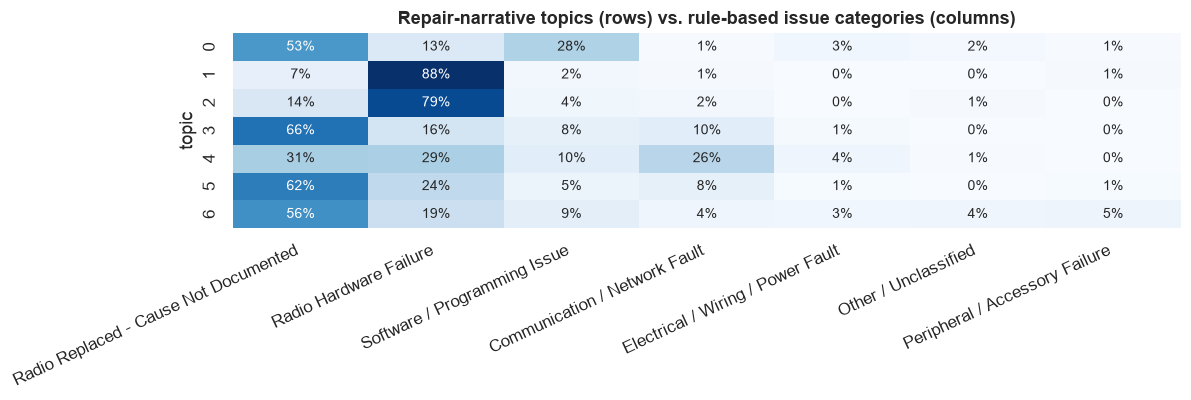

In [48]:
# How do topics relate to the rule-based issue categories?  (row-normalised: where does each topic's evidence land?)
ct = pd.crosstab(df.repair_topic, df["Issue Category"], normalize="index")[cat_counts.index]
fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(ct, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 9})
ax.set_title("Repair-narrative topics (rows) vs. rule-based issue categories (columns)"); ax.set_ylabel("topic"); ax.set_xlabel("")
plt.xticks(rotation=25, ha="right")
savefig("fig13_topics_vs_issue_category")

### 7.4 View C - semantic cross-check with sentence embeddings
TF-IDF only knows *words*; an embedding model knows that "screen goes black" and "display blanks out" mean the same thing. If the same broad groups appear under both representations, they are not artefacts of vocabulary.

In [49]:
import os
emb_ok = False
try:
    os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
    from sentence_transformers import SentenceTransformer
    st_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")          # open-source, 22M parameters, runs on CPU
    E_sym = st_model.encode(df.symptom_text[is_en].tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    emb_ok = True
except Exception as e:                                                                  # keep the notebook runnable without the model
    print("Embedding cross-check skipped:", type(e).__name__, str(e)[:120])

if emb_ok:
    en = df[is_en]
    # Choose k for the embedding view the same way (best silhouette within 5-10) and check stability + agreement with the rule-based function
    rows = []
    for k in range(5, 11):
        runs = [KMeans(n_clusters=k, n_init=10, random_state=s).fit_predict(E_sym) for s in range(4)]
        rows.append({"k": k, "silhouette": silhouette_score(E_sym, runs[0]),
                     "stability (mean ARI across seeds)": np.mean([adjusted_rand_score(runs[0], r) for r in runs[1:]]),
                     "NMI vs rule-based function": normalized_mutual_info_score(en["Affected Function"], runs[0])})
    emb_sel = pd.DataFrame(rows).set_index("k")
    display(emb_sel.round(3))
    K_EMB = int(emb_sel.silhouette.idxmax())
    km_e = KMeans(n_clusters=K_EMB, n_init=20, random_state=SEED).fit(E_sym)
    df["symptom_cluster_emb"] = -1
    df.loc[is_en, "symptom_cluster_emb"] = km_e.labels_
    emb_name = {c: f"E{c}: {df[df.symptom_cluster_emb == c]['Affected Function'].value_counts().index[0]}" for c in range(K_EMB)}
    df["Embedding Cluster"] = df.symptom_cluster_emb.map(lambda c: "Non-English" if c < 0 else emb_name[c])

    en = df[is_en]
    print(f"Chosen k for embeddings = {K_EMB}.  Agreement with the TF-IDF clustering: "
          f"ARI = {adjusted_rand_score(en.symptom_cluster, en.symptom_cluster_emb):.2f}, NMI = {normalized_mutual_info_score(en.symptom_cluster, en.symptom_cluster_emb):.2f}   (0 = unrelated, 1 = identical)")
    for name, lab in [("TF-IDF / LSA clusters", en.symptom_cluster), ("Embedding clusters", en.symptom_cluster_emb)]:
        print(f"  NMI with rule-based 'Affected Function': {name:24s} {normalized_mutual_info_score(en['Affected Function'], lab):.2f}")
    emb_profile = []
    for c in range(K_EMB):
        sub = df[df.symptom_cluster_emb == c]
        emb_profile.append({"embedding cluster": emb_name[c], "claims": len(sub), "function share": f"{sub['Affected Function'].value_counts(normalize=True).iloc[0]:.0%}",
                            "radio replaced": f"{sub.radio_replaced.mean():.0%}", "TAC escalated": f"{sub.flag_tac_escalation.mean():.0%}",
                            "example": sub.CUSTOMER_VERBATIM.iloc[0][:70]})
    display(pd.DataFrame(emb_profile).set_index("embedding cluster"))
    hub_e = df[is_en].groupby("Embedding Cluster").radio_replaced.mean()
    print(f"Radio replaced rate across embedding clusters: min {hub_e.min():.0%}, max {hub_e.max():.0%}")
    FACTS["embedding"] = {"K": int(K_EMB), "selection": emb_sel.round(3).to_dict("index"),
                          "ari_vs_tfidf": float(adjusted_rand_score(en.symptom_cluster, en.symptom_cluster_emb)),
                          "nmi_vs_tfidf": float(normalized_mutual_info_score(en.symptom_cluster, en.symptom_cluster_emb)),
                          "nmi_function_tfidf": float(normalized_mutual_info_score(en["Affected Function"], en.symptom_cluster)),
                          "nmi_function_emb": float(normalized_mutual_info_score(en["Affected Function"], en.symptom_cluster_emb)),
                          "hub_min": float(hub_e.min()), "hub_max": float(hub_e.max()), "profile": emb_profile}

W1023 09:28:18.555000 4749 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,silhouette,stability (mean ARI across seeds),NMI vs rule-based function
k,,,
5,0.049,0.817,0.376
6,0.052,0.710,0.316
7,0.060,0.738,0.337
8,0.061,0.811,0.338
9,0.058,0.660,0.335
10,0.065,0.698,0.330


Chosen k for embeddings = 10.  Agreement with the TF-IDF clustering: ARI = 0.18, NMI = 0.32   (0 = unrelated, 1 = identical)
  NMI with rule-based 'Affected Function': TF-IDF / LSA clusters    0.19
  NMI with rule-based 'Affected Function': Embedding clusters       0.35


,claims,function share,radio replaced,TAC escalated,example
embedding cluster,,,,,
E0: Display / Screen,91,60%,80%,35%,"C/S: CUSTOMER STATED STEREO SCREEN WENT BACK, NO AUDIO, STEERING WHEEL"
E1: Radio (General),50,44%,94%,44%,Customer reports that radio and screen is intermittantly inop Inspect
E2: Display / Screen,136,74%,90%,30%,C S RADIO WILL NOT COME ON SCREEN IS JUST DARK
E3: Radio (General),95,73%,89%,25%,CUSTOMER STATES THAT RADIO POWER WILL BE ON AND THERE WILL NO SOUND. P
E4: Radio (General),185,53%,90%,37%,RADIO IS INOPERABLE CHECK AND ADVISE
E5: Satellite Radio / Reception,90,84%,91%,38%,"ELECTRICAL REPAIRS, C/S that his XM radio is inop until he chances the"
E6: Radio (General),91,53%,85%,24%,"CUSTOMER STATES AFTER SHUT VEH DOWN, RADIO AND CUE SCREEN STAYS ON"
E7: Phone / Connectivity,46,91%,89%,30%,ATTN SFM - - REPAIR FOR ANDROID AUTO WILL NOT CONNECT - VERIFIED BY
E8: Camera / Video,103,92%,89%,24%,MINOR ELECTRICAL CUST STATES BACK UP CAMERA INOP INTERMITTENTLY AGAI


Radio replaced rate across embedding clusters: min 80%, max 94%


### 7.5 From clusters to root-cause hypotheses
Clusters tell us what *looks alike*. To find a potential root cause, test whether a cluster (or topic) is **over-represented in a plant, model, build week or time-in-service band** - that points to something specific about where, when or how those vehicles were built or used. Cells are flagged with the same standardised-residual test as before, plus the Bonferroni check.

In [50]:
df["tis_band"] = pd.cut(df.tis_days_valid, [-1, 90, 180, 365, 1000], labels=["0-90 d", "91-180 d", "181-365 d", ">1 yr"])
df["build_week_lbl"] = df.build_week.dt.strftime("wk %d %b")
findings = []
for target in ["symptom_cluster_label", "repair_topic"] + (["Embedding Cluster"] if emb_ok else []):
    for dim in ["BUILD_PLANT_DESC", "model_grp", "MAKE", "tis_band", "build_week_lbl", "period"]:
        res, p, cv, zb = concentration(dim, target, min_n=8, z_cut=3.0)
        if len(res):
            res = res.rename(columns={dim: "dimension value", target: "cluster/topic"}); res.insert(0, "dimension", dim); res.insert(1, "lens", target)
            findings.append(res)
        print(f"{target:22s} x {dim:17s} chi-square p={p:.3g}  V={cv:.2f}  Bonferroni z>={zb:.1f}")
conc = pd.concat(findings).sort_values("z", ascending=False) if findings else pd.DataFrame()
print("\nOver-represented cells (|z|>=3, >=8 claims):")
display(conc)
FACTS["root_cause_cells"] = conc.to_dict("records") if len(conc) else []

symptom_cluster_label  x BUILD_PLANT_DESC  chi-square p=0.594  V=0.10  Bonferroni z>=3.4
symptom_cluster_label  x model_grp         chi-square p=0.000808  V=0.15  Bonferroni z>=3.6
symptom_cluster_label  x MAKE              chi-square p=0.206  V=0.11  Bonferroni z>=3.3
symptom_cluster_label  x tis_band          chi-square p=0.438  V=0.11  Bonferroni z>=3.3
symptom_cluster_label  x build_week_lbl    chi-square p=0.13  V=0.11  Bonferroni z>=3.4
symptom_cluster_label  x period            chi-square p=0.0467  V=0.13  Bonferroni z>=3.2
repair_topic           x BUILD_PLANT_DESC  chi-square p=0.592  V=0.08  Bonferroni z>=3.3
repair_topic           x model_grp         chi-square p=0.283  V=0.13  Bonferroni z>=3.5
repair_topic           x MAKE              chi-square p=0.181  V=0.09  Bonferroni z>=3.1
repair_topic           x tis_band          chi-square p=0.279  V=0.09  Bonferroni z>=3.1
repair_topic           x build_week_lbl    chi-square p=0.211  V=0.08  Bonferroni z>=3.2
repair_topic      

,dimension,lens,dimension value,cluster/topic,claims,expected,z,survives Bonferroni
0,model_grp,Embedding Cluster,FusionNova,E8: Camera / Video,19,6.1,5.7,YES
2,model_grp,Embedding Cluster,StellarGlide,E8: Camera / Video,18,6.4,5.0,YES
0,MAKE,Embedding Cluster,NebulaCruiser,E8: Camera / Video,28,12.9,4.8,YES
0,model_grp,repair_topic,FusionNova,6,28,13.8,4.5,YES
1,period,Embedding Cluster,2021,E6: Radio (General),34,18.8,4.1,YES
1,model_grp,Embedding Cluster,HyperFury X,E8: Camera / Video,29,15.2,4.0,YES
0,model_grp,symptom_cluster_label,FusionNova,C5: working / not working / not,10,3.7,3.5,no
1,MAKE,Embedding Cluster,ThunderVolt,E4: Radio (General),112,90.3,3.5,YES
0,tis_band,Embedding Cluster,181-365 d,E8: Camera / Video,47,31.7,3.5,YES
0,period,symptom_cluster_label,2021,C1: shut / stays / update,96,75.8,3.3,YES


## 8. Synthesis: root-cause hypotheses and recommendations

Everything above is brought together here. The numbers in the table are computed from the analysis, so they update if the data does.

### 8.1 Evidence base

In [51]:
# Name the repair topics from their top terms so tables are readable (deterministic keyword rules, not hand-assigned ids)
def name_topic(top_terms):
    t = top_terms
    if "programmed" in t and "claim" in t: return "Replace + program (claim documentation)"
    if "usb" in t and "sps" in t: return "Programming path (USB file transfer / SPS)"
    if "internal failure" in t: return "Documented internal failure -> replaced"
    if "internal fault" in t: return "Internal fault found by scan -> replaced"
    if "ground" in t and "circuits" in t: return "Power / ground / data circuits tested OK -> replaced"
    if "camera" in t and "coax" in t: return "Display / camera / coax diagnostics"
    if "communication" in t and "replace" in t: return "TAC-directed replacement (communication / short)"
    return "Other"
topics["name"] = topics["top terms"].map(name_topic)
df["Repair Topic"] = df.repair_topic.map(topics["name"])
FACTS["topics"] = topics.reset_index().to_dict("records")

# Headline figures used below
rng = lambda a, b: f"{a * 100:.0f}-{b * 100:.0f}%"        # e.g. 0.84, 0.93 -> '84-93%'
upd_adj = trend.loc[trend.category == "mentions a software update", "p_adj (BH)"].iloc[0]
n = len(df)
KPI = {
    "radio_replaced": df.radio_replaced.mean(),
    "both": (df.radio_replaced & df.radio_programmed).mean(),
    "prog_only": (~df.radio_replaced & df.radio_programmed).mean(),
    "undocumented": (df["Issue Category"] == "Radio Replaced - Cause Not Documented").mean(),
    "hardware": (df["Issue Category"] == "Radio Hardware Failure").mean(),
    "software": (df["Issue Category"] == "Software / Programming Issue").mean(),
    "comm": (df["Issue Category"] == "Communication / Network Fault").mean(),
    "elec": (df["Issue Category"] == "Electrical / Wiring / Power Fault").mean(),
    "tac": df.flag_tac_escalation.mean(),
    "tac_replaced": (df.flag_tac_escalation & df.radio_replaced).sum() / df.flag_tac_escalation.sum(),
    "no_dtc_replaced": (df.radio_replaced & df.flag_no_dtc_found).mean(),
    "repeat": df["Additional Context"].str.contains("Repeat Visit").mean(),
    "parts_wait": df.flag_parts_wait.mean(),
    "early90": (df.tis_days_valid <= 90).sum() / df.tis_days_valid.notna().sum(),
    "hub_min": min(hub.radio_replaced.min(), hub_e.min() if emb_ok else 1), "hub_max": max(hub.radio_replaced.max(), hub_e.max() if emb_ok else 0),
}
cam_res, _, _, _ = concentration("model_grp", "Affected Function")
cam_models = cam_res[(cam_res["Affected Function"] == "Camera / Video") & (cam_res["survives Bonferroni"] == "YES")] if len(cam_res) else cam_res
cam_txt = ", ".join(f"{r.model_grp} ({r.claims} claims vs {r.expected:.0f} expected)" for r in cam_models.itertuples()) or "none beyond chance"
# Repair-topic concentrations that survive Bonferroni (from the section 7.5 table)
rt = conc[(conc.lens == "repair_topic") & (conc["survives Bonferroni"] == "YES")] if len(conc) else conc
rt_txt = "; ".join(f"{r['dimension value']} is over-represented in the repair topic '{topics['name'][int(r['cluster/topic'])]}' ({r.claims} vs {r.expected:.0f} expected)" for _, r in rt.iterrows())
upd_share = df.groupby("period", observed=True).mentions_update.mean()
print("Camera/video model concentration surviving Bonferroni:", cam_txt)
print("Repair-topic concentration:", rt_txt or "none surviving Bonferroni")
print("Update-related complaints by period:", {k: f"{v:.1%}" for k, v in upd_share.items()})

Camera/video model concentration surviving Bonferroni: FusionNova (18 claims vs 7 expected), HyperFury X (30 claims vs 17 expected), StellarGlide (16 claims vs 7 expected)
Repair-topic concentration: FusionNova is over-represented in the repair topic 'Display / camera / coax diagnostics' (28 vs 14 expected)
Update-related complaints by period: {'Aug-19 to Mar-20': '5.7%', 'Apr-20 to Dec-20': '2.8%', '2021': '8.2%'}


In [52]:
hyp = pd.DataFrame([
    {"#": "H1", "Root-cause hypothesis": "The radio / head-unit is the common failure point (a hub), not the individual symptoms",
     "Evidence from the data": f"{KPI['radio_replaced']:.0%} of claims end with the radio replaced - {rng(KPI['hub_min'], KPI['hub_max'])} in every symptom cluster (TF-IDF and embedding views), incl. camera, phone, satellite and display complaints; "
                               f"{KPI['hardware']:.0%} of claims explicitly document an internal radio fault; only {KPI['elec']:.0%} show an external wiring/electrical cause",
     "Confidence": "High that the radio is the remedy; medium on the failure mechanism (narratives rarely state it)"},
    {"#": "H2", "Root-cause hypothesis": "Software / firmware robustness (programming and update) contributes materially",
     "Evidence from the data": f"{KPI['software']:.0%} are classed software/programming; {KPI['prog_only']:.0%} were resolved by reprogramming WITHOUT replacing the radio; a USB/SPS programming topic covers "
                               f"{(df.repair_topic.map(topics['name']) == 'Programming path (USB file transfer / SPS)').mean():.0%} of narratives; "
                               f"complaints that mention a software update are {upd_share.iloc[1]:.0%} of claims in Apr-Dec 2020 and {upd_share.iloc[2]:.0%} in 2021 (exploratory: p={p_upd:.3f} unadjusted, {upd_adj} after correction - not significant)",
     "Confidence": "Medium for a software contribution; the 2021 update-wording rise does not survive correction"},
    {"#": "H3", "Root-cause hypothesis": "The video / rear-camera signal path on specific model lines is weaker than on others",
     "Evidence from the data": f"Camera/video complaints are over-represented in: {cam_txt}. In the independent repair text, {rt_txt or 'no topic is significantly concentrated'}. "
                               f"Yet {df[df['Affected Function'] == 'Camera / Video'].radio_replaced.mean():.0%} of camera claims are still fixed by replacing the radio",
     "Confidence": "Medium - convergent (symptom + repair text), but counts not rates"},
    {"#": "H4", "Root-cause hypothesis": "Diagnosis is not converging: radios are replaced on TAC advice without a documented cause",
     "Evidence from the data": f"{KPI['undocumented']:.0%} of claims replace the radio with no documented physical cause; {KPI['tac']:.0%} escalate to TAC/Techline and {KPI['tac_replaced']:.0%} of those end in replacement; "
                               f"{KPI['no_dtc_replaced']:.0%} replace the radio while recording no fault codes",
     "Confidence": "High that documentation is thin; unknown how many replaced radios were truly faulty"},
    {"#": "H5", "Root-cause hypothesis": "Early-life (infant-mortality) failures escape end-of-line / dealer PDI testing",
     "Evidence from the data": f"{KPI['early90']:.0%} of claims occur within 90 days of the vehicle entering service; {int(df.tis_negative.sum())} claims are even dated BEFORE the in-service date (pre-delivery repairs?)",
     "Confidence": "Medium"},
    {"#": "H7", "Root-cause hypothesis": "An emerging power-management / sleep-mode problem: the radio fails to shut down after ignition-off and drains the battery",
     "Evidence from the data": f"The ONLY change in event frequency that survives multiple-testing correction: 'stays on / battery drain' claims rise from {FACTS['stays_on']['by_quarter']['2020Q3']['share']:.0%} (2020Q3) to "
                               f"{rng(FACTS['stays_on']['by_quarter']['2021Q1']['share'], FACTS['stays_on']['by_quarter']['2021Q2']['share'])} (2021). They are {FACTS['stays_on']['after_ignition_off']:.0%} 'after ignition off', arrive later in life "
                               f"(median {FACTS['stays_on']['median_tis']:.0f} vs {FACTS['stays_on']['median_tis_rest']:.0f} days), are fixed by reprogramming alone more often ({FACTS['stays_on']['prog_only']:.0%} vs {FACTS['stays_on']['prog_only_rest']:.0%}) "
                               f"and are escalated less ({FACTS['stays_on']['tac']:.0%} vs {FACTS['stays_on']['tac_rest']:.0%})",
     "Confidence": "Medium-high that the increase is real; the mechanism (software sleep-mode vs hardware) is a hypothesis to test"},
    {"#": "H6", "Root-cause hypothesis": "Structured claim coding hides the real failure picture",
     "Evidence from the data": "The coded cause barely changes the repair or the evidence found (fig 5); coded complaint 'Communication' is mostly audio drop-outs and screen blanking, not connectivity; "
                               "a hidden non-breaking-space defect split one complaint label in two",
     "Confidence": "High"},
])
pd.set_option("display.max_colwidth", 400)
display(hyp.set_index("#"))
FACTS["hypotheses"] = hyp.to_dict("records"); FACTS["kpi"] = {k: float(v) for k, v in KPI.items()}
FACTS["camera_models"] = cam_models.to_dict("records") if len(cam_models) else []; FACTS["repair_topic_concentration"] = rt_txt

,Root-cause hypothesis,Evidence from the data,Confidence
#,,,
H1,"The radio / head-unit is the common failure point (a hub), not the individual symptoms","88% of claims end with the radio replaced - 80-94% in every symptom cluster (TF-IDF and embedding views), incl. camera, phone, satellite and display complaints; 31% of claims explicitly document an internal radio fault; only 2% show an external wiring/electrical cause",High that the radio is the remedy; medium on the failure mechanism (narratives rarely state it)
H2,Software / firmware robustness (programming and update) contributes materially,"10% are classed software/programming; 7% were resolved by reprogramming WITHOUT replacing the radio; a USB/SPS programming topic covers 15% of narratives; complaints that mention a software update are 3% of claims in Apr-Dec 2020 and 8% in 2021 (exploratory: p=0.007 unadjusted, 0.073 after correction - not significant)",Medium for a software contribution; the 2021 update-wording rise does not survive correction
H3,The video / rear-camera signal path on specific model lines is weaker than on others,"Camera/video complaints are over-represented in: FusionNova (18 claims vs 7 expected), HyperFury X (30 claims vs 17 expected), StellarGlide (16 claims vs 7 expected). In the independent repair text, FusionNova is over-represented in the repair topic 'Display / camera / coax diagnostics' (28 vs 14 expected). Yet 93% of camera claims are still fixed by replacing the radio","Medium - convergent (symptom + repair text), but counts not rates"
H4,Diagnosis is not converging: radios are replaced on TAC advice without a documented cause,46% of claims replace the radio with no documented physical cause; 33% escalate to TAC/Techline and 92% of those end in replacement; 16% replace the radio while recording no fault codes,High that documentation is thin; unknown how many replaced radios were truly faulty
H5,Early-life (infant-mortality) failures escape end-of-line / dealer PDI testing,21% of claims occur within 90 days of the vehicle entering service; 76 claims are even dated BEFORE the in-service date (pre-delivery repairs?),Medium
H7,An emerging power-management / sleep-mode problem: the radio fails to shut down after ignition-off and drains the battery,"The ONLY change in event frequency that survives multiple-testing correction: 'stays on / battery drain' claims rise from 1% (2020Q3) to 11-12% (2021). They are 57% 'after ignition off', arrive later in life (median 309 vs 226 days), are fixed by reprogramming alone more often (11% vs 7%) and are escalated less (13% vs 34%)",Medium-high that the increase is real; the mechanism (software sleep-mode vs hardware) is a hypothesis to test
H6,Structured claim coding hides the real failure picture,"The coded cause barely changes the repair or the evidence found (fig 5); coded complaint 'Communication' is mostly audio drop-outs and screen blanking, not connectivity; a hidden non-breaking-space defect split one complaint label in two",High


### 8.2 Recommendations and business impact

| # | Action | Why (evidence) | Business impact | Priority |
|---|---|---|---|---|
| R1 | **Failure-analyse returned radios** (teardown a stratified sample: documented-fault, undocumented, camera-complaint, update-failure) with the supplier; open an 8D on the head-unit | H1, H4 | The single largest cost driver: radio replacement is ~9 in 10 claims. Every 10% cut in radio replacements removes ~9 replacements per 100 claims | **1** |
| R2 | **Software-first, verify-before-replace workflow**: a guided recovery/reflash path and a mandatory "re-test after reprogram" step before authorising a unit swap | H2, H4 | ~7% of claims are already resolved by programming alone; converting even a fraction of "cause not documented" claims avoids hardware + labour | **1** |
| R3 | **Standardise diagnostic evidence**: require DTC/circuit-test results and a failure code on every replacement; give TAC a decision tree | H4 | Enables supplier chargebacks (you can only recover cost when failure is documented), shrinks "no fault found" returns, and makes the next analysis far sharper | **1** |
| R4 | **Contain the emerging "radio stays on / battery drain" issue**: check against software-release and bulletin dates, measure key-off current draw on affected vehicles, and add a power-down/sleep test to the software validation suite | H7 | The one trend that is statistically real (about 11% of 2021 claims, up from 2-4%); flat batteries are a high-annoyance, high-visibility failure | **1** |
| R5 | **Targeted investigation of the camera/video path** on the over-represented models (compare video-processing module, coax/LVDS harness, radio part numbers vs. unaffected models) | H3 | Contains a model-specific defect before it spreads; cheaper than a fleet-wide action | 2 |
| R6 | **Strengthen end-of-line / PDI functional test** for display, camera, Bluetooth pairing, satellite radio and update-readiness | H5 | Catches early-life failures that surface in the first 90 days (the largest age band) | 2 |
| R7 | **Fix data capture and add monitoring**: structured fields (component, symptom, trigger, fix) at repair time; clean label sets; keep DTC and part numbers (stripped in this export); fix the non-breaking-space and placeholder defects; run this pipeline weekly with the control chart and a tag-share alert | H6 | Turns this notebook's NLP into a continuous, cheaper early-warning loop (it would have flagged H7 as it started) | 2 |
| R8 | **Customer experience**: stock radios at dealers for the high-volume models, offer loaners when parts are on order, flag repeat visits for escalation | ~9% repeat visits, ~8% waiting for parts | Lower repeat-repair cost and better satisfaction | 3 |

**Sizing the prize.** The dataset has no cost fields, so impact is expressed in **replacements avoided per 1,000 claims**. The table lets you plug in your own average cost; the three cost levels shown are *illustrative assumptions, not values from the data*.

In [53]:
# What-if: how many radio replacements (and how much money, under ASSUMED unit costs) does each reduction avoid per 1,000 claims?
base_replacements = KPI["radio_replaced"] * 1000
scen = []
for red in (0.05, 0.10, 0.20):
    row = {"reduction in radio replacements": f"{red:.0%}", "replacements avoided / 1,000 claims": round(base_replacements * red)}
    for cost in (500, 800, 1200):                                   # <- ILLUSTRATIVE average cost per radio replacement (parts + labour). Replace with your actual figure.
        row[f"saving @ ${cost:,} each"] = f"${base_replacements * red * cost:,.0f}"
    scen.append(row)
display(pd.DataFrame(scen).set_index("reduction in radio replacements"))
FACTS["whatif"] = scen; FACTS["baseline_replacements_per_1000"] = float(base_replacements)
print(f"Baseline: about {base_replacements:.0f} radio replacements per 1,000 claims.  ($ columns are illustrative assumptions - not derived from this dataset.)")

,"replacements avoided / 1,000 claims",saving @ $500 each,saving @ $800 each,"saving @ $1,200 each"
reduction in radio replacements,,,,
5%,44,"$22,075","$35,320","$52,980"
10%,88,"$44,150","$70,640","$105,960"
20%,177,"$88,300","$141,280","$211,920"


Baseline: about 883 radio replacements per 1,000 claims.  ($ columns are illustrative assumptions - not derived from this dataset.)


## 9. Export - the tagged dataset

Two files are written next to the notebook:

* `task2_tagged_dataset.csv` - one row per claim: the original fields, the **extracted tags** (same six columns and list format as the provided examples), the issue category, flags and cluster/topic assignments.
* `task2_tagged_dataset.xlsx` - the same data with the extracted tags **colour-highlighted**, plus supporting sheets (tag vocabulary, issue categories, cluster summary, validation, QA log, data dictionary).

In [54]:
# Assemble the output frame in a deliberate column order (identifiers -> raw text -> extracted tags -> classification -> clusters -> flags)
for c in ["opened_date", "build_date", "in_use_date"]:
    df[c + "_str"] = df[c].dt.strftime("%Y-%m-%d")
df["Time in service (days)"] = df.tis_days_valid
cluster_cols = ["symptom_cluster_label"] + (["Embedding Cluster"] if emb_ok else []) + ["Repair Topic"]
FLAG_OUT = ["radio_replaced", "radio_programmed"] + flag_cols
out_cols = (["Event id", "opened_date_str", "build_date_str", "in_use_date_str", "Time in service (days)", "BUILD_PLANT_DESC", "MAKE", "MODEL", "COMPLAINT_CD_DESC", "CAUSAL_CD_DESC",
             "CUSTOMER_VERBATIM", "CAUSAL_VERBATIM", "CORRECTION_VERBATIM"]
            + ["Trigger", "Failure Component", "Failure Condition", "Additional Context", "Fix Component", "Fix Condition", "Failure Pairs", "Fix Pairs"]
            + ["Issue Category", "Issue Evidence", "Affected Function"] + cluster_cols
            + FLAG_OUT + ["Language", "customer_placeholder", "tis_negative", "in_use_imputed", "causal_missing", "has_provided_example"])
final = df[out_cols].rename(columns={"opened_date_str": "Opened date", "build_date_str": "Build date", "in_use_date_str": "In-service date",
                                      "symptom_cluster_label": "Symptom Cluster (TF-IDF/K-Means)", "BUILD_PLANT_DESC": "Build plant",
                                      "COMPLAINT_CD_DESC": "Coded complaint", "CAUSAL_CD_DESC": "Coded cause"}).copy()
final.to_csv("task2_tagged_dataset.csv", index=False)
print("task2_tagged_dataset.csv ->", final.shape)
final.head(3).T.head(34)

task2_tagged_dataset.csv -> (1000, 47)


,0,1,2
Event id,D-14801,D-14869,D-14555
Opened date,2019-09-17,2020-07-06,2020-01-09
Build date,2019-08-14,2019-08-16,2019-08-06
In-service date,2019-09-10,2020-03-26,2019-11-29
Time in service (days),7.0,102.0,41.0
Build plant,Flint,Fort Wayne,Flint
MAKE,NovaSprint,NebulaCruiser,ThunderVolt
MODEL,AeroSpecter,StellarGlide,HyperFury X
Coded complaint,Audio/Entertainment/Navigation - Other issues,Audio/Entertainment/Navigation - Other issues,Audio/Entertainment/Navigation - Other issues
Coded cause,Module/Component-No/Incorrect Communication,Module/Component-Shorted,Module/Component-Worn/Stripped


In [55]:
# ---- supporting sheets ---------------------------------------------------------------------------------------------------
def vocab_table(pairs_series, which, desc):
    L = explode_pairs(pairs_series)
    key = which
    t = L[["row", key]].drop_duplicates().groupby(key).size().sort_values(ascending=False).rename("claims").to_frame()
    t["% of claims"] = (t.claims / len(df) * 100).round(1)
    t["tag type"] = desc
    return t.reset_index().rename(columns={key: "label"})

vocab = pd.concat([
    vocab_table(M.fail_pairs, "component", "Failure Component"), vocab_table(M.fail_pairs, "condition", "Failure Condition"),
    vocab_table(M.fix_pairs, "component", "Fix Component"), vocab_table(M.fix_pairs, "condition", "Fix Condition"),
    pd.Series([t for ts in M.trig for t in ts]).value_counts().rename("claims").rename_axis("label").reset_index().assign(**{"tag type": "Trigger"}).assign(**{"% of claims": lambda d: (d.claims / len(df) * 100).round(1)}),
    pd.Series([c for cs in M.ctx for c in cs]).value_counts().rename("claims").rename_axis("label").reset_index().assign(**{"tag type": "Additional Context"}).assign(**{"% of claims": lambda d: (d.claims / len(df) * 100).round(1)}),
])[["tag type", "label", "claims", "% of claims"]]

issue_defs = pd.DataFrame({
    "Issue Category": ISSUE_CATEGORIES,
    "Definition (evidence required)": [
        "Explicit statement of internal fault / short / defective / failed radio",
        "Documented loss of communication / data-bus fault, no stronger cause",
        "Software/update/bulletin cause cited, or reprogramming alone resolved it",
        "Wiring/connector/coax repaired or replaced, or documented corrosion/chafing/open/short/battery drain",
        "A non-radio part (camera, antenna, USB port, display, speaker...) replaced/repaired and the radio kept",
        "Could-not-duplicate and no repair action",
        "Radio replaced but the narrative gives no physical cause (typically 'per TAC')",
        "None of the above"]}).merge(df["Issue Category"].value_counts().rename("claims").rename_axis("Issue Category").reset_index(), how="left").fillna({"claims": 0})
issue_defs["claims"] = issue_defs.claims.astype(int); issue_defs["% of claims"] = (issue_defs.claims / len(df) * 100).round(1)

validation = val_scores.round(2).reset_index().rename(columns={"index": "tag column"})
validation["note"] = "Computed on the 5 provided example rows only - indicative, not a statistical accuracy estimate"

data_dict = pd.DataFrame([
    ("Event id ... Coded cause", "Original structured fields (cleaned: whitespace normalised, dates ISO)", "source"),
    ("CUSTOMER_VERBATIM / CAUSAL_VERBATIM / CORRECTION_VERBATIM", "Original free-text narratives (unchanged)", "source"),
    ("Trigger, Failure Component, Failure Condition, Additional Context, Fix Component, Fix Condition", "EXTRACTED TAGS - same columns/list format as the provided examples. Components and conditions are ALIGNED lists (i-th component pairs with i-th condition)", "text mining (highlighted yellow)"),
    ("Failure Pairs / Fix Pairs", "The same tags as readable 'component: condition' pairs", "text mining"),
    ("Issue Category / Issue Evidence", "Type of issue and the evidence rule(s) that matched", "rules on mined entities (green)"),
    ("Affected Function", "What the customer notices (camera, display, satellite radio, ...)", "rules on mined entities (green)"),
    ("Symptom Cluster / Embedding Cluster / Repair Topic", "Unsupervised groupings (K-Means on LSA, K-Means on MiniLM embeddings, NMF topic)", "ML (blue)"),
    ("flag_*", "Binary evidence flags (TAC escalation, DTC mentioned, bulletin cited, internal failure, ...)", "text mining (grey)"),
    ("radio_replaced / radio_programmed", "Radio replaced / reprogrammed (incl. via SPS or USB transfer)", "text mining (grey)"),
    ("Language", "English / Spanish / French (marker-count guess)", "text mining (grey)"),
    ("customer_placeholder, tis_negative, in_use_imputed, causal_missing", "Data-quality flags (see QA Log)", "cleaning"),
    ("has_provided_example", "TRUE for the 5 rows whose example tags were supplied with the assignment", "source"),
], columns=["column(s)", "meaning", "origin"])

cluster_sheet = cluster_profile.reset_index()
topic_sheet = topics.reset_index()[["topic", "name", "claims", "share", "top terms", "radio replaced", "TAC escalated", "top issue category"]]
qa_sheet = pd.DataFrame(qa_log)

In [56]:
# ---- write the formatted workbook --------------------------------------------------------------------------------------
from openpyxl.styles import PatternFill, Font, Alignment, Border, Side
from openpyxl.utils import get_column_letter

FILL = {"meta": "D9DEE7", "text": "EEF1F5", "tags": "FFF2B3", "class": "D6EBD7", "cluster": "D3E4F6", "flags": "E7E7E7"}
group_of = {}
for c in final.columns:
    if c in ("Trigger", "Failure Component", "Failure Condition", "Additional Context", "Fix Component", "Fix Condition", "Failure Pairs", "Fix Pairs"): group_of[c] = "tags"
    elif c in ("Issue Category", "Issue Evidence", "Affected Function"): group_of[c] = "class"
    elif c in ("Symptom Cluster (TF-IDF/K-Means)", "Embedding Cluster", "Repair Topic"): group_of[c] = "cluster"
    elif c.endswith("_VERBATIM"): group_of[c] = "text"
    elif c in FLAG_OUT + ["Language", "customer_placeholder", "tis_negative", "in_use_imputed", "causal_missing", "has_provided_example"]: group_of[c] = "flags"
    else: group_of[c] = "meta"

with pd.ExcelWriter("task2_tagged_dataset.xlsx", engine="openpyxl") as xw:
    final.to_excel(xw, sheet_name="Tagged Data", index=False)
    vocab.to_excel(xw, sheet_name="Tag Vocabulary", index=False)
    issue_defs.to_excel(xw, sheet_name="Issue Categories", index=False)
    cluster_sheet.to_excel(xw, sheet_name="Clusters", index=False)
    topic_sheet.to_excel(xw, sheet_name="Repair Topics", index=False)
    validation.to_excel(xw, sheet_name="Validation (5 examples)", index=False)
    qa_sheet.to_excel(xw, sheet_name="QA Log", index=False)
    data_dict.to_excel(xw, sheet_name="Data Dictionary", index=False)
    thin = Side(style="thin", color="C8CDD6")
    for ws in xw.book.worksheets:
        ws.freeze_panes = "B2" if ws.title == "Tagged Data" else "A2"
        ws.auto_filter.ref = ws.dimensions
        for j, cell in enumerate(ws[1], start=1):
            grp = group_of.get(cell.value, "meta") if ws.title == "Tagged Data" else "meta"
            cell.fill = PatternFill("solid", fgColor=FILL[grp]); cell.font = Font(bold=True, color="1F2937")
            cell.alignment = Alignment(wrap_text=True, vertical="center"); cell.border = Border(bottom=thin)
            width = 14
            if ws.title == "Tagged Data":
                width = 60 if cell.value.endswith("_VERBATIM") else 34 if cell.value in ("Failure Component", "Failure Condition", "Fix Component", "Fix Condition", "Failure Pairs", "Fix Pairs", "Issue Category", "Symptom Cluster (TF-IDF/K-Means)", "Embedding Cluster", "Repair Topic", "Coded complaint", "Coded cause") else 24 if cell.value in ("Trigger", "Additional Context", "Issue Evidence", "Affected Function", "Build plant") else 13
            else:
                width = 46 if ws.title in ("Issue Categories", "Tag Vocabulary", "Data Dictionary", "QA Log", "Clusters", "Repair Topics") and j <= 2 else 18
            ws.column_dimensions[get_column_letter(j)].width = width
        if ws.title == "Tagged Data":
            tag_cols = [j for j, cell in enumerate(ws[1], start=1) if group_of.get(cell.value) in ("tags", "class", "cluster")]
            for row in ws.iter_rows(min_row=2):
                for j in tag_cols:
                    row[j - 1].fill = PatternFill("solid", fgColor=FILL[group_of[ws.cell(1, j).value]])
        elif ws.title in ("Data Dictionary", "QA Log", "Issue Categories", "Clusters", "Repair Topics"):
            for row in ws.iter_rows(min_row=2):
                for cell in row:
                    cell.alignment = Alignment(wrap_text=True, vertical="top")
    legend = xw.book.create_sheet("Legend", 0)
    legend["A1"] = "How to read the 'Tagged Data' sheet"
    legend["A1"].font = Font(bold=True, size=13)
    for i, (grp, desc) in enumerate([("tags", "EXTRACTED TAGS (text mining) - Trigger, Failure Component/Condition, Additional Context, Fix Component/Condition (+ readable pairs)"),
                                     ("class", "Issue Category / Evidence / Affected Function (rules on the mined entities)"),
                                     ("cluster", "Unsupervised groupings (K-Means symptom cluster, embedding cluster, NMF repair topic)"),
                                     ("flags", "Binary flags and data-quality markers"), ("text", "Original free-text narratives"), ("meta", "Original structured fields (cleaned)")], start=3):
        legend.cell(i, 1).fill = PatternFill("solid", fgColor=FILL[grp]); legend.cell(i, 2, desc)
    legend.column_dimensions["A"].width = 6; legend.column_dimensions["B"].width = 130
    legend["B10"] = "Components and conditions are ALIGNED lists: the i-th component pairs with the i-th condition (e.g. ['Radio','Display'] with ['Inoperative','Black Screen'])."
    legend["B11"] = "Rows with has_provided_example = TRUE carry extractor output; the originally supplied example tags are compared with it in the 'Validation' sheet."
print("task2_tagged_dataset.xlsx written:", [ws for ws in ["Legend", "Tagged Data", "Tag Vocabulary", "Issue Categories", "Clusters", "Repair Topics", "Validation (5 examples)", "QA Log", "Data Dictionary"]])

task2_tagged_dataset.xlsx written: ['Legend', 'Tagged Data', 'Tag Vocabulary', 'Issue Categories', 'Clusters', 'Repair Topics', 'Validation (5 examples)', 'QA Log', 'Data Dictionary']


## 10. Key learnings, limitations and next steps

**What worked**

* A **transparent lexicon + clause-pairing extractor** produced the same six tag columns as the examples for all 1,000 claims, with fully auditable rules. Reading the five worked examples carefully was what defined a usable tag vocabulary.
* **Evidence-based taxonomy beat the coded fields.** The structured complaint/cause codes did not predict what technicians found or fixed; the narratives did.
* **Cross-method agreement** gave confidence: both symptom text and repair text point to the same model lines for camera/video, and embedding clusters reproduce the rule-based functions better (higher NMI) than TF-IDF alone.
* **Statistical discipline mattered.** Most visually tempting patterns (plant differences, time trends, time-in-service by issue) disappeared after Benjamini-Hochberg / Bonferroni correction. Reporting only what survives is what keeps the recommendations honest.

**Limitations (read before acting on any number)**

1. **No denominators** - counts, not rates. A model with many claims may simply have been built in greater numbers.
2. **Tag accuracy is only lightly validated**: five labelled rows (F1 ~0.5-1.0 by tag type) plus agreement with the coded complaint and a human spot-check sample. The example labels are themselves subjective (e.g. `Controls Irresponsive` vs `Inoperative`), so a low score on them is not necessarily an error.
3. **Narratives are truncated and stripped** (numbers/DTC codes/part numbers removed, line-breaks lost), which limits root-cause depth. "Cause not documented" describes the *text*, not necessarily the technician's knowledge.
4. **One production cohort** (MY2020, built Aug-Sep 2019): findings may not generalise to other model years.
5. Cluster silhouette scores are low (~0.1), typical for short text; clusters are a lens, not hard classes.

**Further improvements**

* Use an **open-source LLM** (e.g. a 7-8B instruction model run locally) with the five examples as few-shot prompts to extract tags, then compare against the lexicon extractor and keep the union where they agree - the lexicon output here is a ready-made baseline and a source of silver labels.
* **Label 200-300 claims** by domain experts, then fine-tune a token-classification model (e.g. DistilBERT) and report real precision/recall.
* Join **production volumes, supplier lot/part numbers and returned-part teardown results** so rates, supplier effects and true root causes become measurable.
* Add **survival / Weibull analysis** once fleet size is known, to forecast warranty exposure by months-in-service.
* Run this pipeline **weekly** with the control chart and topic-share alerts (R5, R7) so changes such as the rise in update failures are caught as they happen.

In [57]:
# ---- Persist every number quoted in the report so the report can never drift from the analysis --------------------------------
FACTS["qa_log"] = qa_log
FACTS["tag_vocabulary"] = vocab.to_dict("records")
FACTS["n_claims"] = int(len(df))
with open(OUT / "task2_facts.json", "w") as fh:
    json.dump(FACTS, fh, indent=1, default=str)
print("Wrote", OUT / "task2_facts.json", "with", len(FACTS), "top-level entries")

Wrote outputs/task2_facts.json with 40 top-level entries
